## Local Setup

In [1]:
!pip install numpy pandas scipy matplotlib scikit-learn tslearn stumpy tqdm jupyter

!git clone https://github.com/TheDatumOrg/TSB-UAD.git external/TSB-UAD
!pip install -e external/TSB-UAD --no-build-isolation


fatal: destination path 'external/TSB-UAD' already exists and is not an empty directory.


Obtaining file:///C:/Users/vaspn/Downloads/Streamify-Time-Series-Anomaly-Detection-Methods/notebooks/external/TSB-UAD
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Attempting uninstall: TSB_UAD
    Found existing installation: TSB_UAD 0.0.3
    Uninstalling TSB_UAD-0.0.3:
      Successfully uninstalled TSB_UAD-0.0.3
  Running setup.py develop for TSB_UAD


  DEPRECATION: Legacy editable install of TSB_UAD==0.0.3 from file:///C:/Users/vaspn/Downloads/Streamify-Time-Series-Anomaly-Detection-Methods/notebooks/external/TSB-UAD (setup.py develop) is deprecated. pip 25.3 will enforce this behaviour change. A possible replacement is to add a pyproject.toml or enable --use-pep517, and use setuptools >= 64. If the resulting installation is not behaving as expected, try using --config-settings editable_mode=compat. Please consult the setuptools documentation for more information. Discussion can be found at https://github.com/pypa/pip/issues/11457


In [2]:
import sys, os
tsb_path = os.path.join(os.getcwd(), "external", "TSB-UAD")
if tsb_path not in sys.path:
    sys.path.insert(0, tsb_path)


In [3]:
import os
from pathlib import Path

# Auto-detect project root
_here = Path(os.getcwd())
PROJECT_ROOT = _here.parent if _here.name == "notebooks" else _here

RAW_DATA_DIR = str(PROJECT_ROOT / "data" / "raw" / "TSB-UAD-Public")
NORMALITIES_DIR = str(PROJECT_ROOT / "data" / "normalities")
METRICS_DIR     = str(PROJECT_ROOT / "results" / "metrics")
PLOTS_DIR       = str(PROJECT_ROOT / "results" / "figures")

for d in [RAW_DATA_DIR, NORMALITIES_DIR, METRICS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data:     {RAW_DATA_DIR}")
print(f"Normalities:  {NORMALITIES_DIR}")
print(f"Metrics:      {METRICS_DIR}")
print(f"Plots:        {PLOTS_DIR}")


Project root: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods
Raw data:     c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\raw\TSB-UAD-Public
Normalities:  c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities
Metrics:      c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\results\metrics
Plots:        c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\results\figures


## Import Libraries

In [4]:
# TSB-UAD
from TSB_UAD.models.iforest import IForest
from TSB_UAD.models.ocsvm import OCSVM
from TSB_UAD.models.lstm import lstm
from TSB_UAD.models.distance import Fourier
from TSB_UAD.models.feature import Window
from TSB_UAD.utils.slidingWindows import find_length
from TSB_UAD.vus.metrics import get_metrics
from TSB_UAD.utils.visualisation import plotFig

# Scikit-learn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import pairwise_distances
from sklearn.cluster import KMeans

# NumPy
import numpy as np
from numpy.linalg import norm, eigh
from numpy.fft import fft, ifft

# Time series (SAND algorithm)
import stumpy
from tslearn.clustering import KShape
from tslearn.metrics import y_shifted_sbd_vec
from tslearn.utils import to_time_series_dataset, to_time_series

# Data & Visualization
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Standard library
import time
import gc
import tensorflow as tf
import os
import math
from tqdm import tqdm

## **Concatenate Time Series from Different Domains**

### Normality 1

In [5]:
ecg = pd.read_csv(f'{RAW_DATA_DIR}/ECG/MBA_ECG805_data.out', header=None)
yahoo = pd.read_csv(f'{RAW_DATA_DIR}/YAHOO/YahooA3Benchmark-TS42_data.out', header=None)
occupancy = pd.read_csv(f'{RAW_DATA_DIR}/Occupancy/room-occupancy.train.csv@5.out', header=None)
dodgers = pd.read_csv(f'{RAW_DATA_DIR}/Dodgers/101-freeway-traffic.test.out', header=None)
smap = pd.read_csv(f'{RAW_DATA_DIR}/NASA-SMAP/T-3.test.out', header=None)
msl = pd.read_csv(f'{RAW_DATA_DIR}/NASA-MSL/T-13.test.out', header=None)
smd = pd.read_csv(f'{RAW_DATA_DIR}/SMD/machine-3-11.test.csv@35.out', header=None)
mgab = pd.read_csv(f'{RAW_DATA_DIR}/MGAB/1.test.out', header=None)
kdd21 = pd.read_csv(f'{RAW_DATA_DIR}/KDD21/148_UCR_Anomaly_Lab2Cmac011215EPG4_6000_17390_17520.out', header=None)
ghl = pd.read_csv(f'{RAW_DATA_DIR}/GHL/01_Lev_fault_Temp_corr_seed_11_vars_23.test.csv@4.out', header=None)
sensorscope = pd.read_csv(f'{RAW_DATA_DIR}/SensorScope/stb-2.test.out', header=None)

In [13]:
# Save N1 datasets to normalities folder
N1_FILES = {
    'yahoo':   yahoo,
    'dodgers': dodgers,
    'mgab':    mgab,
    'ecg':     ecg,
}
for name, df in N1_FILES.items():
    _out = f'{NORMALITIES_DIR}/{name}.csv'
    if not os.path.exists(_out):
        df.to_csv(_out, index=False, header=False)
        print(f'Saved: {name}.csv')
    else:
        print(f'Cached: {name}.csv')

Cached: yahoo.csv
Cached: dodgers.csv
Cached: mgab.csv
Cached: ecg.csv


### Normality 2

In [14]:
_out = f'{NORMALITIES_DIR}/kdd21_yahoo.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    kdd21_yahoo_df = pd.concat([kdd21, yahoo], ignore_index=True)
    kdd21_yahoo_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    kdd21_yahoo_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/kdd21_yahoo.csv


In [15]:
_out = f'{NORMALITIES_DIR}/ecg_mgab.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    ecg_mgab_df = pd.concat([ecg, mgab], ignore_index=True)
    ecg_mgab_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    ecg_mgab_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/ecg_mgab.csv


### Normality 3

In [16]:
_out = f'{NORMALITIES_DIR}/ghl_mgab_sensorscope.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    ghl_mgab_sensorscope_df = pd.concat([ghl, mgab, sensorscope], ignore_index=True)
    ghl_mgab_sensorscope_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    ghl_mgab_sensorscope_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/ghl_mgab_sensorscope.csv


In [17]:
_out = f'{NORMALITIES_DIR}/smap_msl_smd.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    smap_msl_smd_df = pd.concat([smap, msl, smd], ignore_index=True)
    smap_msl_smd_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    smap_msl_smd_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/smap_msl_smd.csv


### Normality 4

In [18]:
_out = f'{NORMALITIES_DIR}/ecg_occupancy_dodgers_yahoo.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    ecg_occupancy_dodgers_yahoo_df = pd.concat([ecg, occupancy, dodgers, yahoo], ignore_index=True)
    ecg_occupancy_dodgers_yahoo_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    ecg_occupancy_dodgers_yahoo_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/ecg_occupancy_dodgers_yahoo.csv


### Normality 5

In [19]:
_out = f'{NORMALITIES_DIR}/msl_smap_mgab_dodgers_sensorscope.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    msl_smap_mgab_dodgers_sensorscope_df = pd.concat([msl, smap, mgab, dodgers, sensorscope], ignore_index=True)
    msl_smap_mgab_dodgers_sensorscope_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    msl_smap_mgab_dodgers_sensorscope_df = pd.read_csv(_out, header=None)
    print(f"✓ Loaded cached: {_out}")


✓ Loaded cached: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods\data\normalities/msl_smap_mgab_dodgers_sensorscope.csv


## **Read and Explore Generated Data**

### Read Generated Data

In [20]:
# Normality 1
yahoo_df = pd.read_csv(f'{RAW_DATA_DIR}/YAHOO/YahooA3Benchmark-TS42_data.out', header=None)
dodgers_df = pd.read_csv(f'{RAW_DATA_DIR}/Dodgers/101-freeway-traffic.test.out', header=None)
mgab_df = pd.read_csv(f'{RAW_DATA_DIR}/MGAB/1.test.out', header=None)
ecg_df = pd.read_csv(f'{RAW_DATA_DIR}/ECG/MBA_ECG805_data.out', header=None)

# Normality 2
kdd21_yahoo_df = pd.read_csv(f'{NORMALITIES_DIR}/kdd21_yahoo.csv', header=None)
ecg_mgab_df = pd.read_csv(f'{NORMALITIES_DIR}/ecg_mgab.csv', header=None)

# Normality 3
ghl_mgab_sensorscope_df = pd.read_csv(f'{NORMALITIES_DIR}/ghl_mgab_sensorscope.csv', header=None)
smap_msl_smd_df = pd.read_csv(f'{NORMALITIES_DIR}/smap_msl_smd.csv', header=None)

# Normality 4
ecg_occupancy_dodgers_yahoo_df = pd.read_csv(f'{NORMALITIES_DIR}/ecg_occupancy_dodgers_yahoo.csv', header=None)

# Normality 5
msl_smap_mgab_dodgers_sensorscope_df = pd.read_csv(f'{NORMALITIES_DIR}/msl_smap_mgab_dodgers_sensorscope.csv', header=None)

In [21]:
datasets = [
    ("yahoo", 1, yahoo_df),
    ("dodgers", 1, dodgers_df),
    ("mgab", 1, mgab_df),
    ("ecg", 1, ecg_df),
    ("kdd21_yahoo", 2, kdd21_yahoo_df),
    ("ecg_mgab", 2, ecg_mgab_df),
    ("ghl_mgab_sen", 3, ghl_mgab_sensorscope_df),
    ("smap_msl_smd", 3, smap_msl_smd_df),
    ("ecg_occ_dod_yahoo", 4, ecg_occupancy_dodgers_yahoo_df),
    ("msl_smap_mgab_dod_sen", 5, msl_smap_mgab_dodgers_sensorscope_df),
]

### Print Data Details

In [22]:
summary_data = []
info_data = []

for file_name, file_normality, df in datasets:
    nan = df.isna().sum().sum()             # Number of Nan values
    length = df.shape[0]                    # Lenght of file
    anomalies = (df[1] == 1).sum()          # Number of anomalies in file
    anomaly_per = (df[1] == 1).mean() * 100 # Percentage of anomalies in file

    info_data.append({
        "file name": file_name,
        "file normality": file_normality,
        "NaN": nan,
        "length": length,
        "anomalies": anomalies,
        "anomaly percentage": f"{anomaly_per:.2f}%"
    })

info_df = pd.DataFrame(info_data)
info_df

,file name,file normality,NaN,length,anomalies,anomaly percentage
0,yahoo,1,0,1680,16,0.95%
1,dodgers,1,0,50400,5612,11.13%
2,mgab,1,0,100000,200,0.20%
3,ecg,1,0,230400,20200,8.77%
4,kdd21_yahoo,2,0,31746,146,0.46%
5,ecg_mgab,2,0,330400,20400,6.17%
6,ghl_mgab_sen,3,0,329554,4121,1.25%
7,smap_msl_smd,3,0,39705,634,1.60%
8,ecg_occ_dod_yahoo,4,0,290623,27557,9.48%
9,msl_smap_mgab_dod_sen,5,0,190962,10025,5.25%


### Plot Details

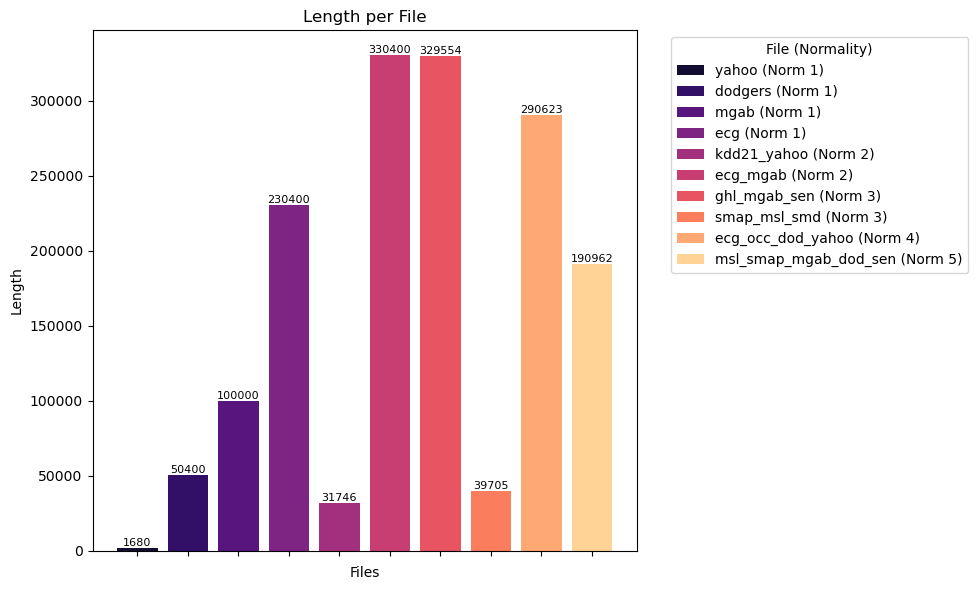

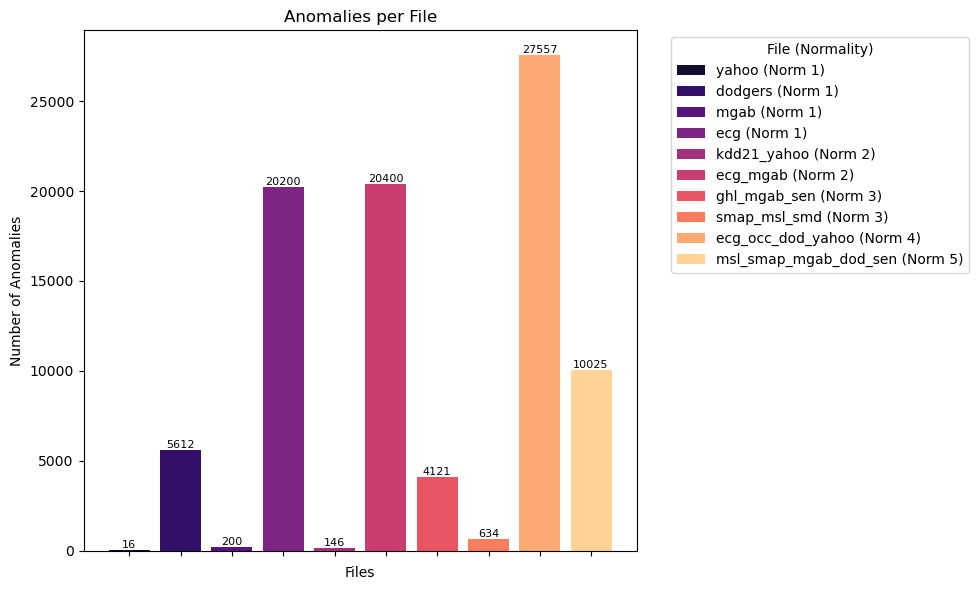

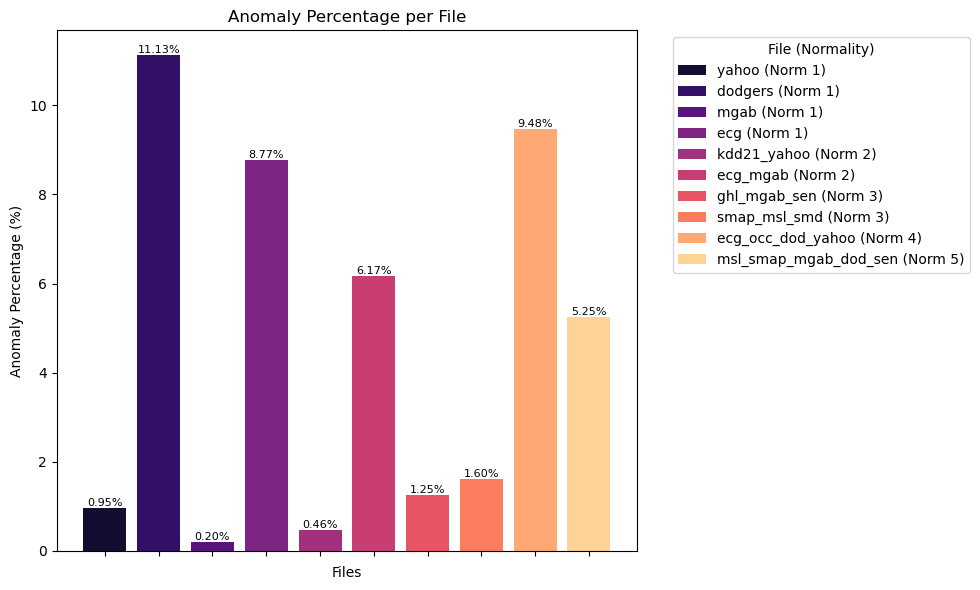

In [16]:
colors = sns.color_palette("magma", n_colors=len(info_df))

# Plot 1: Length per File
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(info_df['file name'], info_df['length'], color=colors)
ax.set_xlabel('Files')
ax.set_ylabel('Length')
ax.set_title('Length per File')
ax.set_xticklabels([])
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', fontsize=8)
legend_labels = [f"{row['file name']} (Norm {row['file normality']})" for _, row in info_df.iterrows()]
ax.legend(bars, legend_labels, title="File (Normality)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()


os.makedirs(PLOTS_DIR, exist_ok=True)
fig.savefig(f'{PLOTS_DIR}/eda_file_length.png', bbox_inches='tight', dpi=150)

# Plot 2: Number of Anomalies per File
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(info_df['file name'], info_df['anomalies'], color=colors)
ax.set_xlabel('Files')
ax.set_ylabel('Number of Anomalies')
ax.set_title('Anomalies per File')
ax.set_xticklabels([])
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', fontsize=8)
ax.legend(bars, legend_labels, title="File (Normality)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()


fig.savefig(f'{PLOTS_DIR}/eda_anomalies.png', bbox_inches='tight', dpi=150)

# Plot 3: Anomaly Percentage per File
info_df['anomaly percentage'] = info_df['anomaly percentage'].str.replace('%', '').astype(float)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(info_df['file name'], info_df['anomaly percentage'], color=colors)
ax.set_xlabel('Files')
ax.set_ylabel('Anomaly Percentage (%)')
ax.set_title('Anomaly Percentage per File')
ax.set_xticklabels([])
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}%', ha='center', va='bottom', fontsize=8)
ax.legend(bars, legend_labels, title="File (Normality)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

fig.savefig(f'{PLOTS_DIR}/eda_anomaly_pct.png', bbox_inches='tight', dpi=150)
plt.show()

## **Offline Baseline Models**

In [17]:
datasets = [
    ("yahoo", yahoo_df),
    ("dodgers",dodgers_df),
    ("mgab", mgab_df),
    ("ecg", ecg_df),
    ("kdd21_yahoo", kdd21_yahoo_df),
    ("ecg_mgab", ecg_mgab_df),
    ("ghl_mgab_sen", ghl_mgab_sensorscope_df),
    ("smap_msl_smd", smap_msl_smd_df),
    ("ecg_occ_dod_yahoo", ecg_occupancy_dodgers_yahoo_df),
    ("msl_smap_mgab_dod_sen", msl_smap_mgab_dodgers_sensorscope_df),
]

### Isolation Forest

In [16]:
_out = f'{METRICS_DIR}/isolation_forest_metrics.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    # Store metrics for each dataset
    metrics_records = []
    
    # Loop over each dataset
    for name, df in datasets:
    
        data = df.iloc[:, 0].astype(float).to_numpy()
        label = df.iloc[:, 1].astype(int).to_numpy()
    
        slidingWindow = find_length(data)
        X_data = Window(window = slidingWindow).convert(data).to_numpy()
    
        print(f"\n=== {name} ===")
        print("Estimated Subsequence length: ",slidingWindow)
        print("Time series length: ",len(data))
        print("Number of abnormal points: ",list(label).count(1))
    
        # Train and evaluate using IsolationForest
        modelName='IForest'
        clf = IForest(n_jobs=1)
        x = X_data
    
        # Start timing
        start_time = time.time()
    
        clf.fit(x)
        score = clf.decision_scores_
    
        # End timing
        end_time = time.time()
        runtime = end_time - start_time
    
        score = MinMaxScaler(feature_range=(0,1)).fit_transform(score.reshape(-1,1)).ravel()
        score = np.array([score[0]]*math.ceil((slidingWindow-1)/2) + list(score) + [score[-1]]*((slidingWindow-1)//2))
    
        # Get metrics
        results = get_metrics(score, label, metric="all", slidingWindow=slidingWindow)
    
        # Add file name and runtime to results
        results["dataset"] = name
        results["runtime"] = runtime
        metrics_records.append(results)
    
        # plotFig(data, label, score, slidingWindow, fileName=name, modelName=modelName)
    
    # Create final DataFrame
    IForest_metrics_df = pd.DataFrame(metrics_records)
    
    # Reorder to have dataset as the first column
    cols = ['dataset'] + [col for col in IForest_metrics_df.columns if col != 'dataset']
    IForest_metrics_df = IForest_metrics_df[cols]
    
    IForest_metrics_df
    IForest_metrics_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    IForest_metrics_df = pd.read_csv(_out)
    print(f"✓ Loaded cached: {_out}")



=== yahoo ===
Estimated Subsequence length:  24
Time series length:  1680
Number of abnormal points:  16

=== dodgers ===
Estimated Subsequence length:  288
Time series length:  50400
Number of abnormal points:  5612

=== mgab ===
Estimated Subsequence length:  49
Time series length:  100000
Number of abnormal points:  200

=== ecg ===
Estimated Subsequence length:  99
Time series length:  230400
Number of abnormal points:  20200

=== kdd21_yahoo ===
Estimated Subsequence length:  34
Time series length:  31746
Number of abnormal points:  146

=== ecg_mgab ===
Estimated Subsequence length:  99
Time series length:  330400
Number of abnormal points:  20400

=== ghl_mgab_sen ===
Estimated Subsequence length:  100
Time series length:  329554
Number of abnormal points:  4121

=== smap_msl_smd ===
Estimated Subsequence length:  100
Time series length:  39705
Number of abnormal points:  634

=== ecg_occ_dod_yahoo ===
Estimated Subsequence length:  99
Time series length:  290623
Number of abno

### LSTM

In [19]:
# Store metrics for each dataset
metrics_records = []

# Loop over each dataset
for name, df in datasets:

    data = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()

    slidingWindow = find_length(data)

    # Training ratio = 0.1
    data_train = data[:int(0.1*len(data))]
    data_test = data

    print(f"\n=== {name} ===")
    print("Estimated Subsequence length: ",slidingWindow)
    print("Time series length: ",len(data))
    print("Number of abnormal points: ",list(label).count(1))

    # Train and evaluate using LSTM
    modelName='LSTM'
    start_time = time.time()
    clf = lstm(slidingwindow = slidingWindow, predict_time_steps=1, epochs = 50, patience = 5, verbose=0)
    clf.fit(data_train, data_test)
    measure = Fourier()
    measure.detector = clf
    measure.set_param()
    clf.decision_function(measure=measure)
    runtime = time.time() - start_time

    score = clf.decision_scores_
    score = MinMaxScaler(feature_range=(0,1)).fit_transform(score.reshape(-1,1)).ravel()

    # Get metrics
    results = get_metrics(score, label, metric="all", slidingWindow=slidingWindow)

    # Add file name and runtime to results
    results["dataset"] = name
    results["runtime"] = runtime
    metrics_records.append(results)

# Create final DataFrame
LSTM_metrics_df = pd.DataFrame(metrics_records)

# Reorder to have dataset as the first column
cols = ['dataset'] + [col for col in LSTM_metrics_df.columns if col != 'dataset']
LSTM_metrics_df = LSTM_metrics_df[cols]

LSTM_metrics_df.to_csv(f'{METRICS_DIR}/lstm_metrics.csv', index=False)
LSTM_metrics_df


=== yahoo ===
Estimated Subsequence length:  24
Time series length:  1680
Number of abnormal points:  16


c:\Users\vaspn\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

=== dodgers ===
Estimated Subsequence length:  288
Time series length:  50400
Number of abnormal points:  5612


c:\Users\vaspn\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1566/1566 ━━━━━━━━━━━━━━━━━━━━ 56s 35ms/step

=== mgab ===
Estimated Subsequence length:  49
Time series length:  100000
Number of abnormal points:  200


c:\Users\vaspn\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (12 outputs left out)

9079/9079 ━━━━━━━━━━━━━━━━━━━━ 361s 40ms/step

=== msl_smap_mgab_dod_sen ===
Estimated Subsequence length:  48
Time series length:  190962
Number of abnormal points:  10025


c:\Users\vaspn\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5967/5967 ━━━━━━━━━━━━━━━━━━━━ 132s 22ms/step


,dataset,AUC_ROC,AUC_PR,Precision,Recall,F,Precision_at_k,Rprecision,Rrecall,RF,R_AUC_ROC,R_AUC_PR,VUS_ROC,VUS_PR,Affiliation_Precision,Affiliation_Recall,runtime
0,yahoo,0.920448,0.326396,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.772071,0.216024,0.936623,0.222436,0.561848,0.976562,8.423575
1,dodgers,0.412466,0.096466,0.154557,0.020848,0.036740,0.020848,0.130731,0.175809,0.149955,0.776754,0.527015,0.789769,0.364989,0.633647,0.302016,380.495831
2,mgab,0.547470,0.049889,0.032768,0.145000,0.053456,0.145000,0.008302,0.226000,0.016017,0.754777,0.051407,0.750774,0.018667,0.999229,0.399062,203.601969
3,ecg,0.657716,0.142284,0.018368,0.004257,0.006913,0.004257,0.017692,0.038689,0.024281,0.739343,0.226509,0.756238,0.193670,0.428522,0.676367,1017.014446
4,kdd21_yahoo,0.740722,0.119877,0.097222,0.287671,0.145329,0.287671,0.054679,0.953987,0.103430,0.912542,0.111658,0.923443,0.162554,0.988607,0.999341,81.979563
5,ecg_mgab,0.550510,0.074950,0.027032,0.007108,0.011256,0.007108,0.031546,0.069315,0.043359,0.643829,0.129723,0.654395,0.106933,0.440746,0.576579,1102.990707
6,ghl_mgab_sen,0.819431,0.151374,0.231122,0.183451,0.204545,0.183451,0.193897,0.079634,0.112900,0.880375,0.174261,0.872836,0.162094,0.596184,0.316769,1531.712399
7,smap_msl_smd,0.396364,0.036921,0.126506,0.066246,0.086957,0.066246,0.059574,0.191727,0.090903,0.483563,0.045539,0.482695,0.030186,0.773733,0.838801,484.926656
8,ecg_occ_dod_yahoo,0.569170,0.106776,0.068597,0.020975,0.032126,0.020975,0.068311,0.133167,0.090300,0.723196,0.238661,0.707323,0.178220,0.548637,0.393645,1348.708369
9,msl_smap_mgab_dod_sen,0.740856,0.109683,0.250000,0.000100,0.000199,0.000100,0.250000,0.001305,0.002596,0.796729,0.152542,0.782093,0.132940,0.616720,0.846180,627.012473


### OCSVM

In [20]:
_out = f'{METRICS_DIR}/ocsvm_metrics.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    # Store metrics for each dataset
    metrics_records = []
    
    # Loop over each dataset
    for name, df in datasets:
    
        data = df.iloc[:, 0].astype(float).to_numpy()
        label = df.iloc[:, 1].astype(int).to_numpy()
    
        slidingWindow = find_length(data)
    
        # Training ratio = 0.1
        data_train = data[:int(0.1*len(data))]
        data_test = data
    
        X_train = Window(window = slidingWindow).convert(data_train).to_numpy()
        X_test = Window(window = slidingWindow).convert(data_test).to_numpy()
    
        print(f"\n=== {name} ===")
        print("Estimated Subsequence length: ",slidingWindow)
        print("Time series length: ",len(data))
        print("Number of abnormal points: ",list(label).count(1))
    
        # Train and evaluate using OCSVM
        modelName='OCSVM'
        X_train_ = MinMaxScaler(feature_range=(0,1)).fit_transform(X_train.T).T
        X_test_ = MinMaxScaler(feature_range=(0,1)).fit_transform(X_test.T).T
    
        clf = OCSVM(nu=0.05)
    
        # Start timing
        start_time = time.time()
    
        clf.fit(X_train_, X_test_)
        score = clf.decision_scores_
    
        # End timing
        end_time = time.time()
        runtime = end_time - start_time
    
        score = np.array([score[0]]*math.ceil((slidingWindow-1)/2) + list(score) + [score[-1]]*((slidingWindow-1)//2))
        score = MinMaxScaler(feature_range=(0,1)).fit_transform(score.reshape(-1,1)).ravel()
    
        # plotFig(data, label, score, slidingWindow, fileName=name, modelName=modelName)
    
        # Get metrics
        results = get_metrics(score, label, metric="all", slidingWindow=slidingWindow)
    
        # Add file name and runtime to results
        results["dataset"] = name
        results["runtime"] = runtime
        metrics_records.append(results)
    
    
    # Create final DataFrame
    OCSVM_metrics_df = pd.DataFrame(metrics_records)
    
    # Reorder to have dataset as the first column
    cols = ['dataset'] + [col for col in OCSVM_metrics_df.columns if col != 'dataset']
    OCSVM_metrics_df = OCSVM_metrics_df[cols]
    
    OCSVM_metrics_df
    OCSVM_metrics_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    OCSVM_metrics_df = pd.read_csv(_out)
    print(f"✓ Loaded cached: {_out}")



=== yahoo ===
Estimated Subsequence length:  24
Time series length:  1680
Number of abnormal points:  16

=== dodgers ===
Estimated Subsequence length:  288
Time series length:  50400
Number of abnormal points:  5612

=== mgab ===
Estimated Subsequence length:  49
Time series length:  100000
Number of abnormal points:  200

=== ecg ===
Estimated Subsequence length:  99
Time series length:  230400
Number of abnormal points:  20200

=== kdd21_yahoo ===
Estimated Subsequence length:  34
Time series length:  31746
Number of abnormal points:  146

=== ecg_mgab ===
Estimated Subsequence length:  99
Time series length:  330400
Number of abnormal points:  20400

=== ghl_mgab_sen ===
Estimated Subsequence length:  100
Time series length:  329554
Number of abnormal points:  4121

=== smap_msl_smd ===
Estimated Subsequence length:  100
Time series length:  39705
Number of abnormal points:  634

=== ecg_occ_dod_yahoo ===
Estimated Subsequence length:  99
Time series length:  290623
Number of abno

## **Streaming Baseline Model (SAND)**

### sand.py (The original imported code raised an exception for np.Inf)

In [22]:
class SAND():
	"""
	Online and offline implementation of SAND

	Parameters
	----------
	subsequence_length : int
		Subsequence length to analyze.
	pattern_length : int (greater than subsequence_length)
		Length of the subsequences in Theta.
	k : int (greater than 1), (default=6)
		Number of subsequences in Theta.

	Attributes
	----------
	decision_scores_ : numpy array of shape (n_samples - subsequence_length,)
		The anomaly score.
		The higher, the more abnormal. Anomalies tend to have higher
		scores. This value is available once the detector is
		fitted.
	"""
	def __init__(self,pattern_length,subsequence_length,k=6):

		# Configuration parameter
		self.current_time = 0
		self.mean = -1
		self.std = -1

		# algorithm parameter
		self.k = k
		self.subsequence_length = subsequence_length
		self.pattern_length = pattern_length

		# real time evolving storage
		self.clusters = []
		self.new_clusters_dist = []
		self.nm_current_weight = []
		self.S = []
		self.clusters_subseqs = []



	def fit(self,X, y=None,online=False,alpha=None,init_length=None,batch_size=None,overlaping_rate=10,verbose=False):
		"""Fit detector. y is ignored in unsupervised methods.

		Parameters
		----------

		X : numpy array of shape (n_samples, )
			The input samples.
		y : Ignored
			Not used, present for API consistency by convention.
		online : Boolean, Compute the analysis online or offline

			- if Online, run per batch the model update and the computation of the score (requires to set alpha, init_length, and batch_size)
			- if Offline, run the model for one unique batch

		alpha : float ([0,1])
			Update rate (used in Online mode only)
		init_length : int (greater than subsequence_length)
			Length of the initial batch (used in Online mode only).
		batch_size : int (greater than subsequence_length)
			Length of the batches (used in Online mode only).
		overlaping_rate : int (greater than 1)
			Take subsequence every 'overlaping_rate' points

				- Change it to 1 for completely overlapping subsequences
				- Change it to 'subsequence_length' for non-overlapping subsequences
				- Change it to 'subsequence_length//4' for non-trivial matching subsequences


		Returns
		-------
		self : object
			Fitted estimator.
		"""
		self.overlaping_rate = overlaping_rate
		self.ts = list(X)
		self.decision_scores_ = []

		if online:
			if (alpha is None) or (init_length is None) or (batch_size is None):
				print("You must specify a value for alpha, init_length, and batch_size")
				return None

			self.alpha = alpha
			self.init_length = init_length
			self.batch_size = batch_size

			if verbose:
				print(self.current_time,end='-->')

			self._initialize()
			self._set_normal_model()
			self.decision_scores_ = self._run(self.ts[:min(len(self.ts),self.current_time)])

			while self.current_time < len(self.ts)-self.subsequence_length:

				if verbose:
					print(self.current_time,end='-->')

				self._run_next_batch()
				self._set_normal_model()
				if self.current_time < len(self.ts)-self.subsequence_length:
					self.decision_scores_ += self._run(self.ts[self.current_time-self.batch_size:min(len(self.ts),self.current_time)])
				else:
					self.decision_scores_ += self._run(self.ts[self.current_time-self.batch_size:])




			if verbose:
				print("[STOP]: score length {}".format(len(self.decision_scores_)))


		else:
			self.init_length = len(X)
			self.alpha = 0.5
			self.batch_size = 0

			self._initialize()
			self._set_normal_model()
			self.decision_scores_ = self._run(self.ts)

		self.decision_scores_ = np.array(self.decision_scores_)


	# Computation of the anomaly score
	def _run(self,ts):
		all_join = []

		all_activated_weighted = []
		if len(self.nm_current_weight) != len(self.weights):
			self.nm_current_weight = self.nm_current_weight + self.weights[len(self.nm_current_weight):]

		for index_name in range(len(self.clusters)):
			if self.nm_current_weight[index_name]> 0:
				join = stumpy.stump(ts,self.pattern_length,self.clusters[index_name][0],ignore_trivial = False)[:,0]
				join = np.array(join)
				join = np.nan_to_num(join)
				all_join.append(join)

		join = [0]*len(all_join[0])

		for sub_join,scores_sub_join,scores_sub_join_old,t_decay in zip(all_join,self.weights,self.nm_current_weight,self.time_decay):
			new_w = float(scores_sub_join)/float(1+max(0,t_decay-self.batch_size))
			update_w = float(1-self.alpha)*float(scores_sub_join_old) + float(self.alpha)*float(new_w)

			join = [float(j) + float(sub_j)*update_w for j,sub_j in zip(list(join),list(sub_join))]
			all_activated_weighted.append(update_w)

		join = join + [join[-1]]*(self.pattern_length-1)
		join = np.array(join)/np.sum(all_activated_weighted)
		join = self._running_mean(join,self.pattern_length)
		join = [join[0]]*(self.pattern_length-1) + list(join)

		self.nm_current_weight = all_activated_weighted
		if self.mean == -1:
			self.mean = np.mean(join)
			self.std = np.std(join)
		else:
			self.mean = (1-self.alpha)*self.mean + self.alpha*np.mean(join)
			self.std = (1-self.alpha)*self.std + self.alpha*np.std(join)

		join = (np.array(join) - self.mean)/self.std



		return list(np.nan_to_num(join))


	# MAIN METHODS:
	# - Initialization
	# - Theta update for next batch
	# - Score computaiton

	# Initialization of the model
	def _initialize(self):

		cluster_subseqs,clusters = self._kshape_subsequence(initialization=True)

		all_mean_dist = []
		for i,(cluster,cluster_subseq) in enumerate(zip(clusters,cluster_subseqs)):
			self._set_initial_S(cluster_subseq,i,cluster[0])
			all_mean_dist.append(self._compute_mean_dist(cluster[0],cluster[1]))

		self.clusters = clusters
		self.new_clusters_dist = all_mean_dist
		self.current_time = self.init_length




	# Model update for next batch
	def _run_next_batch(self):

		# Run K-Shape algorithm on the subsequences of the current batch
		cluster_subseqs,clusters = self._kshape_subsequence(initialization=False)

		#self.new_clusters_subseqs = cluster_subseqs
		self.new_clusters_to_merge = clusters

		to_add = [[] for i in range(len(self.clusters))]
		new_c = []

		# Finding the clusters that match exisiting clusters
		# - Storing in to_add all the clusters that have to be merged with the existing clusters
		# - Storing in new_c tyhe new clusters to be added.
		for cluster,cluster_subseq in zip(clusters,cluster_subseqs):
			min_dist = np.inf
			tmp_index = -1
			for index_o,origin_cluster in enumerate(self.clusters):
				new_dist = self._sbd(origin_cluster[0],cluster[0])[0]
				if min_dist > new_dist:
					min_dist = new_dist
					tmp_index = index_o
			if tmp_index != -1:
				if min_dist < self.new_clusters_dist[tmp_index]:
					to_add[tmp_index].append((cluster,cluster_subseq))
				else:
					new_c.append((cluster,cluster_subseq))

		self.to_add = to_add
		self.new_c = new_c

		new_clusters = []
		all_mean_dist = []
		# Merging existing clusters with new clusters
		for i,(cur_c,t_a) in enumerate(zip(self.clusters,to_add)):
			# Check if new subsequences to add
			if len(t_a) > 0:
				all_index = cur_c[1]
				all_sub_to_add = []
				for t_a_s in t_a:
					all_index += t_a_s[0][1]
					all_sub_to_add +=  t_a_s[1]

				# Updating the centroid shape
				new_centroid,_ = self._extract_shape_stream(all_sub_to_add,i,cur_c[0],initial=False)
				new_clusters.append((self._clean_cluster_tslearn(new_centroid),all_index))

				# Updating the intra cluster distance
				dist_to_add = self._compute_mean_dist(cur_c[0],all_index)
				ratio = float(len(cur_c[1]))/float(len(cur_c[1]) + len(all_index))
				all_mean_dist.append( (ratio) * self.new_clusters_dist[i] + (1.0 - ratio) * dist_to_add )

			# If no new subsequences to add, copy the old cluster
			else:
				new_clusters.append(cur_c)
				all_mean_dist.append(self.new_clusters_dist[i])

		# Adding new clusters
		for i,t_a in enumerate(new_c):
			self._set_initial_S(t_a[1],len(self.clusters) + i,t_a[0][0])
			new_clusters.append((t_a[0][0],t_a[0][1]))
			all_mean_dist.append(self._compute_mean_dist(t_a[0][0],t_a[0][1]))


		self.clusters = new_clusters
		self.new_clusters_dist = all_mean_dist
		self.current_time = self.current_time + self.batch_size


	# SBD distance
	def _sbd(self,x, y):
		ncc = self._ncc_c(x, y)
		idx = ncc.argmax()
		dist = 1 - ncc[idx]
		return dist, None

	# Core clustering computation unit
	def _kshape_subsequence(self,initialization=True):
		all_subsequences = []
		idxs = []

		if initialization:
			nb_subsequence = self.init_length
		else:
			nb_subsequence = self.batch_size

		for i in range(self.current_time,min(self.current_time + nb_subsequence,len(self.ts)-self.subsequence_length),self.overlaping_rate):
			all_subsequences.append(self.ts[i:i+self.subsequence_length])
			idxs.append(i)

		if len(all_subsequences) < self.k:
			return [], []

		ks = KShape(n_clusters=self.k,verbose=False)
		list_label = ks.fit_predict(np.array(all_subsequences))


		cluster_subseq = [[] for i in range(self.k)]
		cluster_idx = [[] for i in range(self.k)]
		for lbl,idx in zip(list_label,idxs):
			cluster_idx[lbl].append(idx)
			cluster_subseq[lbl].append(self.ts[idx:idx+self.subsequence_length])

		# safety check
		new_cluster_subseq = []
		clusters = []

		for i in range(self.k):
			if len(cluster_subseq[i]) > 0:
				new_cluster_subseq.append(cluster_subseq[i])
				clusters.append((self._clean_cluster_tslearn(ks.cluster_centers_[i]),cluster_idx[i]))
		return new_cluster_subseq,clusters




	# Model elements update
	def _set_normal_model(self):
		Frequency = []
		Centrality = []
		Time_decay = []
		for i,nm in enumerate(self.clusters):
			Frequency.append(float(len(nm[1])))
			Time_decay.append(float(self.current_time)-float(nm[1][-1]))
			dist_nms = 0
			for j,nm_t in enumerate(self.clusters):
				if j != i:
					dist_nms += self._sbd(nm[0],nm_t[0])[0]
			Centrality.append(dist_nms)

		Frequency = list((np.array(Frequency) - min(Frequency))/(max(Frequency) - min(Frequency)+0.0000001)+1)
		Centrality = list((np.array(Centrality) - min(Centrality))/(max(Centrality) - min(Centrality)+0.0000001)+1)

		weights = []
		for f,c,t in zip(Frequency,Centrality,Time_decay):
			weights.append(float(f)**2/float(c))

		self.weights = weights
		self.time_decay = Time_decay

	# Setting in memory the matrix S
	def _set_initial_S(self,X,idx,cluster_centers):
		X = to_time_series_dataset(X)
		cluster_centers = to_time_series(cluster_centers)
		sz = X.shape[1]
		Xp = y_shifted_sbd_vec(cluster_centers, X,
						norm_ref=-1,
						norms_dataset=np.linalg.norm(X, axis=(1, 2)))
		S = np.dot(Xp[:, :, 0].T, Xp[:, :, 0])
		self.S.append(S)

	# Computation of the updated centroid
	def _extract_shape_stream(self,X,idx,cluster_centers,initial=True):
		X = to_time_series_dataset(X)
		cluster_centers = to_time_series(cluster_centers)
		sz = X.shape[1]
		Xp = y_shifted_sbd_vec(cluster_centers, X,
						norm_ref=-1,
						norms_dataset=np.linalg.norm(X, axis=(1, 2)))
		S = np.dot(Xp[:, :, 0].T, Xp[:, :, 0])

		if not initial:
			S = S + self.S[idx]
		self.S[idx] = S
		Q = np.eye(sz) - np.ones((sz, sz)) / sz
		M = np.dot(Q.T, np.dot(S, Q))
		_, vec = np.linalg.eigh(M)
		mu_k = vec[:, -1].reshape((sz, 1))
		dist_plus_mu = np.sum(np.linalg.norm(Xp - mu_k, axis=(1, 2)))
		dist_minus_mu = np.sum(np.linalg.norm(Xp + mu_k, axis=(1, 2)))
		if dist_minus_mu < dist_plus_mu:
			mu_k *= -1

		return self._zscore(mu_k, ddof=1),S

	# Reset value of a cluster
	def _clean_cluster_tslearn(self,cluster):
		return np.array([val[0] for val in cluster])

	# Compute mean distance of a element in a cluster
	def _compute_mean_dist(self,cluster,all_index):
		dist_all = []
		for i in all_index:
			dist_all.append(self._sbd(self.ts[i:i+self.subsequence_length],cluster)[0])
		return np.mean(dist_all)

	def _running_mean(self,x,N):
		return (np.cumsum(np.insert(x,0,0))[N:] - np.cumsum(np.insert(x,0,0))[:-N])/N

	def _ncc_c(self,x, y):
		den = np.array(norm(x) * norm(y))
		den[den == 0] = np.inf

		x_len = len(x)
		fft_size = 1 << (2*x_len-1).bit_length()
		cc = ifft(fft(x, fft_size) * np.conj(fft(y, fft_size)))
		cc = np.concatenate((cc[-(x_len-1):], cc[:x_len]))
		return np.real(cc) / den

	def _zscore(self,a, axis=0, ddof=0):
		a = np.asanyarray(a)
		mns = a.mean(axis=axis)
		sstd = a.std(axis=axis, ddof=ddof)
		if axis and mns.ndim < a.ndim:
			res = ((a - np.expand_dims(mns, axis=axis)) /
				   np.expand_dims(sstd, axis=axis))
		else:
			res = (a - mns) / sstd
		return np.nan_to_num(res)

### SAND

In [23]:
_out = f'{METRICS_DIR}/sand_metrics.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    # Store metrics for each dataset
    metrics_records = []
    
    # Loop over each dataset
    for name, df in datasets:
        # df = df.dropna()
    
        data = df.iloc[:, 0].astype(float).to_numpy()
        label = df.iloc[:, 1].astype(int).to_numpy()
    
        slidingWindow = find_length(data)
    
        print(f"\n=== {name} ===")
        print("Estimated Subsequence length: ",slidingWindow)
        print("Time series length: ",len(data))
        print("Number of abnormal points: ",list(label).count(1))
    
        # Train and evaluate using SAND
        modelName='SAND (online)'
        clf = SAND(pattern_length=slidingWindow,subsequence_length=4*(slidingWindow))
        x = data
    
        # Start timing
        start_time = time.time()
    
        clf.fit(x,online=True,alpha=0.5,init_length=5000,batch_size=2000,verbose=True,overlaping_rate=min(int(4*slidingWindow), max(1, min(2000, len(x)-int(4*slidingWindow))//8)))
        score = clf.decision_scores_
    
        # End timing
        end_time = time.time()
        runtime = end_time - start_time
    
        score = MinMaxScaler(feature_range=(0,1)).fit_transform(score.reshape(-1,1)).ravel()
    
        # Get metrics
        results = get_metrics(score, label, metric="all", slidingWindow=slidingWindow)
    
        # Add file name to results
        results["dataset"] = name
        results["runtime"] = runtime
        metrics_records.append(results)
    
    # Create final DataFrame
    SAND_metrics_df = pd.DataFrame(metrics_records)
    
    # Reorder to have dataset as the first column
    cols = ['dataset'] + [col for col in SAND_metrics_df.columns if col != 'dataset']
    SAND_metrics_df = SAND_metrics_df[cols]
    
    SAND_metrics_df
    SAND_metrics_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    SAND_metrics_df = pd.read_csv(_out)
    print(f"✓ Loaded cached: {_out}")



=== yahoo ===
Estimated Subsequence length:  24
Time series length:  1680
Number of abnormal points:  16
0-->[STOP]: score length 1680

=== dodgers ===
Estimated Subsequence length:  288
Time series length:  50400
Number of abnormal points:  5612
0-->5000-->7000-->9000-->11000-->13000-->15000-->17000-->19000-->21000-->23000-->25000-->27000-->29000-->31000-->33000-->35000-->37000-->39000-->41000-->43000-->45000-->47000-->49000-->[STOP]: score length 50400

=== mgab ===
Estimated Subsequence length:  49
Time series length:  100000
Number of abnormal points:  200
0-->5000-->7000-->9000-->11000-->13000-->15000-->17000-->19000-->21000-->23000-->25000-->27000-->29000-->31000-->33000-->35000-->37000-->39000-->41000-->43000-->45000-->47000-->49000-->51000-->53000-->55000-->57000-->59000-->61000-->63000-->65000-->67000-->69000-->71000-->73000-->75000-->77000-->79000-->81000-->83000-->85000-->87000-->89000-->91000-->93000-->95000-->97000-->99000-->[STOP]: score length 100000

=== ecg ===
Estima

c:\Users\vaspn\anaconda3\Lib\site-packages\stumpy\core.py:3548: UserWarning: A large number of values in `P` are smaller than 1e-06.
For a self-join, try setting `ignore_trivial=True`.
  warnings.warn(msg)


85000-->87000-->89000-->91000-->93000-->

c:\Users\vaspn\anaconda3\Lib\site-packages\stumpy\core.py:3548: UserWarning: A large number of values in `P` are smaller than 1e-06.
For a self-join, try setting `ignore_trivial=True`.
  warnings.warn(msg)


95000-->97000-->99000-->101000-->103000-->105000-->107000-->109000-->111000-->113000-->115000-->117000-->119000-->121000-->123000-->125000-->

c:\Users\vaspn\anaconda3\Lib\site-packages\stumpy\core.py:3548: UserWarning: A large number of values in `P` are smaller than 1e-06.
For a self-join, try setting `ignore_trivial=True`.
  warnings.warn(msg)


... (35 outputs left out)

c:\Users\vaspn\anaconda3\Lib\site-packages\stumpy\core.py:3548: UserWarning: A large number of values in `P` are smaller than 1e-06.
For a self-join, try setting `ignore_trivial=True`.
  warnings.warn(msg)


185000-->187000-->189000-->

c:\Users\vaspn\anaconda3\Lib\site-packages\stumpy\core.py:3548: UserWarning: A large number of values in `P` are smaller than 1e-06.
For a self-join, try setting `ignore_trivial=True`.
  warnings.warn(msg)


[STOP]: score length 190962
Saved: c:\Users\vaspn\Downloads\Streamify-Time-Series-Anomaly-Detection-Methods-1\results\metrics/sand_metrics.csv


**Baseline Model Comparison**

Performance comparison of Isolation Forest, OCSVM, SAND and LSTM (offline) methods

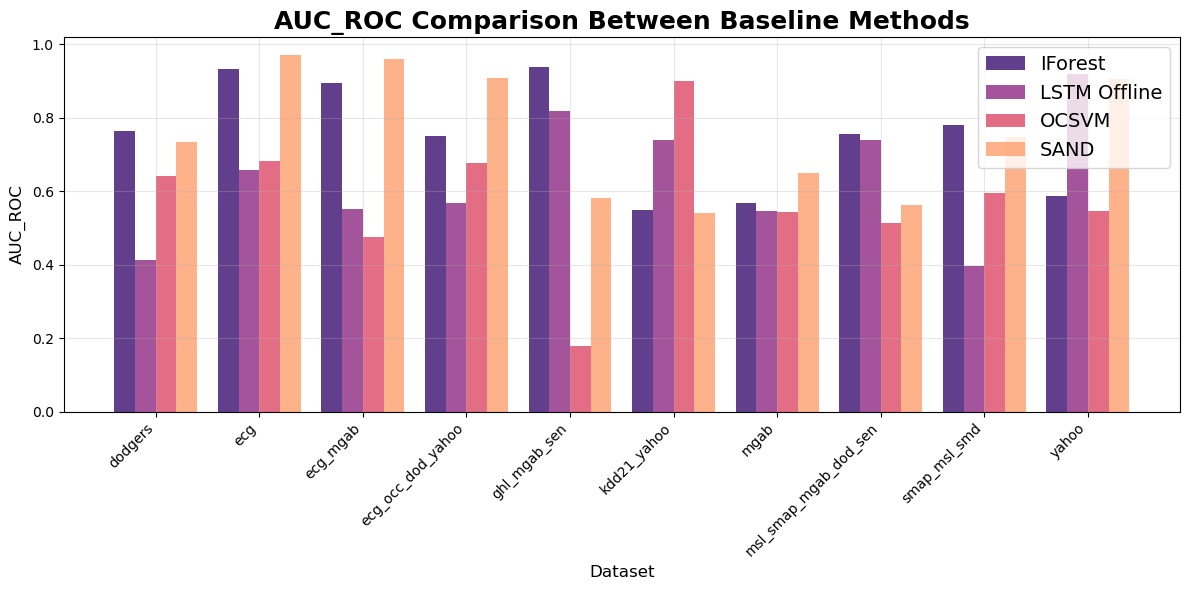

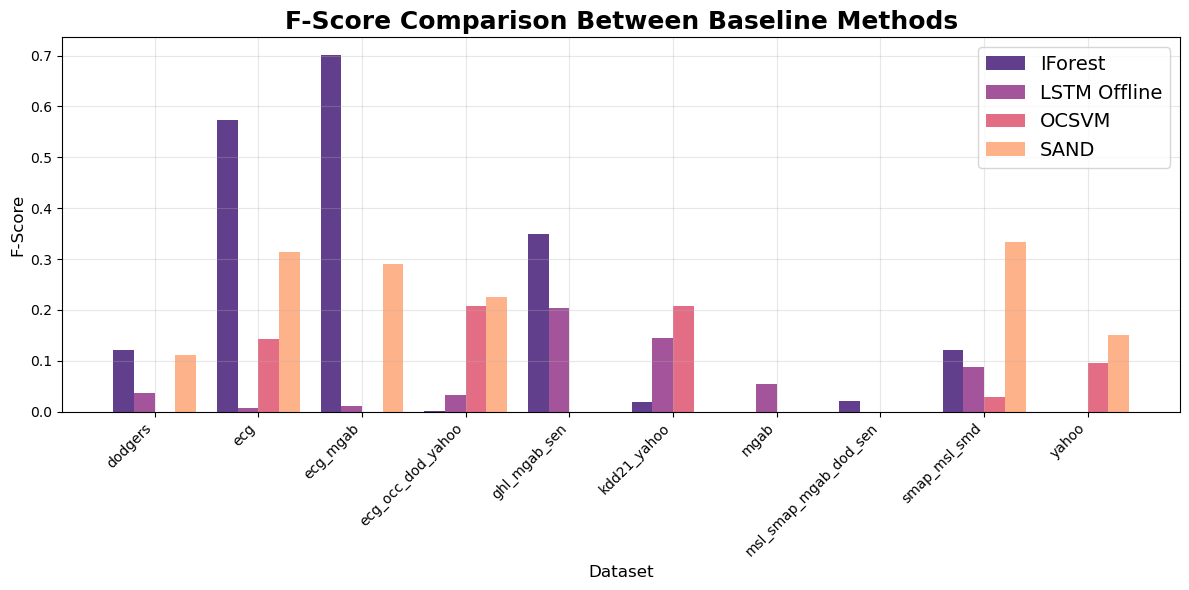

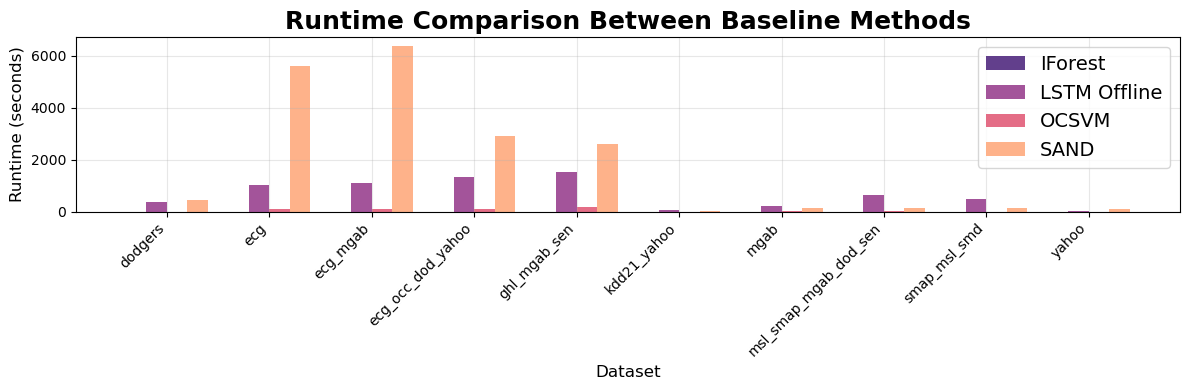

=== PERFORMANCE SUMMARY ===

AUC_ROC Summary:
                  mean       std       min       max
Method                                              
IForest       0.751961  0.145656  0.548954  0.939146
LSTM Offline  0.635515  0.171268  0.396364  0.920448
OCSVM         0.575698  0.183522  0.179842  0.899605
SAND          0.756337  0.169792  0.542088  0.970511

F-Score Summary:
                  mean       std  min       max
Method                                         
IForest       0.190749  0.260085  0.0  0.700785
LSTM Offline  0.057752  0.068784  0.0  0.204545
OCSVM         0.068130  0.088038  0.0  0.208013
SAND          0.142531  0.140164  0.0  0.332986

Runtime Summary:
                     mean          std        min          max
Method                                                        
IForest          2.381004     1.717577   0.268410     4.641472
LSTM Offline   678.686599   540.702216   8.423575  1531.712399
OCSVM           50.083097    60.371780   0.014455   169.5141

In [20]:
sand_metrics_df = pd.read_csv(f'{METRICS_DIR}/sand_metrics.csv')
if_metrics_df = pd.read_csv(f'{METRICS_DIR}/isolation_forest_metrics.csv')
ocsvm_metrics_df = pd.read_csv(f'{METRICS_DIR}/ocsvm_metrics.csv')
lstm_offline_metrics_df = pd.read_csv(f'{METRICS_DIR}/lstm_metrics.csv')

# Add method labels for clarity
sand_metrics_df['Method'] = 'SAND'
if_metrics_df['Method'] = 'IForest'
ocsvm_metrics_df['Method'] = 'OCSVM'
lstm_offline_metrics_df['Method'] = 'LSTM Offline'

# Combine dataframes for comparison
combined_df = pd.concat([
    sand_metrics_df[['dataset', 'AUC_ROC', 'F', 'runtime', 'Method']],
    if_metrics_df[['dataset', 'AUC_ROC', 'F', 'runtime', 'Method']],
    ocsvm_metrics_df[['dataset', 'AUC_ROC', 'F', 'runtime', 'Method']],
    lstm_offline_metrics_df[['dataset', 'AUC_ROC', 'F', 'runtime', 'Method']]
], ignore_index=True)

# Set up the plotting style
plt.style.use('default')
colors = sns.color_palette('magma', n_colors=combined_df['Method'].nunique())

# Create separate figures for each comparison
# Figure 1: AUC_ROC Comparison
fig1, ax1 = plt.subplots(figsize=(12, 6))
pivot_auc = combined_df.pivot(index='dataset', columns='Method', values='AUC_ROC')
x_auc = np.arange(len(pivot_auc.index))
width = 0.8 / len(pivot_auc.columns)

for i, method in enumerate(pivot_auc.columns):
    offset = (i - (len(pivot_auc.columns) - 1) / 2) * width
    ax1.bar(x_auc + offset, pivot_auc[method], width, label=method,
            color=colors[i], alpha=0.8)

ax1.set_xlabel('Dataset', fontsize=12)
ax1.set_ylabel('AUC_ROC', fontsize=12)
ax1.set_title('AUC_ROC Comparison Between Baseline Methods', fontsize=18, fontweight='bold')
os.makedirs(f'{PLOTS_DIR}/', exist_ok=True)
fig1.savefig(f'{PLOTS_DIR}/baseline_auc_roc.png', bbox_inches='tight', dpi=150)
ax1.set_xticks(x_auc)
ax1.set_xticklabels(pivot_auc.index, rotation=45, ha='right')
ax1.legend(fontsize=14)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 2: F-Score Comparison
fig2, ax2 = plt.subplots(figsize=(12, 6))
pivot_f = combined_df.pivot(index='dataset', columns='Method', values='F')
x_f = np.arange(len(pivot_f.index))

for i, method in enumerate(pivot_f.columns):
    offset = (i - (len(pivot_f.columns) - 1) / 2) * width
    ax2.bar(x_f + offset, pivot_f[method], width, label=method,
            color=colors[i], alpha=0.8)

ax2.set_xlabel('Dataset', fontsize=12)
ax2.set_ylabel('F-Score', fontsize=12)
ax2.set_title('F-Score Comparison Between Baseline Methods', fontsize=18, fontweight='bold')
fig2.savefig(f'{PLOTS_DIR}/baseline_fscore.png', bbox_inches='tight', dpi=150)
ax2.set_xticks(x_f)
ax2.set_xticklabels(pivot_f.index, rotation=45, ha='right')
ax2.legend(fontsize=14)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 3: Runtime Comparison
fig3, ax3 = plt.subplots(figsize=(12, 4))
pivot_runtime = combined_df.pivot(index='dataset', columns='Method', values='runtime')
x_runtime = np.arange(len(pivot_runtime.index))

for i, method in enumerate(pivot_runtime.columns):
    offset = (i - (len(pivot_runtime.columns) - 1) / 2) * width
    ax3.bar(x_runtime + offset, pivot_runtime[method], width, label=method,
            color=colors[i], alpha=0.8)

ax3.set_xlabel('Dataset', fontsize=12)
ax3.set_ylabel('Runtime (seconds)', fontsize=12)
ax3.set_title('Runtime Comparison Between Baseline Methods', fontsize=18, fontweight='bold')
fig3.savefig(f'{PLOTS_DIR}/baseline_runtime.png', bbox_inches='tight', dpi=150)
ax3.set_xticks(x_runtime)
ax3.set_xticklabels(pivot_runtime.index, rotation=45, ha='right')
ax3.legend(fontsize=14)
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Summary statistics
print("=== PERFORMANCE SUMMARY ===")
print("\nAUC_ROC Summary:")
auc_summary = combined_df.groupby('Method')['AUC_ROC'].agg(['mean', 'std', 'min', 'max'])
print(auc_summary)

print("\nF-Score Summary:")
f_summary = combined_df.groupby('Method')['F'].agg(['mean', 'std', 'min', 'max'])
print(f_summary)

print("\nRuntime Summary:")
runtime_summary = combined_df.groupby('Method')['runtime'].agg(['mean', 'std', 'min', 'max'])
print(runtime_summary)

print("\n=== DATASET-WISE COMPARISON ===")
comparison_df = combined_df.pivot_table(
    index='dataset',
    columns='Method',
    values=['AUC_ROC', 'F', 'runtime']
)
print(comparison_df)

## **Modified Isolation Forest**

### **Variant 1:** Apply your chosen methods to each batch of the data that arrives. No modification of the method itself. (NaÃ¯ve streaming variant â€“ see NormA-Batch or S2GBatch examples in SAND paper)


### Naive Streaming IForest

In [26]:
_out = f'{METRICS_DIR}/isolation_forest_streaming_metrics_df.csv'
os.makedirs(os.path.dirname(_out), exist_ok=True)
if not os.path.exists(_out):
    # Naive Streaming IForest - Simple batch processing without modifications
    
    def naive_streaming_iforest(data, labels, sliding_window, batch_size=1000):
        """
        Naive streaming version - simply processes data in batches without any optimizations
        """
        all_scores = []
        total_runtime = 0
    
        # Process data in simple batches
        n_batches = math.ceil(len(data) / batch_size)
    
        for batch_idx in range(n_batches):
            start_idx = batch_idx * batch_size
            end_idx = min(start_idx + batch_size, len(data))
    
            batch_data = data[start_idx:end_idx]
    
            if len(batch_data) >= sliding_window:
                # Start timing for this batch
                start_time = time.time()
    
                # Convert batch to features using sliding window
                X_batch = Window(window=sliding_window).convert(batch_data).to_numpy()
    
                # Train IForest on this batch (same as original)
                clf = IForest(n_jobs=1)
                clf.fit(X_batch)
                batch_scores = clf.decision_scores_
    
                # End timing for this batch
                batch_runtime = time.time() - start_time
                total_runtime += batch_runtime
    
                # Normalize scores (same as original)
                batch_scores = MinMaxScaler(feature_range=(0,1)).fit_transform(
                    batch_scores.reshape(-1,1)
                ).ravel()
    
                # Pad scores to match batch length (same as original)
                padded_scores = np.array([
                    batch_scores[0]] * math.ceil((sliding_window-1)/2) +
                    list(batch_scores) +
                    [batch_scores[-1]] * ((sliding_window-1)//2)
                )
    
                # Ensure correct length
                if len(padded_scores) > len(batch_data):
                    padded_scores = padded_scores[:len(batch_data)]
                elif len(padded_scores) < len(batch_data):
                    last_score = padded_scores[-1] if len(padded_scores) > 0 else 0.5
                    padded_scores = np.concatenate([
                        padded_scores,
                        np.full(len(batch_data) - len(padded_scores), last_score)
                    ])
    
                all_scores.extend(padded_scores)
            else:
                # For small batches, assign neutral scores
                neutral_scores = np.full(len(batch_data), 0.5)
                all_scores.extend(neutral_scores)
    
        # Ensure final length matches input data
        if len(all_scores) > len(data):
            all_scores = all_scores[:len(data)]
        elif len(all_scores) < len(data):
            all_scores.extend([all_scores[-1]] * (len(data) - len(all_scores)))
    
        return np.array(all_scores), total_runtime
    
    # Store metrics for each dataset
    naive_streaming_metrics_records = []
    
    # different batch sizes
    batch_sizes = [1500] # we can add more
    
    # Loop over each dataset
    for name, df in datasets:
        data = df.iloc[:, 0].astype(float).to_numpy()
        label = df.iloc[:, 1].astype(int).to_numpy()
    
        slidingWindow = find_length(data)
    
        print(f"\n=== {name} ===")
        print("Estimated Subsequence length: ", slidingWindow)
        print("Time series length: ", len(data))
        print("Number of abnormal points: ", list(label).count(1))
    
        # Test each batch size
        for batch_size in batch_sizes:
            print(f"\nTesting batch size: {batch_size}")
    
            # Apply naive streaming
            scores, runtime = naive_streaming_iforest(data, label, slidingWindow, batch_size)
    
            # Get metrics
            results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
    
            # Add metadata
            results["dataset"] = name
            results["runtime"] = runtime
            results["batch_size"] = batch_size
            results["method"] = "Naive_Streaming_IForest"
    
            naive_streaming_metrics_records.append(results)
    
            print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")
    
    # Create final DataFrame
    naive_streaming_metrics_df = pd.DataFrame(naive_streaming_metrics_records)
    
    # Reorder to have dataset as the first column
    cols = ['dataset'] + [col for col in naive_streaming_metrics_df.columns if col != 'dataset']
    naive_streaming_metrics_df = naive_streaming_metrics_df[cols]
    
    print(f"\nNaive Streaming Results Generated: {len(naive_streaming_metrics_df)} records")
    naive_streaming_metrics_df
    streaming_metrics_df = naive_streaming_metrics_df
    streaming_metrics_df.to_csv(_out, index=False)
    print(f"Saved: {_out}")
else:
    streaming_metrics_df = pd.read_csv(_out)
    print(f"✓ Loaded cached: {_out}")



=== yahoo ===
Estimated Subsequence length:  24
Time series length:  1680
Number of abnormal points:  16

Testing batch size: 1500
  AUC_ROC: 0.5646, Runtime: 0.29s

=== dodgers ===
Estimated Subsequence length:  288
Time series length:  50400
Number of abnormal points:  5612

Testing batch size: 1500
  AUC_ROC: 0.4649, Runtime: 5.95s

=== mgab ===
Estimated Subsequence length:  49
Time series length:  100000
Number of abnormal points:  200

Testing batch size: 1500
  AUC_ROC: 0.5666, Runtime: 9.53s

=== ecg ===
Estimated Subsequence length:  99
Time series length:  230400
Number of abnormal points:  20200

Testing batch size: 1500
  AUC_ROC: 0.8888, Runtime: 21.77s

=== kdd21_yahoo ===
Estimated Subsequence length:  34
Time series length:  31746
Number of abnormal points:  146

Testing batch size: 1500
  AUC_ROC: 0.5216, Runtime: 2.90s

=== ecg_mgab ===
Estimated Subsequence length:  99
Time series length:  330400
Number of abnormal points:  20400

Testing batch size: 1500
  AUC_ROC:

### **Variant 2:** Suggest modifications/adaptations to improve the accuracy (and likely runtime) performance compared to Variant 1. Different modifications per method are also OK.


In [15]:
def drift_aware_streaming_iforest(data, labels, sliding_window, batch_size=2000, drift_threshold=2.0):
    """
    Drift-aware Streaming IForest.

    The model is trained on the first batch.
    For each subsequent batch, the existing model scores the incoming data.
    If the mean anomaly score deviates significantly from the EMA baseline,
    concept drift is assumed and the model is retrained on the current batch.
    Otherwise, the existing model is reused.
    """
    all_scores = []
    total_runtime = 0
    clf = None

    baseline_mean = None
    baseline_std = None

    n_batches = math.ceil(len(data) / batch_size)

    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min(start_idx + batch_size, len(data))
        batch_data = data[start_idx:end_idx]

        if len(batch_data) < sliding_window:
            all_scores.extend([0.5] * len(batch_data))
            continue

        start_time = time.time()

        X_batch = Window(window=sliding_window).convert(batch_data).to_numpy()

        drift_detected = False

        if clf is None:
            clf = IForest(n_jobs=1, n_estimators=100)
            clf.fit(X_batch)
            batch_scores = clf.decision_scores_

        else:
            # Score the new batch using the existing model
            try:
                batch_scores = clf.decision_function(X_batch)
            except Exception:
                clf = IForest(n_jobs=1, n_estimators=100)
                clf.fit(X_batch)
                batch_scores = clf.decision_scores_

            if batch_scores is not None:
                current_mean = np.mean(batch_scores)

                if baseline_std is not None and baseline_std > 0:
                    z_score = abs(current_mean - baseline_mean) / baseline_std
                    drift_detected = z_score > drift_threshold

                if drift_detected:
                    clf = IForest(n_jobs=1, n_estimators=100)
                    clf.fit(X_batch)
                    batch_scores = clf.decision_scores_
                    print(f"  [Batch {batch_idx}] Drift detected - model retrained")

        # Update baseline using EMA
        batch_mean = np.mean(batch_scores)
        batch_std = np.std(batch_scores)

        if baseline_mean is None:
            baseline_mean = batch_mean
            baseline_std = max(batch_std, 1e-6)
        else:
            baseline_mean = 0.9 * baseline_mean + 0.1 * batch_mean
            baseline_std = max(0.9 * baseline_std + 0.1 * batch_std, 1e-6)

        total_runtime += time.time() - start_time

        # Normalize scores
        if np.max(batch_scores) == np.min(batch_scores):
            batch_scores = np.full_like(batch_scores, 0.5)
        else:
            batch_scores = MinMaxScaler(feature_range=(0, 1)).fit_transform(
                batch_scores.reshape(-1, 1)
            ).ravel()

        # Pad scores back to original batch length
        pad = math.ceil((sliding_window - 1) / 2)

        padded = np.array(
            [batch_scores[0]] * pad +
            list(batch_scores) +
            [batch_scores[-1]] * pad
        )

        padded = padded[:len(batch_data)]

        if len(padded) < len(batch_data):
            padded = np.concatenate([
                padded,
                [padded[-1]] * (len(batch_data) - len(padded))
            ])

        all_scores.extend(padded)

    if len(all_scores) > len(data):
        all_scores = all_scores[:len(data)]
    elif len(all_scores) < len(data):
        fill_value = all_scores[-1] if len(all_scores) > 0 else 0.5
        all_scores.extend([fill_value] * (len(data) - len(all_scores)))

    return np.array(all_scores), total_runtime

In [ ]:
# Run Drift-Aware Streaming IForest on all datasets
simple_improved_records = []

for name, _, df in datasets:
    data = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()

    slidingWindow = find_length(data)

    print(f"=== {name} ===")
    print("Estimated Subsequence length: ", slidingWindow)
    print("Time series length: ", len(data))
    print("Number of abnormal points: ", list(label).count(1))

    scores, runtime = drift_aware_streaming_iforest(data, label, slidingWindow)

    results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
    results["dataset"] = name
    results["runtime"] = runtime
    results["method"]  = "Drift_Aware_Streaming_IForest"

    simple_improved_records.append(results)
    print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")

simple_improved_metrics_df = pd.DataFrame(simple_improved_records)
cols = ['dataset'] + [col for col in simple_improved_metrics_df.columns if col != 'dataset']
simple_improved_metrics_df = simple_improved_metrics_df[cols]
simple_improved_metrics_df

In [17]:
# Save Metrics
output_path = f'{METRICS_DIR}/isolation_forest_simple_improved_streaming_metrics_df.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
simple_improved_metrics_df.to_csv(output_path, index=False)

## **Modified OCSVM**

### **Variant 1:** Apply your chosen methods to each batch of the data that arrives. No modification of the method itself. (NaÃ¯ve streaming variant â€“ see NormA-Batch or S2GBatch examples in SAND paper)


In [22]:
def online_ocsvm_tsb(data, label, batch_size, overlap, nu=0.05):

    step = batch_size - overlap
    n_batches = (len(data) - batch_size) // step + 1

    all_scores = np.zeros(len(data))

    sliding_window = find_length(data)

    if len(data) < batch_size:
        batch_size = max(sliding_window, len(data) // 5)
        overlap = min(overlap, batch_size - 1)

    step = max(1, batch_size - overlap)
    n_batches = (len(data) - batch_size) // step + 1

    # Start timing
    start_time = time.time()

    for i in tqdm(range(n_batches), desc="Processing batches"):
        start = i * step
        end = start + batch_size
        if end > len(data):
            end = len(data)

        batch = data[start:end]
        X_batch = Window(window=sliding_window).convert(batch).to_numpy()
        X_batch = MinMaxScaler().fit_transform(X_batch.T).T

        # Fix: Provide both X_train and X_test to fit()
        clf = OCSVM(nu=nu)
        clf.fit(X_batch, X_batch)
        batch_scores = clf.decision_scores_

        # Pad scores to match time series indices
        pad = (sliding_window - 1) // 2
        padded_scores = np.array(
            [batch_scores[0]] * pad + list(batch_scores) + [batch_scores[-1]] * pad
        )
        batch_len = len(batch)
        padded_scores = padded_scores[:batch_len]

        if len(padded_scores) < batch_len:
            pad_len = batch_len - len(padded_scores)
            padded_scores = np.concatenate([padded_scores, [padded_scores[-1]] * pad_len])
        elif len(padded_scores) > batch_len:
            padded_scores = padded_scores[:batch_len]

        all_scores[start:end] = np.maximum(all_scores[start:end], padded_scores)

    # End timing
    end_time = time.time()
    runtime = end_time - start_time

    # Final score normalization
    all_scores = MinMaxScaler().fit_transform(all_scores.reshape(-1, 1)).ravel()

    results = get_metrics(all_scores, label, metric="all", slidingWindow=sliding_window)
    results["runtime"] = runtime

    return results, all_scores

In [23]:
# Tune these
batch_size = 3000
overlap = 0

metrics_records = []

for name, _, df in datasets:
    data = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()

    print(f"\n=== {name} ===")
    print("Time series length:", len(data))
    print("Abnormal points:", list(label).count(1))
    results, scores = online_ocsvm_tsb(data, label, batch_size, overlap)

    results["dataset"] = name
    metrics_records.append(results)

# Final DataFrame
OCSVM_online_df = pd.DataFrame(metrics_records)
OCSVM_online_df = OCSVM_online_df[['dataset'] + [c for c in OCSVM_online_df.columns if c != 'dataset']]
display(OCSVM_online_df)


=== yahoo ===
Time series length: 1680
Abnormal points: 16


Processing batches: 100%|██████████| 5/5 [00:00<00:00, 235.99it/s]



=== dodgers ===
Time series length: 50400
Abnormal points: 5612


Processing batches: 100%|██████████| 16/16 [00:02<00:00,  6.87it/s]



=== mgab ===
Time series length: 100000
Abnormal points: 200


Processing batches: 100%|██████████| 33/33 [00:02<00:00, 13.90it/s]


... (11 outputs left out)

Processing batches: 100%|██████████| 96/96 [00:07<00:00, 12.24it/s]



=== msl_smap_mgab_dod_sen ===
Time series length: 190962
Abnormal points: 10025


Processing batches: 100%|██████████| 63/63 [00:03<00:00, 15.89it/s]


,dataset,AUC_ROC,AUC_PR,Precision,Recall,F,Precision_at_k,Rprecision,Rrecall,RF,R_AUC_ROC,R_AUC_PR,VUS_ROC,VUS_PR,Affiliation_Precision,Affiliation_Recall,runtime
0,yahoo,0.566068,0.018773,0.047619,0.062500,0.054054,0.062500,0.058824,0.062500,0.060606,0.547556,0.185862,0.584792,0.094179,0.303446,0.116735,0.029265
1,dodgers,0.549969,0.142716,0.327824,0.042409,0.075103,0.042409,0.411565,0.033999,0.062810,0.663513,0.571646,0.594421,0.350858,0.832927,0.039235,2.332181
2,mgab,0.540301,0.002523,0.005960,0.045000,0.010526,0.045000,0.003484,0.076000,0.006663,0.509319,0.008779,0.528944,0.004732,0.517911,0.909467,2.376692
3,ecg,0.662569,0.303589,0.738893,0.093861,0.166564,0.093861,0.429086,0.189163,0.262572,0.649644,0.554062,0.686668,0.364679,0.920927,0.043408,6.915346
4,kdd21_yahoo,0.670943,0.023320,0.046914,0.130137,0.068966,0.130137,0.031579,0.014057,0.019454,0.488944,0.030443,0.494717,0.012418,0.534998,0.095678,0.589986
5,ecg_mgab,0.658462,0.252459,0.703632,0.106373,0.184807,0.106373,0.409407,0.206540,0.274565,0.634118,0.417107,0.674070,0.286310,0.920927,0.041416,8.767125
6,ghl_mgab_sen,0.467062,0.026874,0.113382,0.041737,0.061015,0.041737,0.038181,0.079902,0.051671,0.446562,0.019705,0.447308,0.017033,0.798104,0.054631,9.019810
7,smap_msl_smd,0.597957,0.036530,0.092676,0.097792,0.095165,0.097792,0.060179,0.072707,0.065852,0.573713,0.108678,0.589595,0.053105,0.660277,0.540529,1.172973
8,ecg_occ_dod_yahoo,0.626632,0.237060,0.646184,0.070980,0.127910,0.070980,0.420514,0.110103,0.174514,0.609132,0.498247,0.620089,0.269869,0.880525,0.007891,7.843664
9,msl_smap_mgab_dod_sen,0.542680,0.066961,0.232061,0.030324,0.053639,0.030324,0.157247,0.049480,0.075274,0.525708,0.149376,0.510325,0.075570,0.223558,0.001896,3.965458


In [24]:
OCSVM_online_df

,dataset,AUC_ROC,AUC_PR,Precision,Recall,F,Precision_at_k,Rprecision,Rrecall,RF,R_AUC_ROC,R_AUC_PR,VUS_ROC,VUS_PR,Affiliation_Precision,Affiliation_Recall,runtime
0,yahoo,0.566068,0.018773,0.047619,0.062500,0.054054,0.062500,0.058824,0.062500,0.060606,0.547556,0.185862,0.584792,0.094179,0.303446,0.116735,0.029265
1,dodgers,0.549969,0.142716,0.327824,0.042409,0.075103,0.042409,0.411565,0.033999,0.062810,0.663513,0.571646,0.594421,0.350858,0.832927,0.039235,2.332181
2,mgab,0.540301,0.002523,0.005960,0.045000,0.010526,0.045000,0.003484,0.076000,0.006663,0.509319,0.008779,0.528944,0.004732,0.517911,0.909467,2.376692
3,ecg,0.662569,0.303589,0.738893,0.093861,0.166564,0.093861,0.429086,0.189163,0.262572,0.649644,0.554062,0.686668,0.364679,0.920927,0.043408,6.915346
4,kdd21_yahoo,0.670943,0.023320,0.046914,0.130137,0.068966,0.130137,0.031579,0.014057,0.019454,0.488944,0.030443,0.494717,0.012418,0.534998,0.095678,0.589986
5,ecg_mgab,0.658462,0.252459,0.703632,0.106373,0.184807,0.106373,0.409407,0.206540,0.274565,0.634118,0.417107,0.674070,0.286310,0.920927,0.041416,8.767125
6,ghl_mgab_sen,0.467062,0.026874,0.113382,0.041737,0.061015,0.041737,0.038181,0.079902,0.051671,0.446562,0.019705,0.447308,0.017033,0.798104,0.054631,9.019810
7,smap_msl_smd,0.597957,0.036530,0.092676,0.097792,0.095165,0.097792,0.060179,0.072707,0.065852,0.573713,0.108678,0.589595,0.053105,0.660277,0.540529,1.172973
8,ecg_occ_dod_yahoo,0.626632,0.237060,0.646184,0.070980,0.127910,0.070980,0.420514,0.110103,0.174514,0.609132,0.498247,0.620089,0.269869,0.880525,0.007891,7.843664
9,msl_smap_mgab_dod_sen,0.542680,0.066961,0.232061,0.030324,0.053639,0.030324,0.157247,0.049480,0.075274,0.525708,0.149376,0.510325,0.075570,0.223558,0.001896,3.965458


In [25]:
# Save Metrics
output_path = f'{METRICS_DIR}/ocsvm_metrics_batch_3000_2.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
OCSVM_online_df.to_csv(output_path, index=False)

### **Variant 2:** Suggest modifications/adaptations to improve the accuracy (and likely runtime) performance compared to Variant 1. Different modifications per method are also OK.


In [26]:
def online_ocsvm_tsb_v2(data, label, batch_size, overlap, nu=0.05):

    sliding_window = min(find_length(data), len(data))

    if len(data) < batch_size:
        batch_size = max(sliding_window, len(data) // 5)
        overlap = min(overlap, batch_size - 1)

    step = max(1, batch_size - overlap)
    n_batches = (len(data) - batch_size) // step + 1
    all_scores = np.zeros(len(data))

    # === Initial Training on first batch ===
    initial_batch = data[:batch_size]
    train_size = max(int(0.1 * batch_size), sliding_window)
    train_data = initial_batch[:train_size]

    X_train = Window(window=sliding_window).convert(train_data).to_numpy()
    X_train = MinMaxScaler().fit_transform(X_train.T).T

    # Start timing
    start_time = time.time()

    for i in tqdm(range(n_batches), desc="Processing batches"):
        start = i * step
        end = start + batch_size
        if end > len(data):
            end = len(data)

        batch = data[start:end]

        if len(batch) < sliding_window:
            all_scores[start:end] = 0.5
            continue

        X_batch = Window(window=sliding_window).convert(batch).to_numpy()
        X_batch = MinMaxScaler().fit_transform(X_batch.T).T

        # Fix: In TSB-UAD, the wrapper requires fit(train, test) to populate decision_scores_
        clf = OCSVM(nu=nu)
        clf.fit(X_train, X_batch)
        batch_scores = clf.decision_scores_

        # Pad scores to match time series indices
        batch_len = len(batch)
        pad = (sliding_window - 1) // 2
        padded_scores = np.array(
            [batch_scores[0]] * pad + list(batch_scores) + [batch_scores[-1]] * pad
        )
        padded_scores = padded_scores[:batch_len]

        if len(padded_scores) < batch_len:
            pad_len = batch_len - len(padded_scores)
            padded_scores = np.concatenate([padded_scores, [padded_scores[-1]] * pad_len])
        elif len(padded_scores) > batch_len:
            padded_scores = padded_scores[:batch_len]

        all_scores[start:end] = np.maximum(all_scores[start:end], padded_scores)

        # KMeans prototype selection: one representative per cluster
        k = max(1, int(0.01 * len(X_batch)))
        kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto").fit(X_batch)
        centroids = kmeans.cluster_centers_

        distances = pairwise_distances(centroids, X_batch)
        selected_indices = [np.argmin(distances[j]) for j in range(k)]
        selected_indices = list(dict.fromkeys(selected_indices))

        # Update training set: drop oldest 30%, append new prototypes
        medoids = X_batch[selected_indices]
        X_train = np.concatenate([X_train[int(0.3*len(X_train)):], medoids], axis=0)

    # End timing
    end_time = time.time()
    runtime = end_time - start_time

    all_scores = MinMaxScaler().fit_transform(all_scores.reshape(-1, 1)).ravel()

    results = get_metrics(all_scores, label, metric="all", slidingWindow=sliding_window)
    results["runtime"] = runtime

    return results, all_scores

In [27]:
# Tune these
batch_size = 3000
overlap = 0

metrics_records = []

for name, _, df in datasets:
    data = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()

    print(f"\n=== {name} ===")
    print("Time series length:", len(data))
    print("Abnormal points:", list(label).count(1))
    results, scores = online_ocsvm_tsb_v2(data, label, batch_size, overlap)
    results["dataset"] = name
    metrics_records.append(results)

# Final DataFrame
OCSVM_online_df = pd.DataFrame(metrics_records)
OCSVM_online_df = OCSVM_online_df[['dataset'] + [c for c in OCSVM_online_df.columns if c != 'dataset']]
display(OCSVM_online_df)


=== yahoo ===
Time series length: 1680
Abnormal points: 16


Processing batches:   0%|          | 0/5 [00:00<?, ?it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
Processing batches:  20%|██        | 1/5 [00:00<00:00,  7.06it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\vaspn


=== dodgers ===
Time series length: 50400
Abnormal points: 5612


Processing batches:   0%|          | 0/16 [00:00<?, ?it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
Processing batches:  12%|█▎        | 2/16 [00:00<00:01, 11.00it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\


=== mgab ===
Time series length: 100000
Abnormal points: 200


Processing batches:   0%|          | 0/33 [00:00<?, ?it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
Processing batches:   6%|▌         | 2/33 [00:00<00:01, 16.84it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\

... (11 outputs left out)

Processing batches:   0%|          | 0/96 [00:00<?, ?it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
Processing batches:   1%|          | 1/96 [00:00<00:12,  7.57it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
Processin


=== msl_smap_mgab_dod_sen ===
Time series length: 190962
Abnormal points: 10025


Processing batches:   0%|          | 0/63 [00:00<?, ?it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
Processing batches:   3%|▎         | 2/63 [00:00<00:03, 15.83it/s]c:\Users\vaspn\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
c:\Users\

,dataset,AUC_ROC,AUC_PR,Precision,Recall,F,Precision_at_k,Rprecision,Rrecall,RF,R_AUC_ROC,R_AUC_PR,VUS_ROC,VUS_PR,Affiliation_Precision,Affiliation_Recall,runtime
0,yahoo,0.676720,0.017906,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.784360,0.244940,0.800352,0.144787,0.533895,0.568597,0.184718
1,dodgers,0.551735,0.198815,0.355966,0.096222,0.151494,0.096222,0.177728,0.033360,0.056175,0.699407,0.614145,0.623334,0.395350,0.631719,0.036605,1.803796
2,mgab,0.591942,0.003303,0.004618,0.055000,0.008521,0.055000,0.004357,0.104000,0.008364,0.582783,0.008327,0.640313,0.006314,0.391301,0.556118,1.997491
3,ecg,0.683833,0.236976,0.651660,0.057327,0.105383,0.057327,0.377182,0.102417,0.161092,0.687522,0.372469,0.727756,0.301627,0.973962,0.009575,4.769946
4,kdd21_yahoo,0.843497,0.156309,0.110193,0.547945,0.183486,0.547945,0.035971,0.017557,0.023596,0.366076,0.020881,0.382534,0.022617,0.769729,0.058772,0.916524
5,ecg_mgab,0.687717,0.175926,0.415762,0.058186,0.102086,0.058186,0.311663,0.098293,0.149452,0.680115,0.286652,0.722976,0.230274,0.973962,0.009136,8.317241
6,ghl_mgab_sen,0.544112,0.027420,0.030440,0.017957,0.022589,0.017957,0.084746,0.037239,0.051742,0.489781,0.028374,0.487391,0.024299,0.345740,0.019699,7.503842
7,smap_msl_smd,0.749521,0.202500,0.511834,0.272871,0.355967,0.272871,0.576667,0.271059,0.368776,0.735282,0.273061,0.757344,0.259378,0.746587,0.216311,1.064288
8,ecg_occ_dod_yahoo,0.692827,0.294560,0.717113,0.115724,0.199288,0.115724,0.359236,0.073175,0.121583,0.647951,0.402914,0.672265,0.307334,0.940719,0.008562,6.669755
9,msl_smap_mgab_dod_sen,0.604617,0.159364,0.442491,0.120499,0.189416,0.120499,0.218820,0.068380,0.104199,0.552553,0.157502,0.528841,0.117079,0.333880,0.003524,4.004425


In [28]:
OCSVM_online_df

,dataset,AUC_ROC,AUC_PR,Precision,Recall,F,Precision_at_k,Rprecision,Rrecall,RF,R_AUC_ROC,R_AUC_PR,VUS_ROC,VUS_PR,Affiliation_Precision,Affiliation_Recall,runtime
0,yahoo,0.676720,0.017906,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.784360,0.244940,0.800352,0.144787,0.533895,0.568597,0.184718
1,dodgers,0.551735,0.198815,0.355966,0.096222,0.151494,0.096222,0.177728,0.033360,0.056175,0.699407,0.614145,0.623334,0.395350,0.631719,0.036605,1.803796
2,mgab,0.591942,0.003303,0.004618,0.055000,0.008521,0.055000,0.004357,0.104000,0.008364,0.582783,0.008327,0.640313,0.006314,0.391301,0.556118,1.997491
3,ecg,0.683833,0.236976,0.651660,0.057327,0.105383,0.057327,0.377182,0.102417,0.161092,0.687522,0.372469,0.727756,0.301627,0.973962,0.009575,4.769946
4,kdd21_yahoo,0.843497,0.156309,0.110193,0.547945,0.183486,0.547945,0.035971,0.017557,0.023596,0.366076,0.020881,0.382534,0.022617,0.769729,0.058772,0.916524
5,ecg_mgab,0.687717,0.175926,0.415762,0.058186,0.102086,0.058186,0.311663,0.098293,0.149452,0.680115,0.286652,0.722976,0.230274,0.973962,0.009136,8.317241
6,ghl_mgab_sen,0.544112,0.027420,0.030440,0.017957,0.022589,0.017957,0.084746,0.037239,0.051742,0.489781,0.028374,0.487391,0.024299,0.345740,0.019699,7.503842
7,smap_msl_smd,0.749521,0.202500,0.511834,0.272871,0.355967,0.272871,0.576667,0.271059,0.368776,0.735282,0.273061,0.757344,0.259378,0.746587,0.216311,1.064288
8,ecg_occ_dod_yahoo,0.692827,0.294560,0.717113,0.115724,0.199288,0.115724,0.359236,0.073175,0.121583,0.647951,0.402914,0.672265,0.307334,0.940719,0.008562,6.669755
9,msl_smap_mgab_dod_sen,0.604617,0.159364,0.442491,0.120499,0.189416,0.120499,0.218820,0.068380,0.104199,0.552553,0.157502,0.528841,0.117079,0.333880,0.003524,4.004425


In [29]:
# Save Metrics
output_path = f'{METRICS_DIR}/ocsvm_metrics_batch_3000_v2_2.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
OCSVM_online_df.to_csv(output_path, index=False)

## **Modified LSTM**

### **Variant 1:** Naive Streaming LSTM
Apply LSTM to each batch independently, retrain from scratch with no memory across batches.

In [ ]:
def naive_streaming_lstm(data, labels, sliding_window, batch_size=3000):
    all_scores = []
    total_runtime = 0
    n_batches = math.ceil(len(data) / batch_size)

    for batch_idx in range(n_batches):
        start_idx  = batch_idx * batch_size
        end_idx    = min(start_idx + batch_size, len(data))
        batch_data = data[start_idx:end_idx]

        if len(batch_data) >= sliding_window * 2:
            start_time = time.time()
            train_size = max(int(0.1 * len(batch_data)), sliding_window * 2)
            data_train = batch_data[:train_size]
            data_test  = batch_data

            # Fresh model from scratch â€” no memory from previous batches
            tf.keras.backend.clear_session()
            gc.collect()
            clf = lstm(slidingwindow=sliding_window, predict_time_steps=1,
                       epochs=5, patience=3, verbose=0)
            clf.fit(data_train, data_test)
            measure = Fourier()
            measure.detector = clf
            measure.set_param()
            clf.decision_function(measure=measure)
            batch_scores = clf.decision_scores_
            batch_scores = MinMaxScaler(feature_range=(0,1)).fit_transform(
                batch_scores.reshape(-1,1)).ravel()
            total_runtime += time.time() - start_time
            all_scores.extend(batch_scores[:len(batch_data)])
        else:
            all_scores.extend([0.5] * len(batch_data))

    if len(all_scores) > len(data):
        all_scores = all_scores[:len(data)]
    elif len(all_scores) < len(data):
        all_scores.extend([all_scores[-1] if all_scores else 0.5] * (len(data) - len(all_scores)))
    return np.array(all_scores), total_runtime

# Part 1: run on all datasets except the last (msl_smap_mgab_dod_sen)
lstm_naive_records = []
for name, _, df in datasets[:-1]:
    data  = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()
    slidingWindow = find_length(data)
    print(f"=== {name} ===")
    scores, runtime = naive_streaming_lstm(data, label, slidingWindow)
    results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
    results["dataset"] = name
    results["runtime"] = runtime
    results["method"]  = "Naive_Streaming_LSTM"
    lstm_naive_records.append(results)
    print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")

lstm_naive_df = pd.DataFrame(lstm_naive_records)
lstm_naive_df = lstm_naive_df[['dataset'] + [c for c in lstm_naive_df.columns if c != 'dataset']]
lstm_naive_df

In [ ]:
output_path = f'{METRICS_DIR}/lstm_naive_metrics.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
lstm_naive_df.to_csv(output_path, index=False)

In [ ]:
# Part 2: run on the last dataset (msl_smap_mgab_dod_sen) and append to CSV
output_path = f'{METRICS_DIR}/lstm_naive_metrics.csv'

name, _, df = datasets[-1]
data  = df.iloc[:, 0].astype(float).to_numpy()
label = df.iloc[:, 1].astype(int).to_numpy()
slidingWindow = find_length(data)

print(f"=== {name} ===")
print("Time series length:", len(data))

scores, runtime = naive_streaming_lstm(data, label, slidingWindow)
results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
results["dataset"] = name
results["runtime"] = runtime
results["method"]  = "Naive_Streaming_LSTM"

print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")

# Append to existing CSV
last_df = pd.DataFrame([results])
last_df = last_df[['dataset'] + [c for c in last_df.columns if c != 'dataset']]
last_df.to_csv(output_path, mode='a', header=False, index=False)

# Reload full DataFrame
lstm_naive_df = pd.read_csv(output_path)
lstm_naive_df

### **Variant 2:** Improved Streaming LSTM (Incremental Fine-tuning)
Instead of retraining from scratch, the model is fine-tuned on each new batch (incremental learning). This preserves knowledge from previous batches and adapts to distribution shifts.

In [ ]:
def experience_replay_lstm(data, labels, sliding_window, batch_size=3000, buffer_size=500):
    """
    Variant 2: Experience Replay LSTM.
    Maintains a replay buffer of past 'normal' samples.
    Each new batch is trained on: current batch + samples from the buffer.
    This prevents catastrophic forgetting while adapting to new patterns.
    """
    all_scores = []
    total_runtime = 0
    clf = None
    replay_buffer = np.empty((0,), dtype=float)

    n_batches = math.ceil(len(data) / batch_size)

    for batch_idx in range(n_batches):
        start_idx  = batch_idx * batch_size
        end_idx    = min(start_idx + batch_size, len(data))
        batch_data = data[start_idx:end_idx]

        if len(batch_data) < sliding_window * 2:
            all_scores.extend([0.5] * len(batch_data))
            continue

        start_time = time.time()

        # Training data = first 10% of batch + replay buffer
        train_size  = max(int(0.1 * len(batch_data)), sliding_window * 2)
        batch_train = batch_data[:train_size]

        if len(replay_buffer) > 0:
            data_train = np.concatenate([replay_buffer, batch_train])
        else:
            data_train = batch_train

        data_test = batch_data

        if clf is None:
            clf = lstm(slidingwindow=sliding_window, predict_time_steps=1,
                       epochs=10, patience=5, verbose=0)
        else:
            clf.epochs   = 3
            clf.patience = 2

        clf.fit(data_train, data_test)
        measure = Fourier()
        measure.detector = clf
        measure.set_param()
        clf.decision_function(measure=measure)

        batch_scores = clf.decision_scores_
        batch_scores = MinMaxScaler(feature_range=(0,1)).fit_transform(
            batch_scores.reshape(-1,1)).ravel()

        total_runtime += time.time() - start_time
        all_scores.extend(batch_scores[:len(batch_data)])

        # Update replay buffer: keep low-anomaly-score (normal) samples from this batch
        if len(batch_scores) == len(batch_data):
            threshold = np.percentile(batch_scores, 30)
            normal_samples = batch_data[batch_scores <= threshold]
        else:
            min_len = min(len(batch_scores), len(batch_data))
            threshold = np.percentile(batch_scores[:min_len], 30)
            normal_samples = batch_data[:min_len][batch_scores[:min_len] <= threshold]
        replay_buffer = np.concatenate([replay_buffer, normal_samples])
        if len(replay_buffer) > buffer_size:
            recent_size = int(0.7 * buffer_size)
            old_size    = buffer_size - recent_size
            old_part    = replay_buffer[:len(replay_buffer) // 2]
            recent_part = replay_buffer[len(replay_buffer) // 2:]
            if len(old_part) > old_size:
                idx      = np.random.choice(len(old_part), size=old_size, replace=False)
                old_part = old_part[np.sort(idx)]
            recent_part   = recent_part[-recent_size:]
            replay_buffer = np.concatenate([old_part, recent_part])

    if len(all_scores) > len(data):
        all_scores = all_scores[:len(data)]
    elif len(all_scores) < len(data):
        all_scores.extend([all_scores[-1] if all_scores else 0.5] * (len(data) - len(all_scores)))

    return np.array(all_scores), total_runtime

# Part 1: run on all datasets except the last (msl_smap_mgab_dod_sen)
lstm_incremental_records = []

for name, _, df in datasets[:-1]:
    data  = df.iloc[:, 0].astype(float).to_numpy()
    label = df.iloc[:, 1].astype(int).to_numpy()
    slidingWindow = find_length(data)

    print(f"=== {name} ===")
    print("Time series length:", len(data))
    print("Abnormal points:",    list(label).count(1))

    scores, runtime = experience_replay_lstm(data, label, slidingWindow)
    results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
    results["dataset"] = name
    results["runtime"] = runtime
    results["method"]  = "Experience_Replay_LSTM"
    lstm_incremental_records.append(results)
    print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")

lstm_incremental_df = pd.DataFrame(lstm_incremental_records)
lstm_incremental_df = lstm_incremental_df[
    ['dataset'] + [c for c in lstm_incremental_df.columns if c != 'dataset']]
lstm_incremental_df

In [ ]:
output_path = f'{METRICS_DIR}/lstm_incremental_metrics.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
lstm_incremental_df.to_csv(output_path, index=False)

In [ ]:
# Part 2: run on the last dataset (msl_smap_mgab_dod_sen) and append to CSV
output_path = f'{METRICS_DIR}/lstm_incremental_metrics.csv'

name, _, df = datasets[-1]
data  = df.iloc[:, 0].astype(float).to_numpy()
label = df.iloc[:, 1].astype(int).to_numpy()
slidingWindow = find_length(data)

print(f"=== {name} ===")
print("Time series length:", len(data))
print("Abnormal points:",    list(label).count(1))

scores, runtime = experience_replay_lstm(data, label, slidingWindow)
results = get_metrics(scores, label, metric="all", slidingWindow=slidingWindow)
results["dataset"] = name
results["runtime"] = runtime
results["method"]  = "Experience_Replay_LSTM"

print(f"  AUC_ROC: {results.get('AUC_ROC', 0):.4f}, Runtime: {runtime:.2f}s")

# Append to existing CSV
last_df = pd.DataFrame([results])
last_df = last_df[['dataset'] + [c for c in last_df.columns if c != 'dataset']]
last_df.to_csv(output_path, mode='a', header=False, index=False)

# Reload full DataFrame
lstm_incremental_df = pd.read_csv(output_path)
lstm_incremental_df

PLots

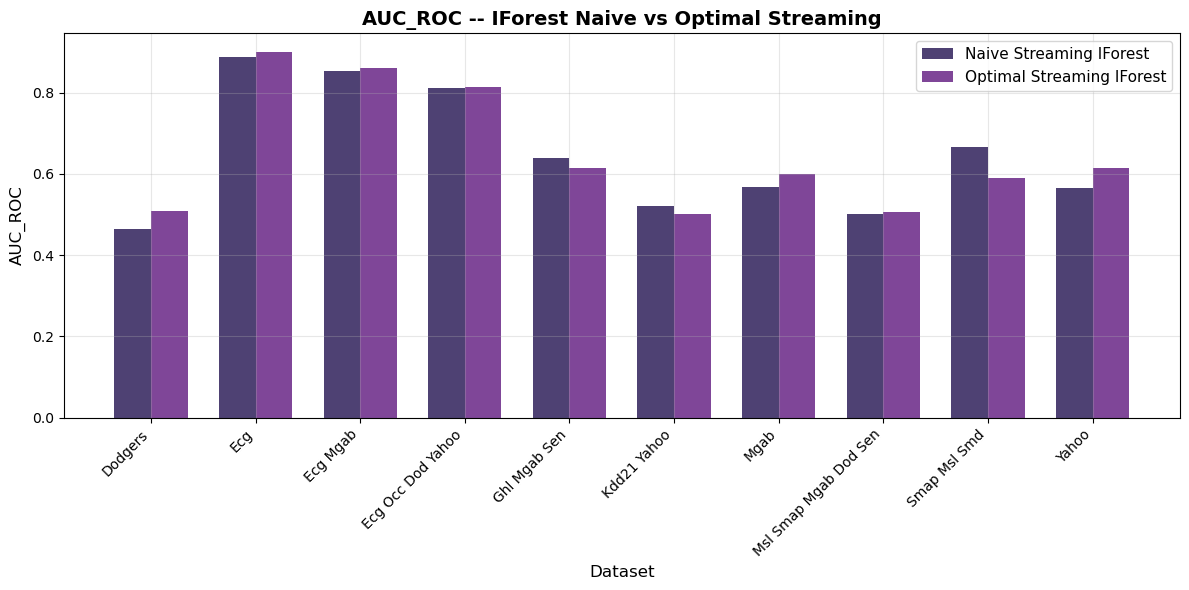

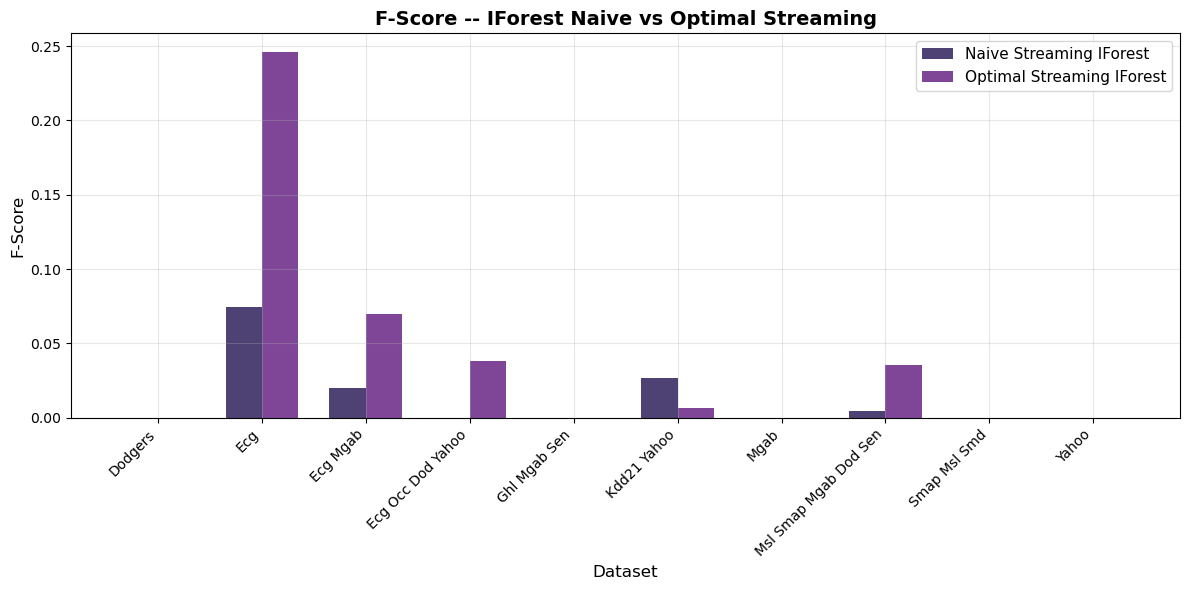

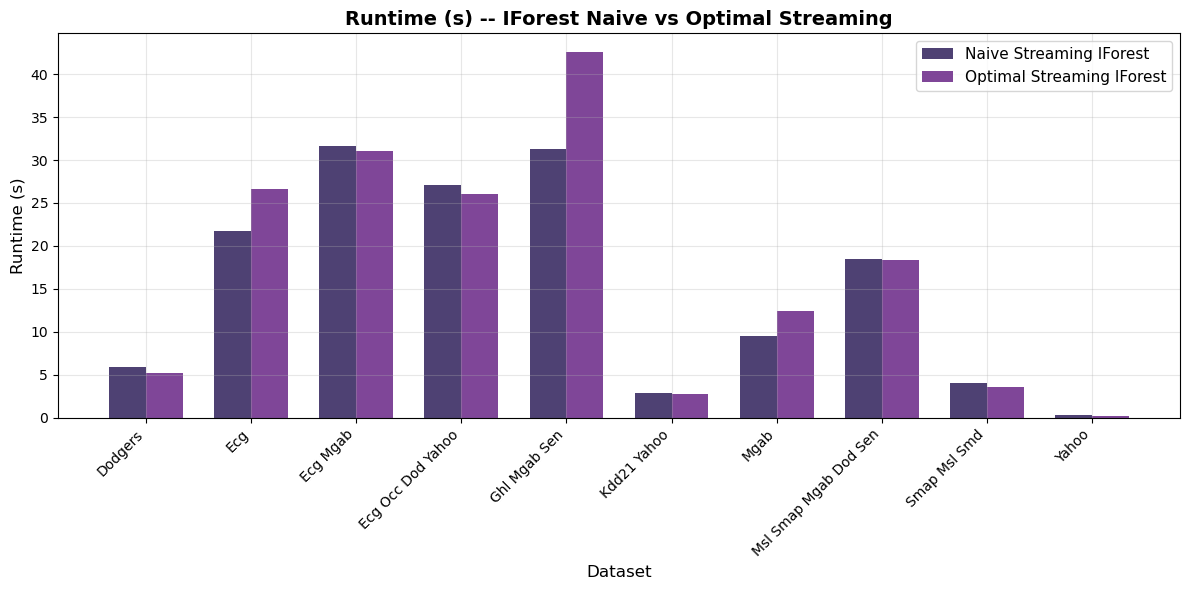

=== IFOREST V1 vs V2 SUMMARY ===
                            AUC_ROC                   F             runtime  \
                               mean       std      mean      std       mean   
Method                                                                        
Naive Streaming IForest    0.647673  0.153264  0.012582  0.02378  15.295362   
Optimal Streaming IForest  0.651296  0.150855  0.039623  0.07644  16.880798   

                                      
                                 std  
Method                                
Naive Streaming IForest    12.208285  
Optimal Streaming IForest  14.367425  


In [20]:
iforest_v1_df = pd.read_csv(f'{METRICS_DIR}/isolation_forest_streaming_metrics_df.csv')
iforest_v2_df = pd.read_csv(f'{METRICS_DIR}/isolation_forest_simple_improved_streaming_metrics_df.csv')

def clean_dataset_name(name):
    return name.replace('_', ' ').title()

iforest_v1_df['dataset_clean'] = iforest_v1_df['dataset'].apply(clean_dataset_name)
iforest_v2_df['dataset_clean'] = iforest_v2_df['dataset'].apply(clean_dataset_name)
iforest_v1_df['Method'] = 'Naive Streaming IForest'
iforest_v2_df['Method'] = 'Optimal Streaming IForest'

combined_df = pd.concat([
    iforest_v1_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    iforest_v2_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']]
], ignore_index=True)

plt.style.use('default')
colors = sns.color_palette('magma')

for metric, title in [('AUC_ROC', 'AUC_ROC'), ('F', 'F-Score'), ('runtime', 'Runtime (s)')]:
    fig, ax = plt.subplots(figsize=(12, 6))
    pivot = combined_df.pivot(index='dataset_clean', columns='Method', values=metric)
    x = np.arange(len(pivot.index)); width = 0.35
    ax.bar(x - width/2, pivot.iloc[:, 0], width, label=pivot.columns[0], color=colors[0], alpha=0.8)
    ax.bar(x + width/2, pivot.iloc[:, 1], width, label=pivot.columns[1], color=colors[1], alpha=0.8)
    ax.set_xlabel('Dataset', fontsize=12); ax.set_ylabel(title, fontsize=12)
    ax.set_title(f'{title} -- IForest Naive vs Optimal Streaming', fontsize=14, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(pivot.index, rotation=45, ha='right')
    ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
    os.makedirs(f'{PLOTS_DIR}/', exist_ok=True)
    fig.savefig(f'{PLOTS_DIR}/iforest_v1_v2_{metric}.png', bbox_inches='tight', dpi=150)
    plt.tight_layout(); plt.show()

print('=== IFOREST V1 vs V2 SUMMARY ===')
print(combined_df.groupby('Method')[['AUC_ROC', 'F', 'runtime']].agg(['mean', 'std']))

In [21]:
offline_metrics_df = pd.read_csv(f'{METRICS_DIR}/ocsvm_metrics.csv')
streaming_metrics_df = pd.read_csv(f'{METRICS_DIR}/ocsvm_metrics_batch_3000_2.csv')
simple_improved_metrics_df = pd.read_csv(f'{METRICS_DIR}/ocsvm_metrics_batch_3000_v2_2.csv')

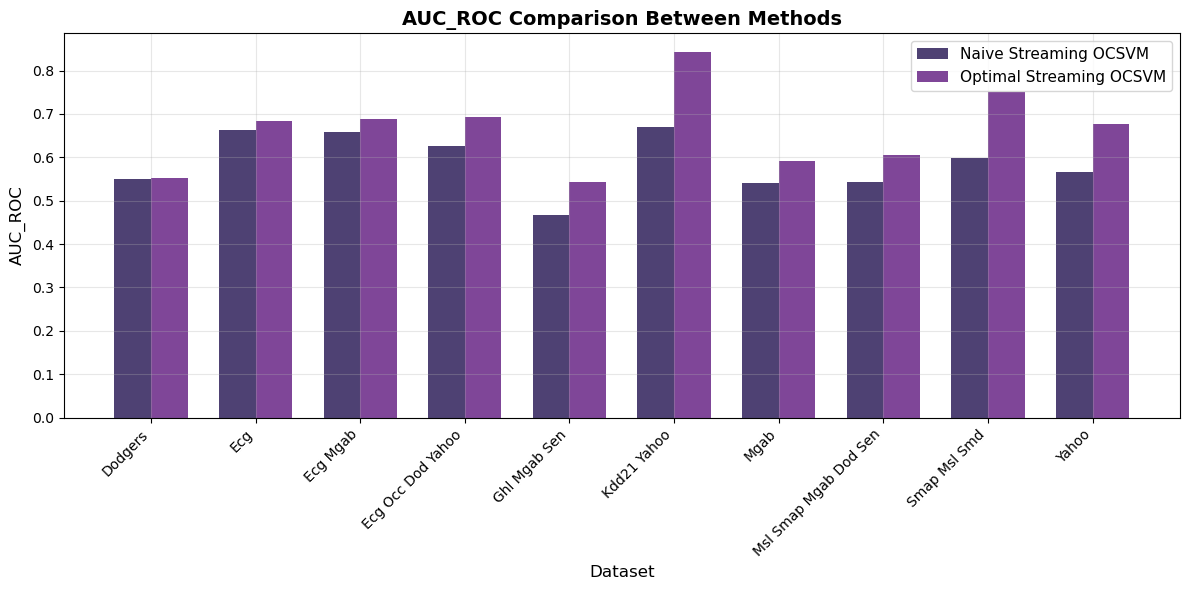

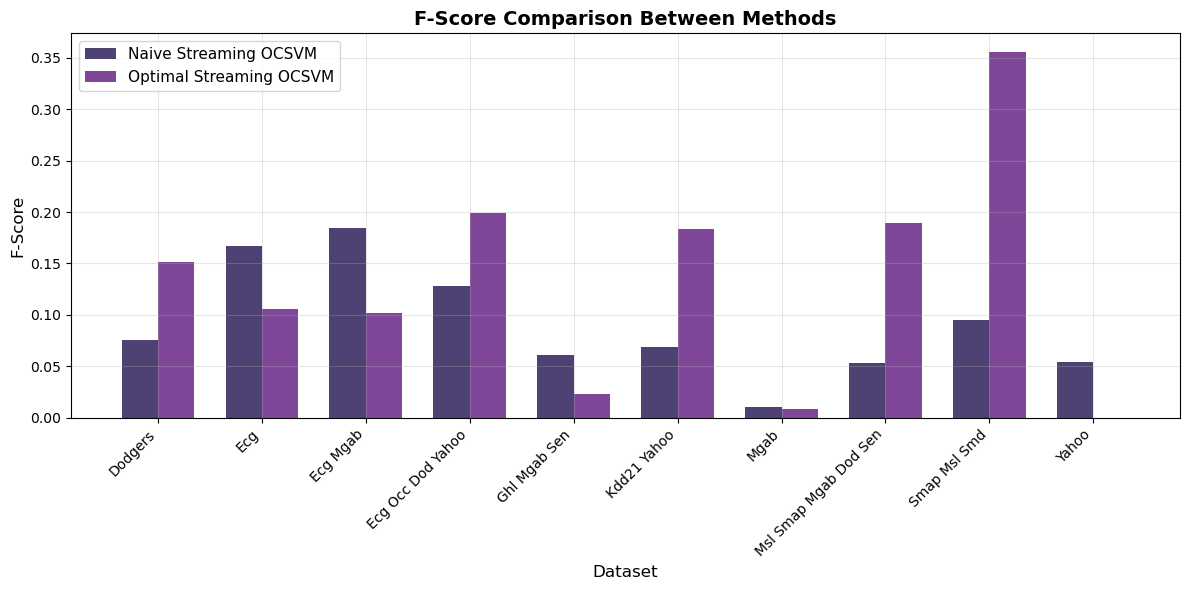

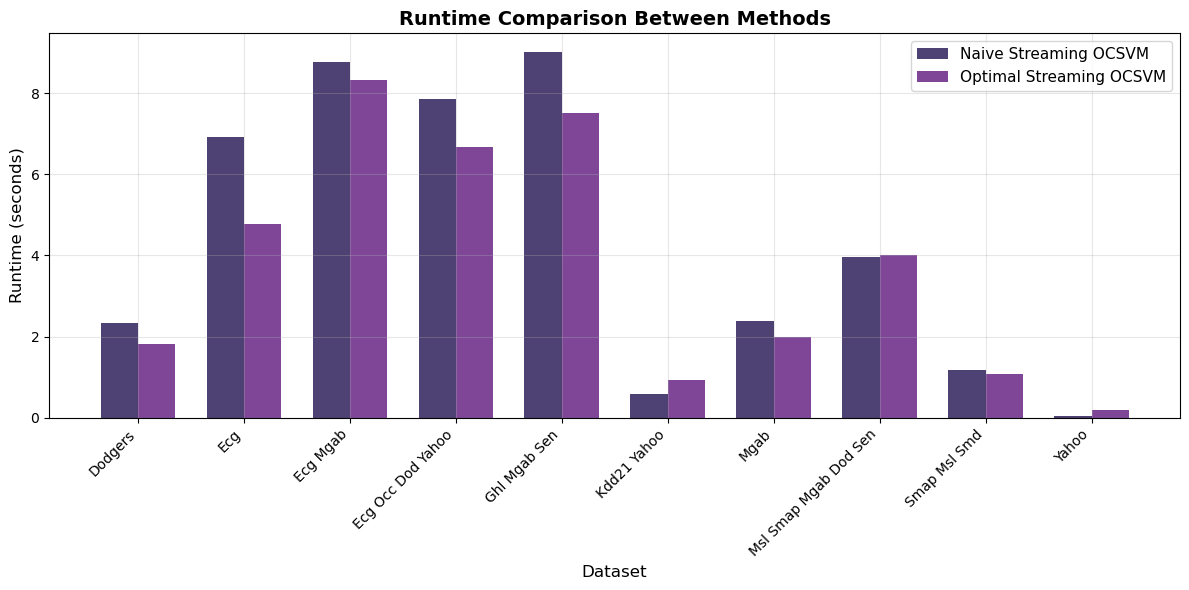

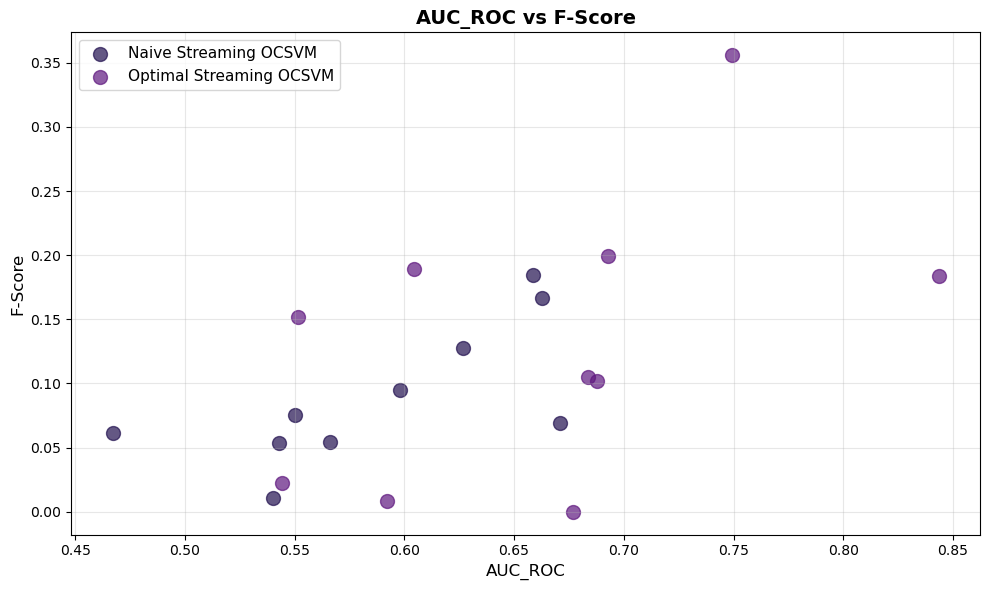

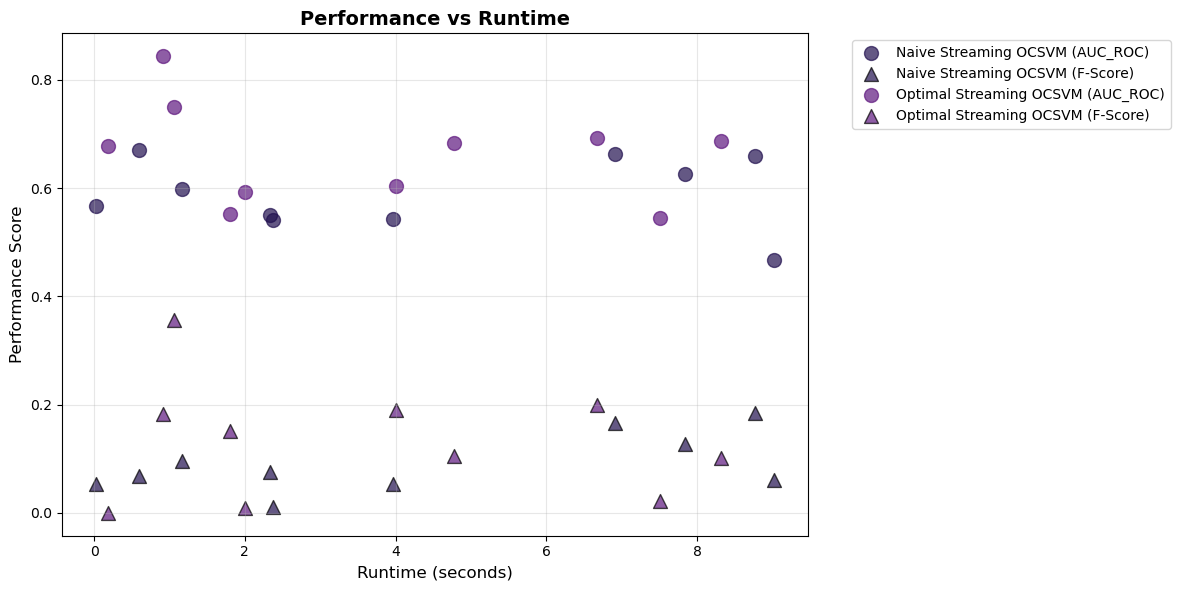

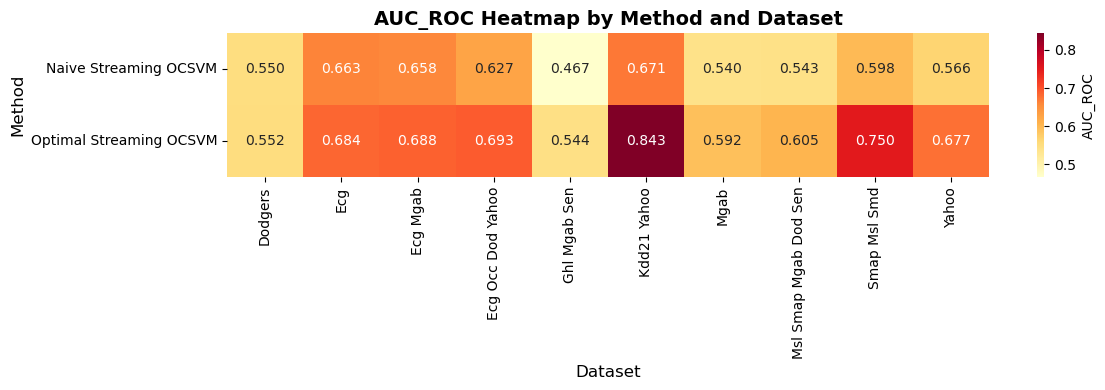

=== PERFORMANCE SUMMARY ===

AUC_ROC Summary:
                             mean       std       min       max
Method                                                         
Naive Streaming OCSVM    0.588264  0.066565  0.467062  0.670943
Optimal Streaming OCSVM  0.662652  0.092592  0.544112  0.843497

F-Score Summary:
                             mean       std       min       max
Method                                                         
Naive Streaming OCSVM    0.089775  0.054517  0.010526  0.184807
Optimal Streaming OCSVM  0.131823  0.109169  0.000000  0.355967

Runtime Summary:
                             mean       std       min       max
Method                                                         
Naive Streaming OCSVM    4.301250  3.513378  0.029265  9.019810
Optimal Streaming OCSVM  3.723202  2.969955  0.184718  8.317241

=== DATASET-WISE COMPARISON ===
                                    AUC_ROC                          \
Method                Naive Streaming OCSVM Op

In [22]:
# Clean dataset names for better visualization

offline_metrics_df['dataset_clean'] = offline_metrics_df['dataset'].apply(clean_dataset_name)
streaming_metrics_df['dataset_clean'] = streaming_metrics_df['dataset'].apply(clean_dataset_name)
simple_improved_metrics_df['dataset_clean'] = simple_improved_metrics_df['dataset'].apply(clean_dataset_name)

# Add method labels for clarity    ##here put your own dataframes
offline_metrics_df['Method'] = offline_metrics_df['dataset'].apply(clean_dataset_name)
streaming_metrics_df['Method'] = 'Naive Streaming OCSVM'
simple_improved_metrics_df['Method'] = 'Optimal Streaming OCSVM'

# Combine dataframes for comparison
combined_df = pd.concat([
    streaming_metrics_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    simple_improved_metrics_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']]
], ignore_index=True)

# Set up the plotting style
plt.style.use('default')
colors = sns.color_palette("magma") ##change this


# Create separate figures for each comparison
# Figure 1: AUC_ROC Comparison
fig1, ax1 = plt.subplots(figsize=(12, 6))
pivot_auc = combined_df.pivot(index='dataset_clean', columns='Method', values='AUC_ROC')
x = np.arange(len(pivot_auc.index))
width = 0.35

ax1.bar(x - width/2, pivot_auc.iloc[:, 0], width, label=pivot_auc.columns[0],
        color=colors[0], alpha=0.8)
ax1.bar(x + width/2, pivot_auc.iloc[:, 1], width, label=pivot_auc.columns[1],
        color=colors[1], alpha=0.8)

ax1.set_xlabel('Dataset', fontsize=12)
ax1.set_ylabel('AUC_ROC', fontsize=12)
ax1.set_title('AUC_ROC Comparison Between Methods', fontsize=14, fontweight='bold')
os.makedirs(f'{PLOTS_DIR}/', exist_ok=True)
fig1.savefig(f'{PLOTS_DIR}/ocsvm_v1_v2_auc_roc.png', bbox_inches='tight', dpi=150)
ax1.set_xticks(x)
ax1.set_xticklabels(pivot_auc.index, rotation=45, ha='right')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 2: F-Score Comparison
fig2, ax2 = plt.subplots(figsize=(12, 6))
pivot_f = combined_df.pivot(index='dataset_clean', columns='Method', values='F')

ax2.bar(x - width/2, pivot_f.iloc[:, 0], width, label=pivot_f.columns[0],
        color=colors[0], alpha=0.8)
ax2.bar(x + width/2, pivot_f.iloc[:, 1], width, label=pivot_f.columns[1],
        color=colors[1], alpha=0.8)

ax2.set_xlabel('Dataset', fontsize=12)
ax2.set_ylabel('F-Score', fontsize=12)
ax2.set_title('F-Score Comparison Between Methods', fontsize=14, fontweight='bold')
fig2.savefig(f'{PLOTS_DIR}/ocsvm_v1_v2_fscore.png', bbox_inches='tight', dpi=150)
ax2.set_xticks(x)
ax2.set_xticklabels(pivot_f.index, rotation=45, ha='right')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 3: Runtime Comparison
fig3, ax3 = plt.subplots(figsize=(12, 6))
pivot_runtime = combined_df.pivot(index='dataset_clean', columns='Method', values='runtime')

ax3.bar(x - width/2, pivot_runtime.iloc[:, 0], width, label=pivot_runtime.columns[0],
        color=colors[0], alpha=0.8)
ax3.bar(x + width/2, pivot_runtime.iloc[:, 1], width, label=pivot_runtime.columns[1],
        color=colors[1], alpha=0.8)

ax3.set_xlabel('Dataset', fontsize=12)
ax3.set_ylabel('Runtime (seconds)', fontsize=12)
ax3.set_title('Runtime Comparison Between Methods', fontsize=14, fontweight='bold')
fig3.savefig(f'{PLOTS_DIR}/ocsvm_v1_v2_runtime.png', bbox_inches='tight', dpi=150)
ax3.set_xticks(x)
ax3.set_xticklabels(pivot_runtime.index, rotation=45, ha='right')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 4: Scatter plot: AUC_ROC vs F-Score
fig4, ax4 = plt.subplots(figsize=(10, 6))
method_colors = {'Naive Streaming OCSVM': colors[0], 'Optimal Streaming OCSVM': colors[1]}
for i, method in enumerate(combined_df['Method'].unique()):
    method_data = combined_df[combined_df['Method'] == method]
    ax4.scatter(method_data['AUC_ROC'], method_data['F'],
               label=method, alpha=0.7, s=100, color=method_colors[method])

ax4.set_xlabel('AUC_ROC', fontsize=12)
ax4.set_ylabel('F-Score', fontsize=12)
ax4.set_title('AUC_ROC vs F-Score', fontsize=14, fontweight='bold')
ax4.legend(fontsize=11)
ax4.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 5: Performance vs Runtime scatter
fig5, ax5 = plt.subplots(figsize=(12, 6))
markers = ['o', '^']
for i, method in enumerate(combined_df['Method'].unique()):
    method_data = combined_df[combined_df['Method'] == method]
    ax5.scatter(method_data['runtime'], method_data['AUC_ROC'],
               label=f'{method} (AUC_ROC)', alpha=0.7, s=100,
               marker=markers[0], color=method_colors[method])
    ax5.scatter(method_data['runtime'], method_data['F'],
               label=f'{method} (F-Score)', alpha=0.7, s=100,
               marker=markers[1], color=method_colors[method], edgecolors='black')

ax5.set_xlabel('Runtime (seconds)', fontsize=12)
ax5.set_ylabel('Performance Score', fontsize=12)
ax5.set_title('Performance vs Runtime', fontsize=14, fontweight='bold')
ax5.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
ax5.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 6: Heatmap of AUC_ROC scores
fig6, ax6 = plt.subplots(figsize=(12, 4))
heatmap_data = pivot_auc.T
sns.heatmap(heatmap_data, annot=True, cmap='YlOrRd', fmt='.3f',
            cbar_kws={'label': 'AUC_ROC'}, ax=ax6)
ax6.set_title('AUC_ROC Heatmap by Method and Dataset', fontsize=14, fontweight='bold')
ax6.set_xlabel('Dataset', fontsize=12)
ax6.set_ylabel('Method', fontsize=12)
plt.tight_layout()
plt.show()

# Summary statistics
print("=== PERFORMANCE SUMMARY ===")
print("\nAUC_ROC Summary:")
auc_summary = combined_df.groupby('Method')['AUC_ROC'].agg(['mean', 'std', 'min', 'max'])
print(auc_summary)

print("\nF-Score Summary:")
f_summary = combined_df.groupby('Method')['F'].agg(['mean', 'std', 'min', 'max'])
print(f_summary)

print("\nRuntime Summary:")
runtime_summary = combined_df.groupby('Method')['runtime'].agg(['mean', 'std', 'min', 'max'])
print(runtime_summary)

print("\n=== DATASET-WISE COMPARISON ===")
comparison_df = combined_df.pivot_table(
    index='dataset_clean',
    columns='Method',
    values=['AUC_ROC', 'F', 'runtime']
)
print(comparison_df)

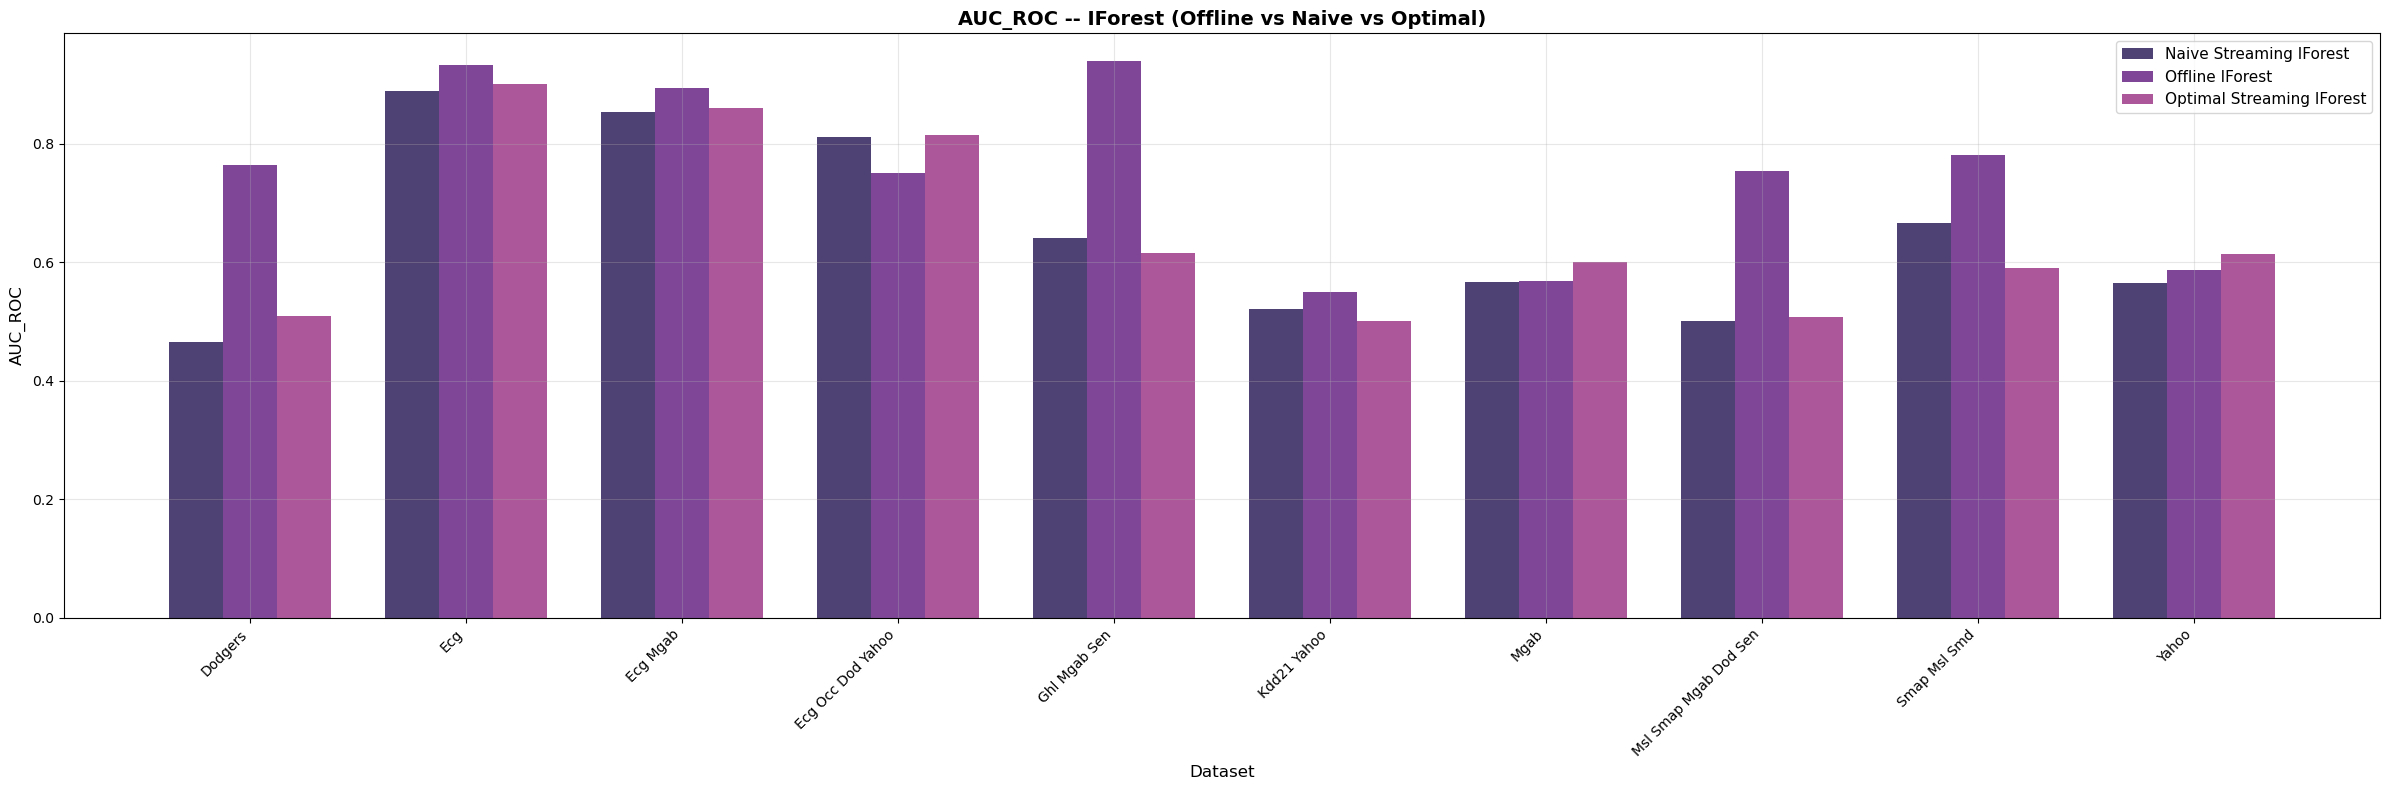

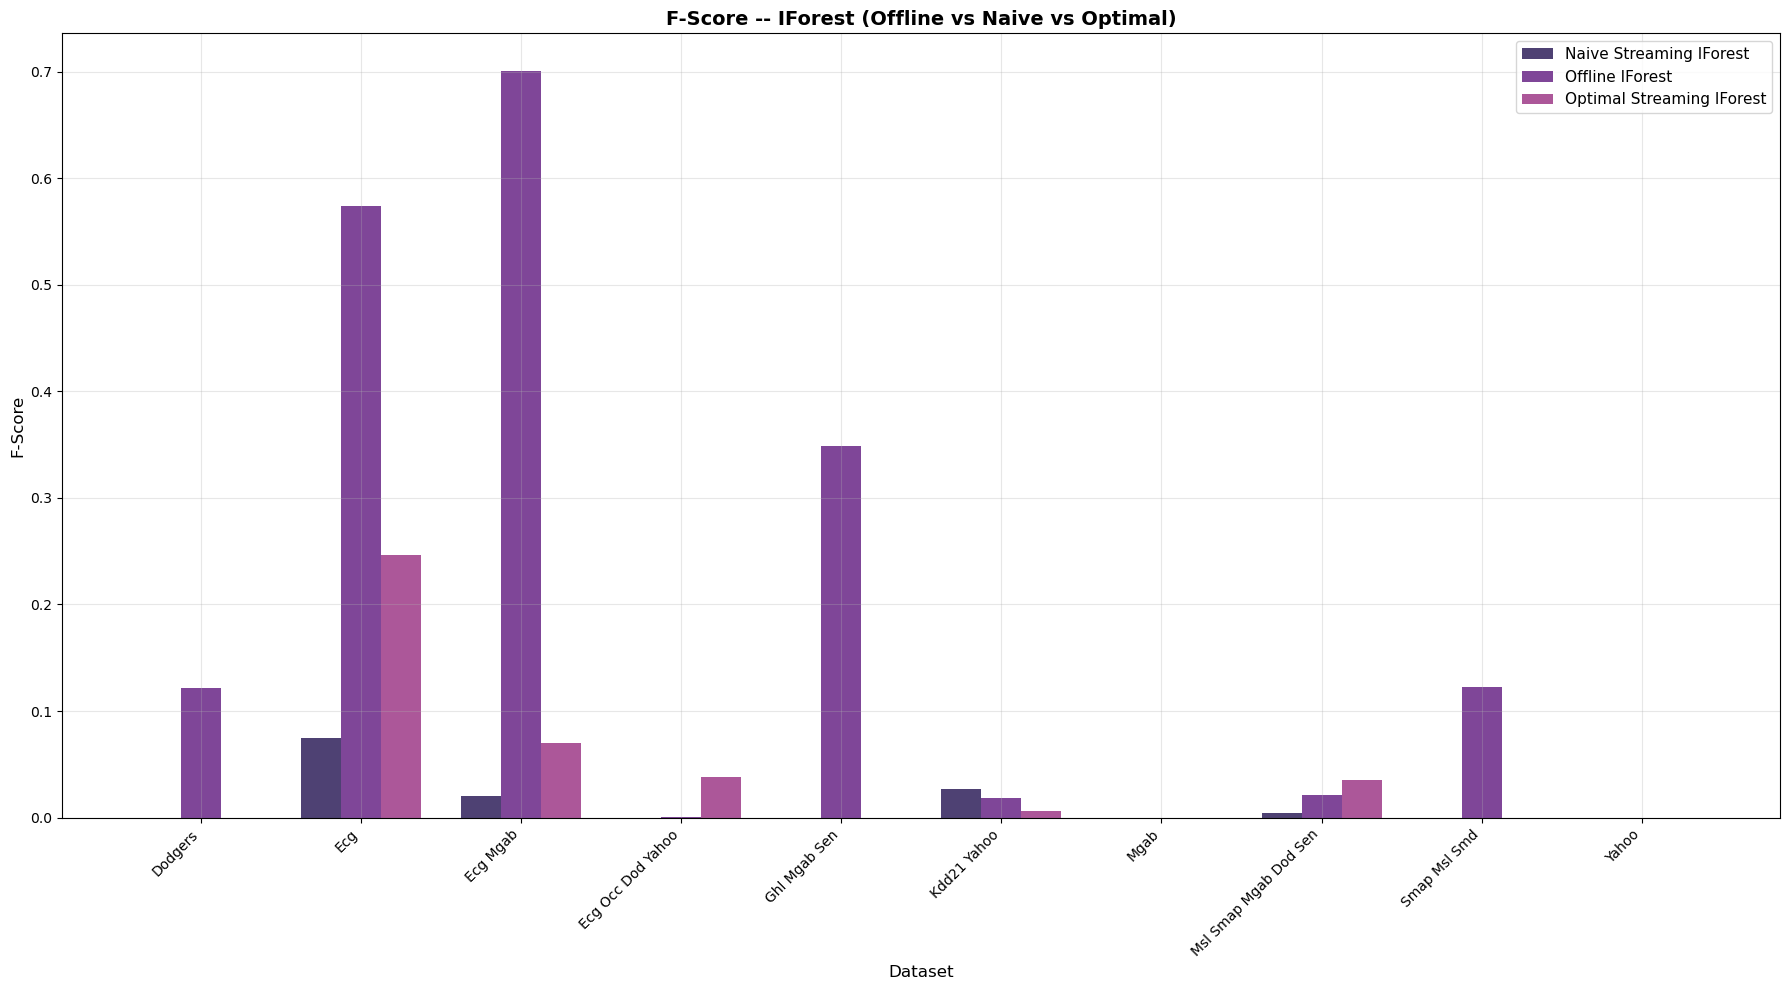

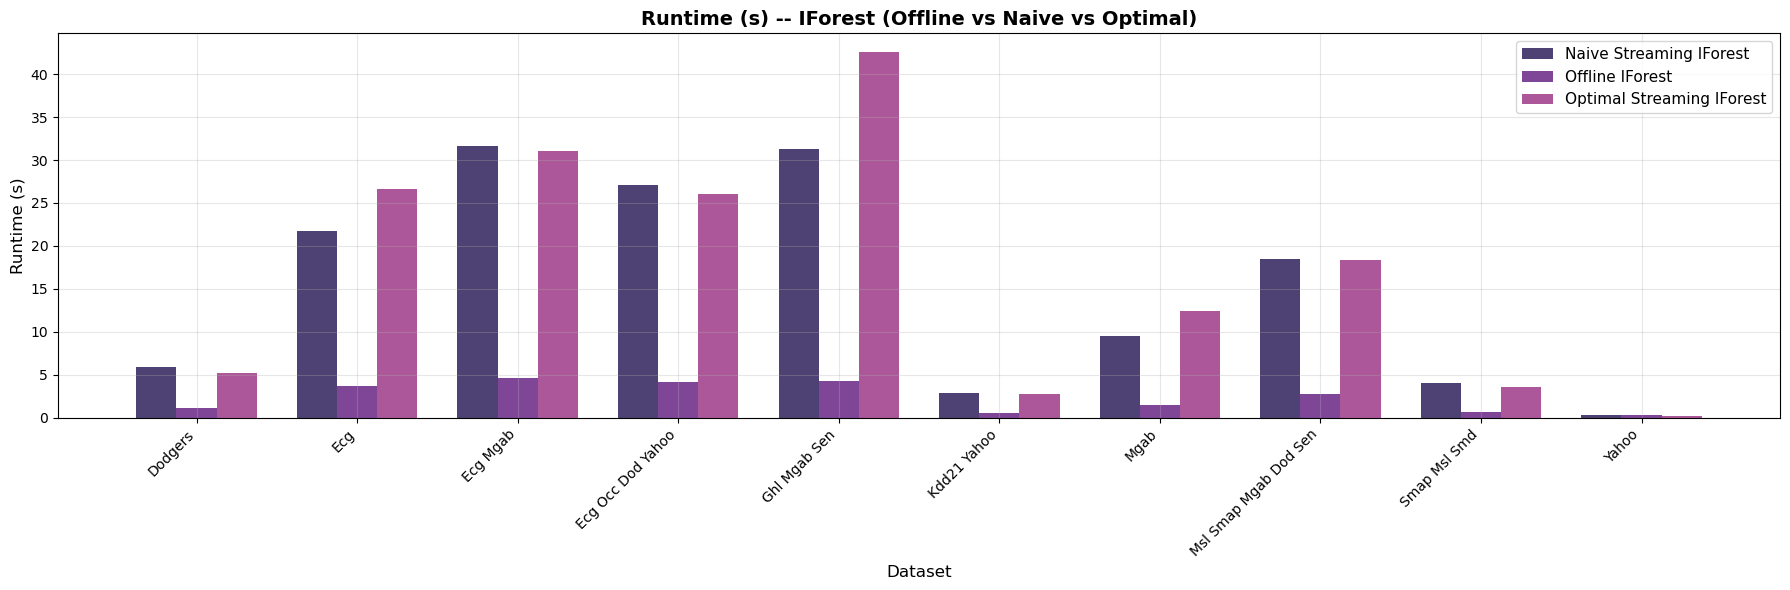

=== IFOREST FULL COMPARISON SUMMARY ===
                            AUC_ROC                   F              runtime  \
                               mean       std      mean       std       mean   
Method                                                                         
Naive Streaming IForest    0.647673  0.153264  0.012582  0.023780  15.295362   
Offline IForest            0.751961  0.145656  0.190749  0.260085   2.381004   
Optimal Streaming IForest  0.651296  0.150855  0.039623  0.076440  16.880798   

                                      
                                 std  
Method                                
Naive Streaming IForest    12.208285  
Offline IForest             1.717577  
Optimal Streaming IForest  14.367425  


In [23]:
iforest_offline_df = pd.read_csv(f'{METRICS_DIR}/isolation_forest_metrics.csv')
iforest_v1_df      = pd.read_csv(f'{METRICS_DIR}/isolation_forest_streaming_metrics_df.csv')
iforest_v2_df      = pd.read_csv(f'{METRICS_DIR}/isolation_forest_simple_improved_streaming_metrics_df.csv')

iforest_offline_df['dataset_clean'] = iforest_offline_df['dataset'].apply(clean_dataset_name)
iforest_v1_df['dataset_clean']      = iforest_v1_df['dataset'].apply(clean_dataset_name)
iforest_v2_df['dataset_clean']      = iforest_v2_df['dataset'].apply(clean_dataset_name)
iforest_offline_df['Method'] = 'Offline IForest'
iforest_v1_df['Method']      = 'Naive Streaming IForest'
iforest_v2_df['Method']      = 'Optimal Streaming IForest'

combined_df = pd.concat([
    iforest_offline_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    iforest_v1_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    iforest_v2_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']]
], ignore_index=True)

plt.style.use('default')
colors = sns.color_palette('magma')

for metric, title, fs in [('AUC_ROC','AUC_ROC',(24,8)), ('F','F-Score',(18,10)), ('runtime','Runtime (s)',(18,6))]:
    fig, ax = plt.subplots(figsize=fs)
    pivot = combined_df.pivot(index='dataset_clean', columns='Method', values=metric)
    x = np.arange(len(pivot.index)); width = 0.25
    ax.bar(x - width, pivot.iloc[:, 0], width, label=pivot.columns[0], color=colors[0], alpha=0.8)
    ax.bar(x,         pivot.iloc[:, 1], width, label=pivot.columns[1], color=colors[1], alpha=0.8)
    ax.bar(x + width, pivot.iloc[:, 2], width, label=pivot.columns[2], color=colors[2], alpha=0.8)
    ax.set_xlabel('Dataset', fontsize=12); ax.set_ylabel(title, fontsize=12)
    ax.set_title(f'{title} -- IForest (Offline vs Naive vs Optimal)', fontsize=14, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(pivot.index, rotation=45, ha='right')
    ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
    os.makedirs(f'{PLOTS_DIR}/', exist_ok=True)
    fig.savefig(f'{PLOTS_DIR}/iforest_full_{metric}.png', bbox_inches='tight', dpi=150)
    plt.tight_layout(); plt.show()

print('=== IFOREST FULL COMPARISON SUMMARY ===')
print(combined_df.groupby('Method')[['AUC_ROC', 'F', 'runtime']].agg(['mean', 'std']))

In [24]:
lstm_offline_df      = pd.read_csv(f'{METRICS_DIR}/lstm_metrics.csv')
lstm_naive_load_df   = pd.read_csv(f'{METRICS_DIR}/lstm_naive_metrics.csv')
lstm_incr_load_df    = pd.read_csv(f'{METRICS_DIR}/lstm_incremental_metrics.csv')

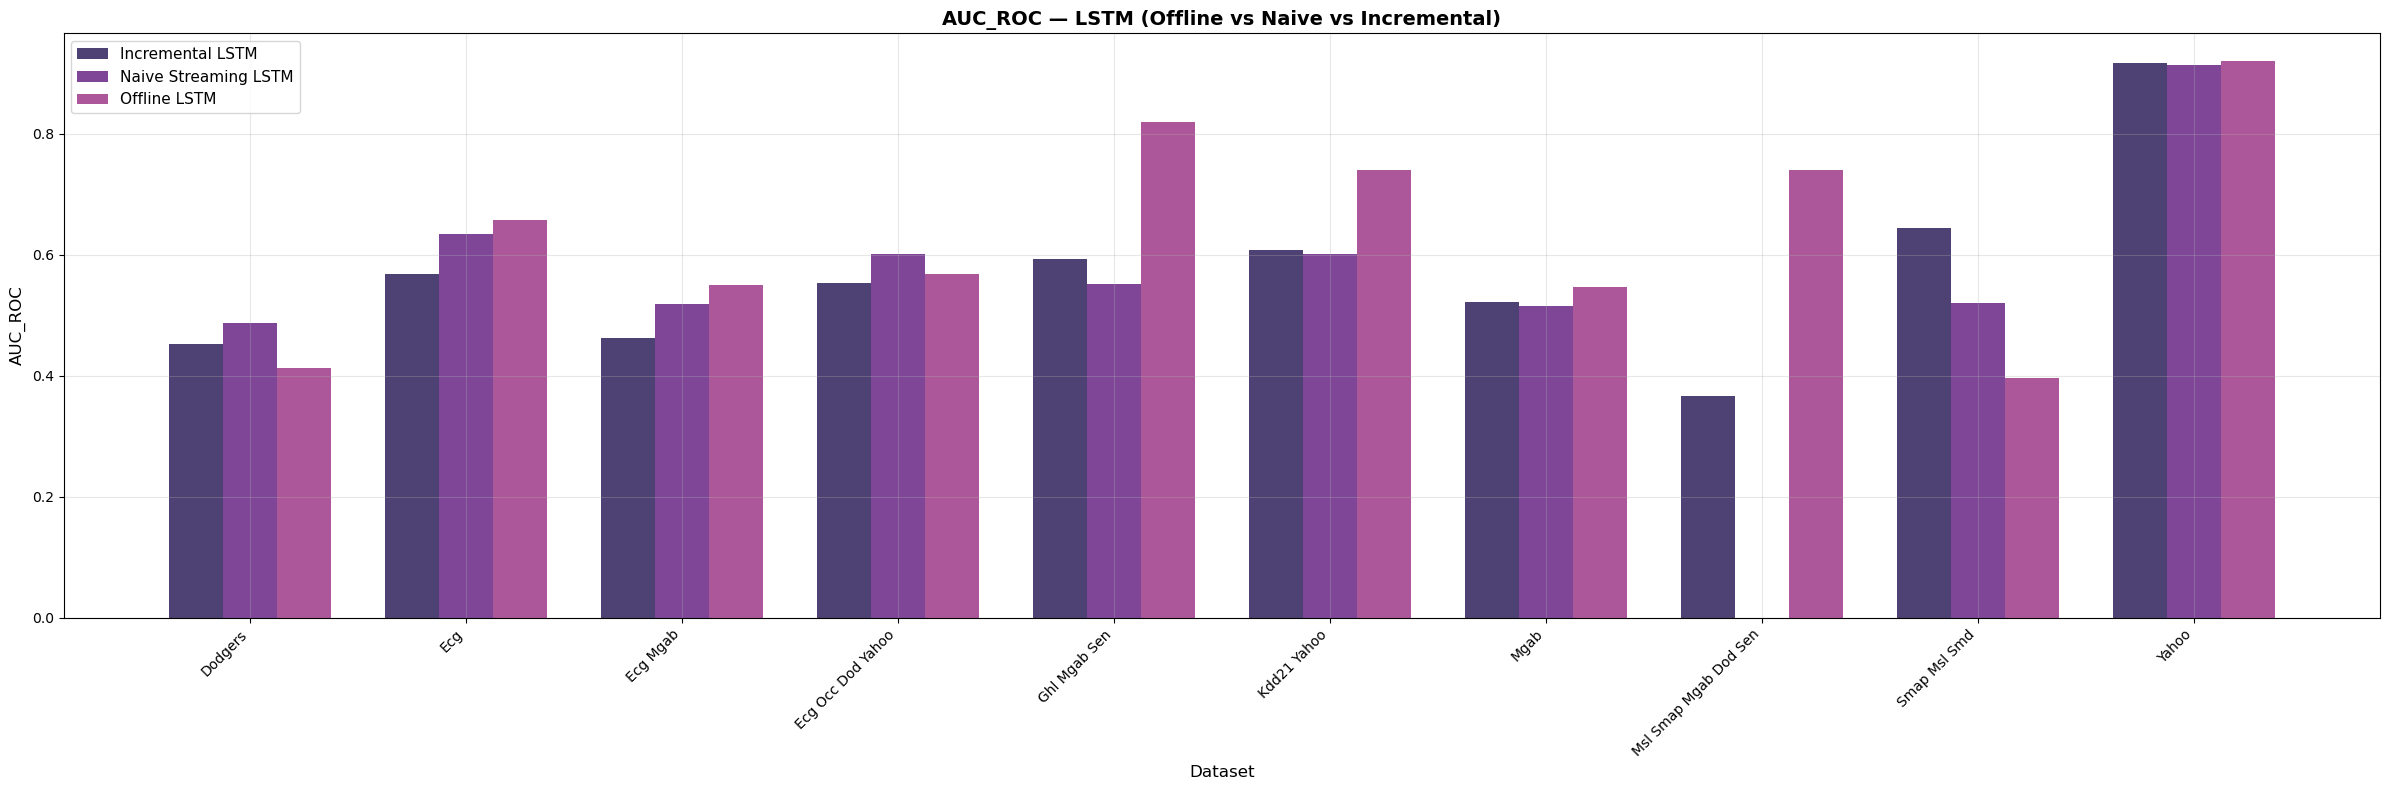

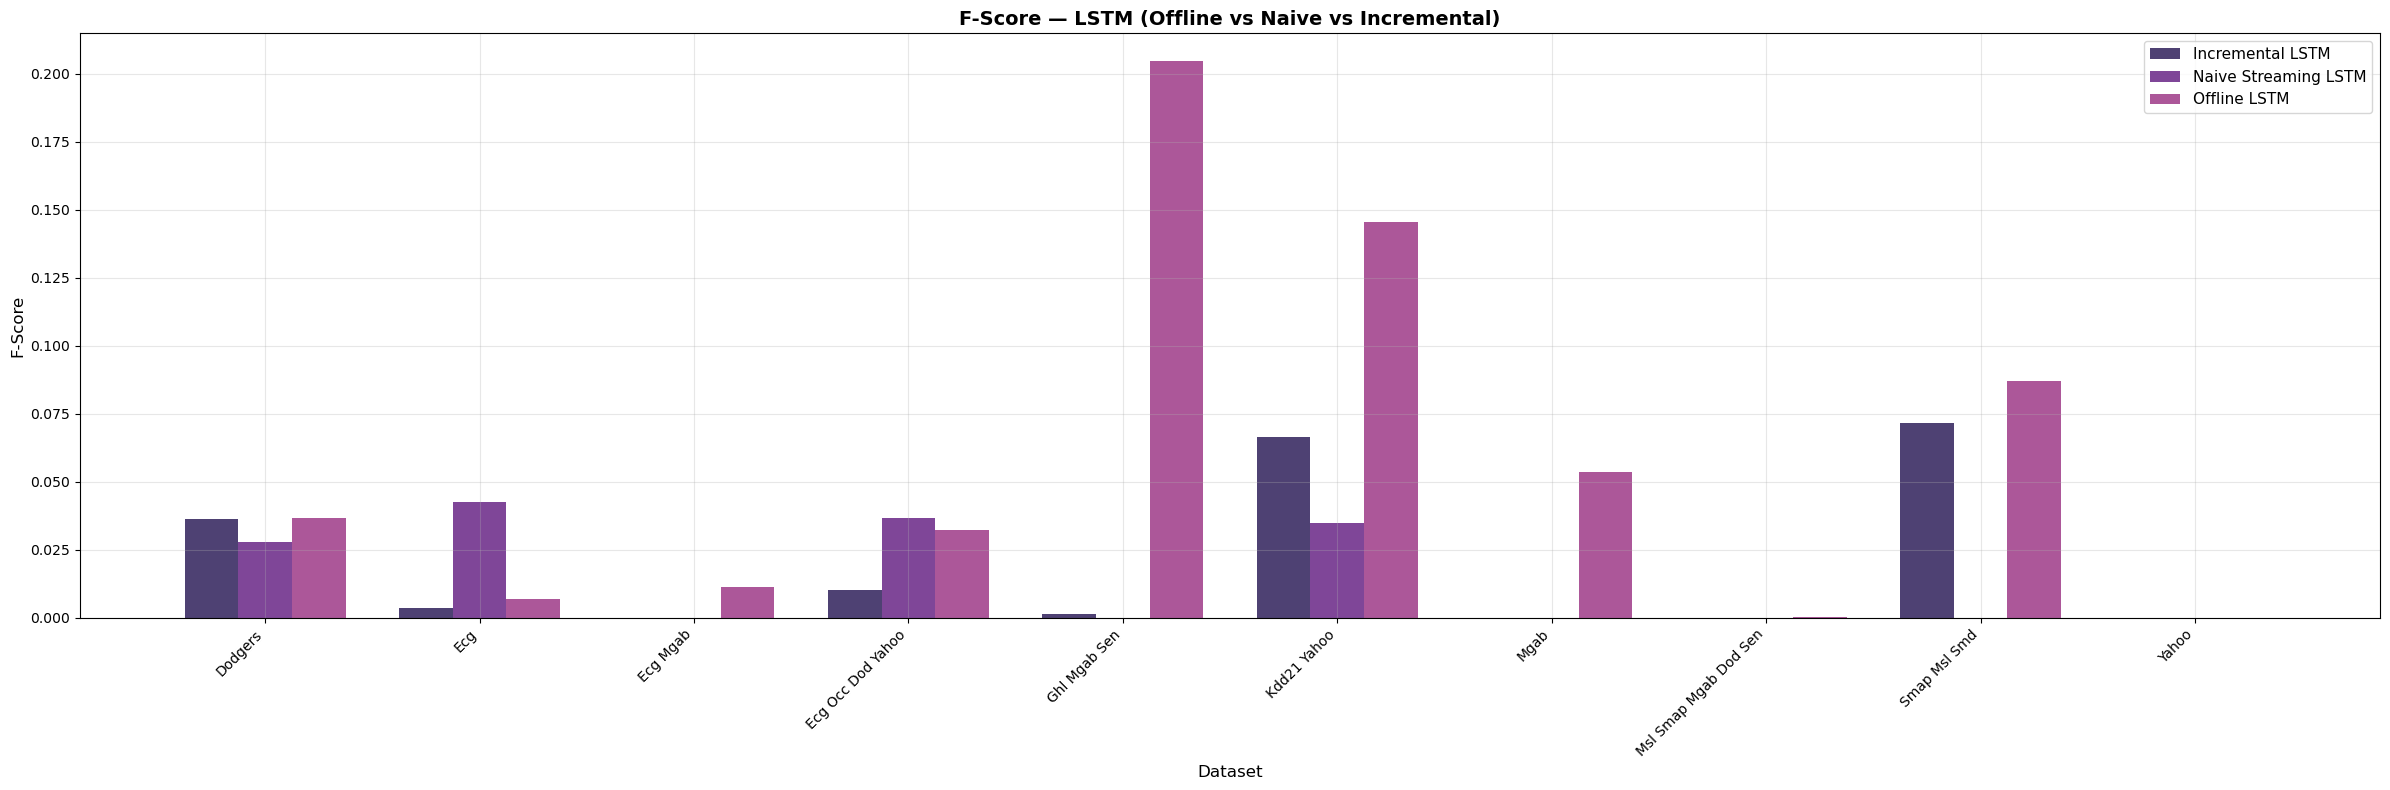

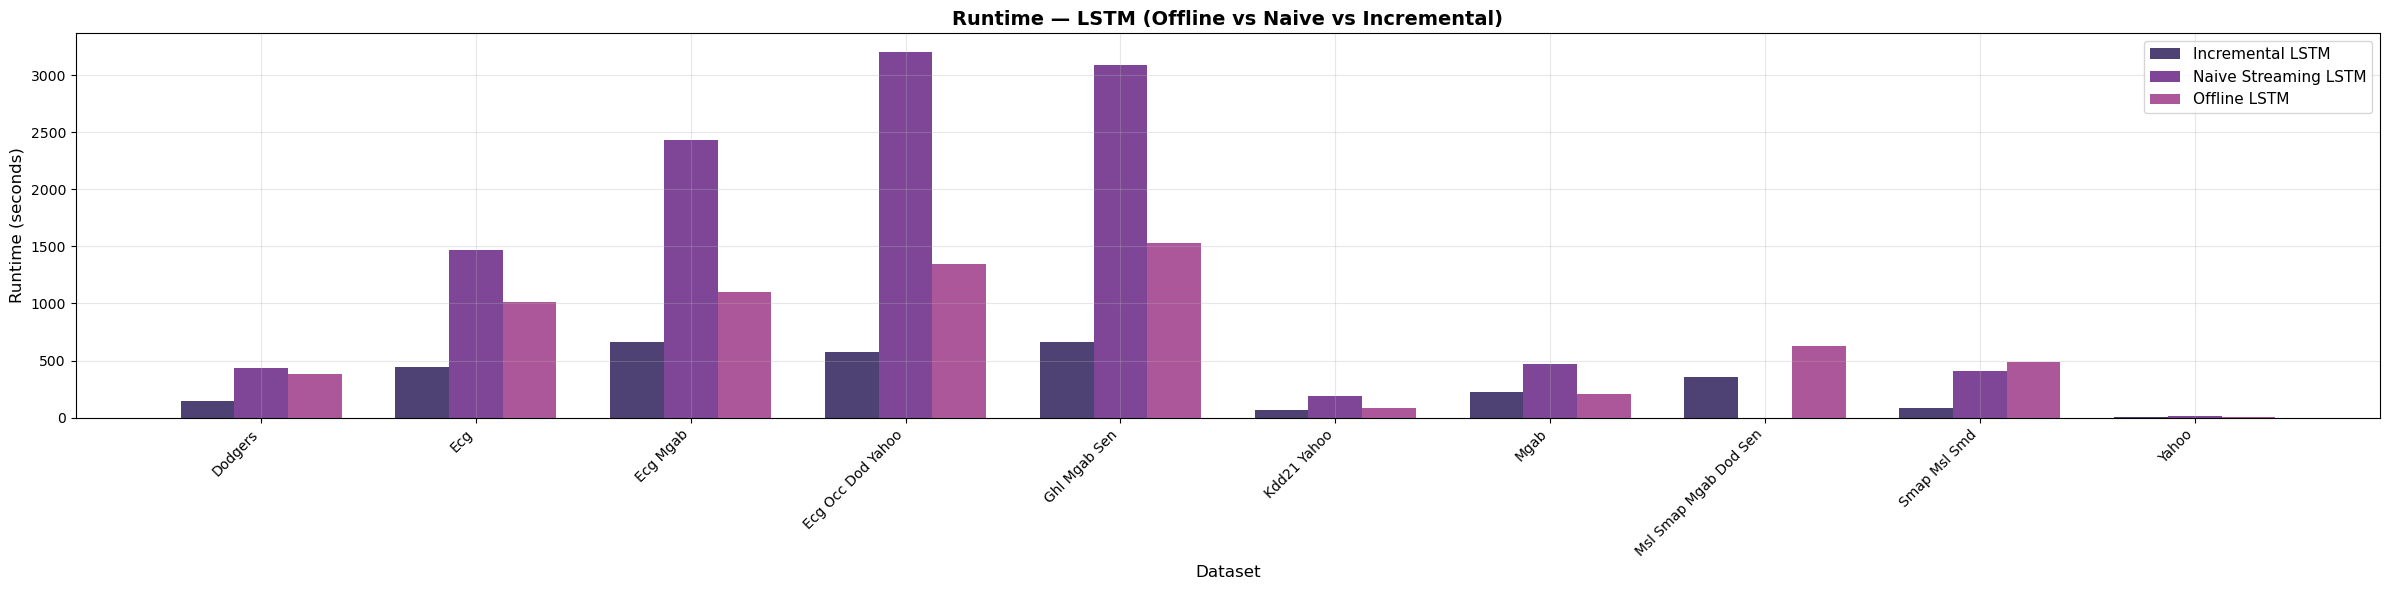

=== LSTM PERFORMANCE SUMMARY ===
                       AUC_ROC                   F                runtime  \
                          mean       std      mean       std         mean   
Method                                                                      
Incremental LSTM      0.569184  0.148149  0.018919  0.028567   322.981166   
Naive Streaming LSTM  0.594089  0.129589  0.015733  0.019023  1299.335234   
Offline LSTM          0.635515  0.171268  0.057752  0.068784   678.686599   

                                   
                              std  
Method                             
Incremental LSTM       252.519343  
Naive Streaming LSTM  1288.492549  
Offline LSTM           540.702216  


In [25]:
lstm_offline_df['dataset_clean']    = lstm_offline_df['dataset'].apply(clean_dataset_name)
lstm_naive_load_df['dataset_clean'] = lstm_naive_load_df['dataset'].apply(clean_dataset_name)
lstm_incr_load_df['dataset_clean']  = lstm_incr_load_df['dataset'].apply(clean_dataset_name)

lstm_offline_df['Method']    = 'Offline LSTM'
lstm_naive_load_df['Method'] = 'Naive Streaming LSTM'
lstm_incr_load_df['Method']  = 'Incremental LSTM'

combined_df = pd.concat([
    lstm_offline_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    lstm_naive_load_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']],
    lstm_incr_load_df[['dataset_clean', 'AUC_ROC', 'F', 'runtime', 'Method']]
], ignore_index=True)

os.makedirs(PLOTS_DIR, exist_ok=True)
plt.style.use('default')
colors = sns.color_palette("magma")
x = np.arange(len(combined_df['dataset_clean'].unique()))
width = 0.25

# Figure 1: AUC_ROC
fig1, ax1 = plt.subplots(figsize=(24, 8))
pivot_auc = combined_df.pivot(index='dataset_clean', columns='Method', values='AUC_ROC')
ax1.bar(x - width, pivot_auc.iloc[:, 0], width, label=pivot_auc.columns[0], color=colors[0], alpha=0.8)
ax1.bar(x,         pivot_auc.iloc[:, 1], width, label=pivot_auc.columns[1], color=colors[1], alpha=0.8)
ax1.bar(x + width, pivot_auc.iloc[:, 2], width, label=pivot_auc.columns[2], color=colors[2], alpha=0.8)
ax1.set_xlabel('Dataset', fontsize=12)
ax1.set_ylabel('AUC_ROC', fontsize=12)
ax1.set_title('AUC_ROC — LSTM (Offline vs Naive vs Incremental)', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(pivot_auc.index, rotation=45, ha='right')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
fig1.savefig(f'{PLOTS_DIR}/lstm_full_AUC_ROC.png', bbox_inches='tight', dpi=150)
plt.show()

# Figure 2: F-Score
fig2, ax2 = plt.subplots(figsize=(24, 8))
pivot_f = combined_df.pivot(index='dataset_clean', columns='Method', values='F')
ax2.bar(x - width, pivot_f.iloc[:, 0], width, label=pivot_f.columns[0], color=colors[0], alpha=0.8)
ax2.bar(x,         pivot_f.iloc[:, 1], width, label=pivot_f.columns[1], color=colors[1], alpha=0.8)
ax2.bar(x + width, pivot_f.iloc[:, 2], width, label=pivot_f.columns[2], color=colors[2], alpha=0.8)
ax2.set_xlabel('Dataset', fontsize=12)
ax2.set_ylabel('F-Score', fontsize=12)
ax2.set_title('F-Score — LSTM (Offline vs Naive vs Incremental)', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(pivot_f.index, rotation=45, ha='right')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
fig2.savefig(f'{PLOTS_DIR}/lstm_full_F.png', bbox_inches='tight', dpi=150)
plt.show()

# Figure 3: Runtime
fig3, ax3 = plt.subplots(figsize=(24, 6))
pivot_runtime = combined_df.pivot(index='dataset_clean', columns='Method', values='runtime')
ax3.bar(x - width, pivot_runtime.iloc[:, 0], width, label=pivot_runtime.columns[0], color=colors[0], alpha=0.8)
ax3.bar(x,         pivot_runtime.iloc[:, 1], width, label=pivot_runtime.columns[1], color=colors[1], alpha=0.8)
ax3.bar(x + width, pivot_runtime.iloc[:, 2], width, label=pivot_runtime.columns[2], color=colors[2], alpha=0.8)
ax3.set_xlabel('Dataset', fontsize=12)
ax3.set_ylabel('Runtime (seconds)', fontsize=12)
ax3.set_title('Runtime — LSTM (Offline vs Naive vs Incremental)', fontsize=14, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(pivot_runtime.index, rotation=45, ha='right')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)
plt.tight_layout()
fig3.savefig(f'{PLOTS_DIR}/lstm_full_runtime.png', bbox_inches='tight', dpi=150)
plt.show()

print("=== LSTM PERFORMANCE SUMMARY ===")
print(combined_df.groupby('Method')[['AUC_ROC', 'F', 'runtime']].agg(['mean', 'std']))


## Poster Visualizations

Run after all evaluation cells. Generates poster-quality plots saved to Drive.

| Plot file | Content |
|-----------|---------|
| `poster_ts_samples.png` | Time series + anomaly regions (dataset intro) |
| `poster_grand_heatmap_auc_roc.png` | AUC-ROC: all methods × all datasets (SAND paper style) |
| `poster_avg_performance.png` | Average AUC-ROC summary bar chart |
| `poster_streaming_improvement.png` | Offline vs V1 (Naive) vs V2 (Improved) per family |
| `poster_runtime_analysis.png` | Runtime heatmap + accuracy–runtime trade-off scatter |

In [18]:
BASE     = f'{METRICS_DIR}/'
PLOT_DIR = f'{PLOTS_DIR}/'
os.makedirs(PLOT_DIR, exist_ok=True)

METHOD_FILES = {
    'IF Offline':     'isolation_forest_metrics.csv',
    'IF Naive':       'isolation_forest_streaming_metrics_df.csv',
    'IF Drift':       'isolation_forest_simple_improved_streaming_metrics_df.csv',
    'OCSVM Offline':  'ocsvm_metrics.csv',
    'OCSVM Naive':    'ocsvm_metrics_batch_3000_2.csv',
    'OCSVM KMeans':   'ocsvm_metrics_batch_3000_v2_2.csv',
    'LSTM Offline':   'lstm_metrics.csv',
    'LSTM Naive':     'lstm_naive_metrics.csv',
    'LSTM ExpReplay': 'lstm_incremental_metrics.csv',
    'SAND':           'sand_metrics.csv',
}

DATASET_NAMES = {
    'yahoo':                 'Yahoo (N1)',
    'dodgers':               'Dodgers (N1)',
    'mgab':                  'MGAB (N1)',
    'ecg':                   'ECG (N1)',
    'kdd21_yahoo':           'KDD+Yahoo (N2)',
    'ecg_mgab':              'ECG+MGAB (N2)',
    'ghl_mgab_sen':          'GHL+MGAB+SS (N3)',
    'smap_msl_smd':          'SMAP+MSL+SMD (N3)',
    'ecg_occ_dod_yahoo':     'ECG+Occ+Dod+Yahoo (N4)',
    'msl_smap_mgab_dod_sen': 'All Domains (N5)',
}

FAMILY_COLORS = {
    'IF Offline':     '#1565C0',
    'IF Naive':       '#5C9FD6',
    'IF Drift':       '#0D47A1',
    'OCSVM Offline':  '#E65100',
    'OCSVM Naive':    '#FFAB76',
    'OCSVM KMeans':   '#BF360C',
    'LSTM Offline':   '#2E7D32',
    'LSTM Naive':     '#81C784',
    'LSTM ExpReplay': '#1B5E20',
    'SAND':           '#6A1B9A',
}

TICK_COLORS = {
    'IF Offline': '#1565C0', 'IF Naive': '#1565C0', 'IF Drift': '#1565C0',
    'OCSVM Offline': '#E65100', 'OCSVM Naive': '#E65100', 'OCSVM KMeans': '#E65100',
    'LSTM Offline': '#2E7D32', 'LSTM Naive': '#2E7D32', 'LSTM ExpReplay': '#2E7D32',
    'SAND': '#6A1B9A',
}

dfs = []
for method, fname in METHOD_FILES.items():
    try:
        df = pd.read_csv(BASE + fname)
        df['Method'] = method
        df['dataset_label'] = df['dataset'].map(lambda x: DATASET_NAMES.get(x, x))
        dfs.append(df[['dataset', 'dataset_label', 'Method', 'AUC_ROC', 'F', 'runtime']])
    except Exception as e:
        print(f"Warning: could not load {fname}: {e}")

all_df = pd.concat(dfs, ignore_index=True)
METHOD_ORDER = list(METHOD_FILES.keys())
print(f"Loaded {len(all_df)} rows | {all_df['Method'].nunique()} methods | {all_df['dataset'].nunique()} datasets")

Loaded 99 rows | 10 methods | 10 datasets


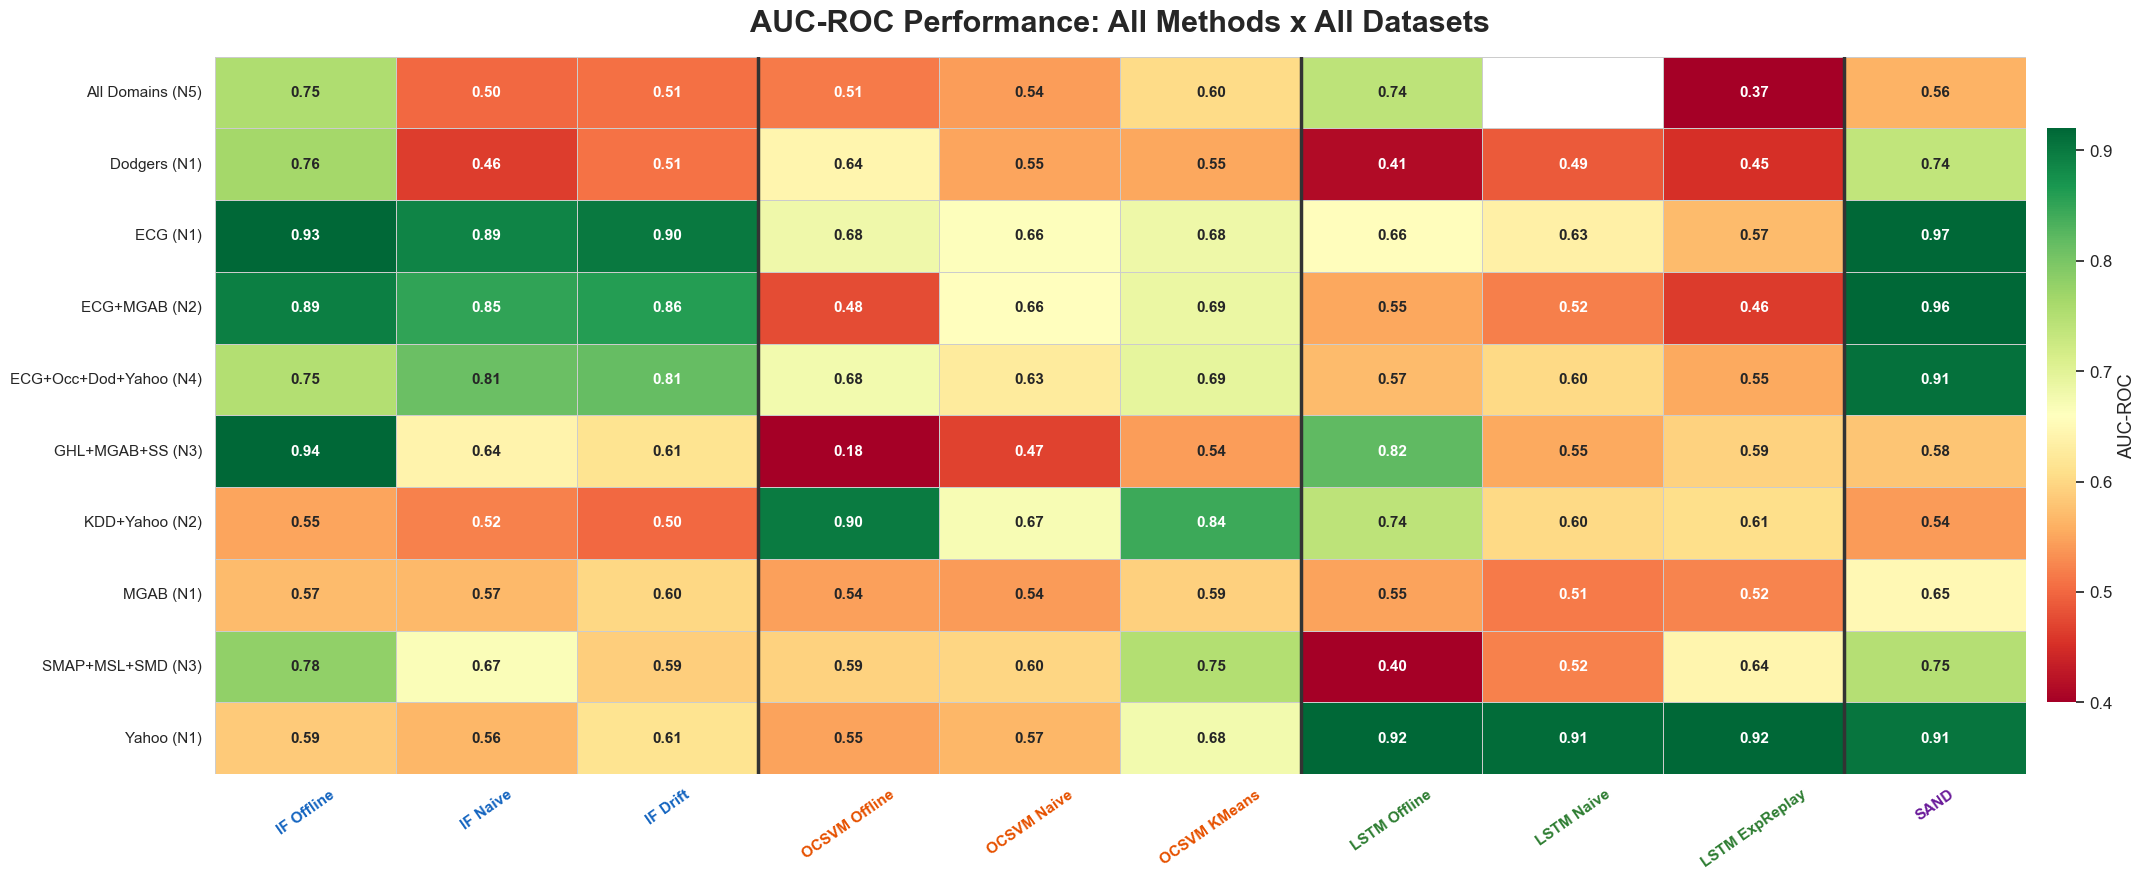

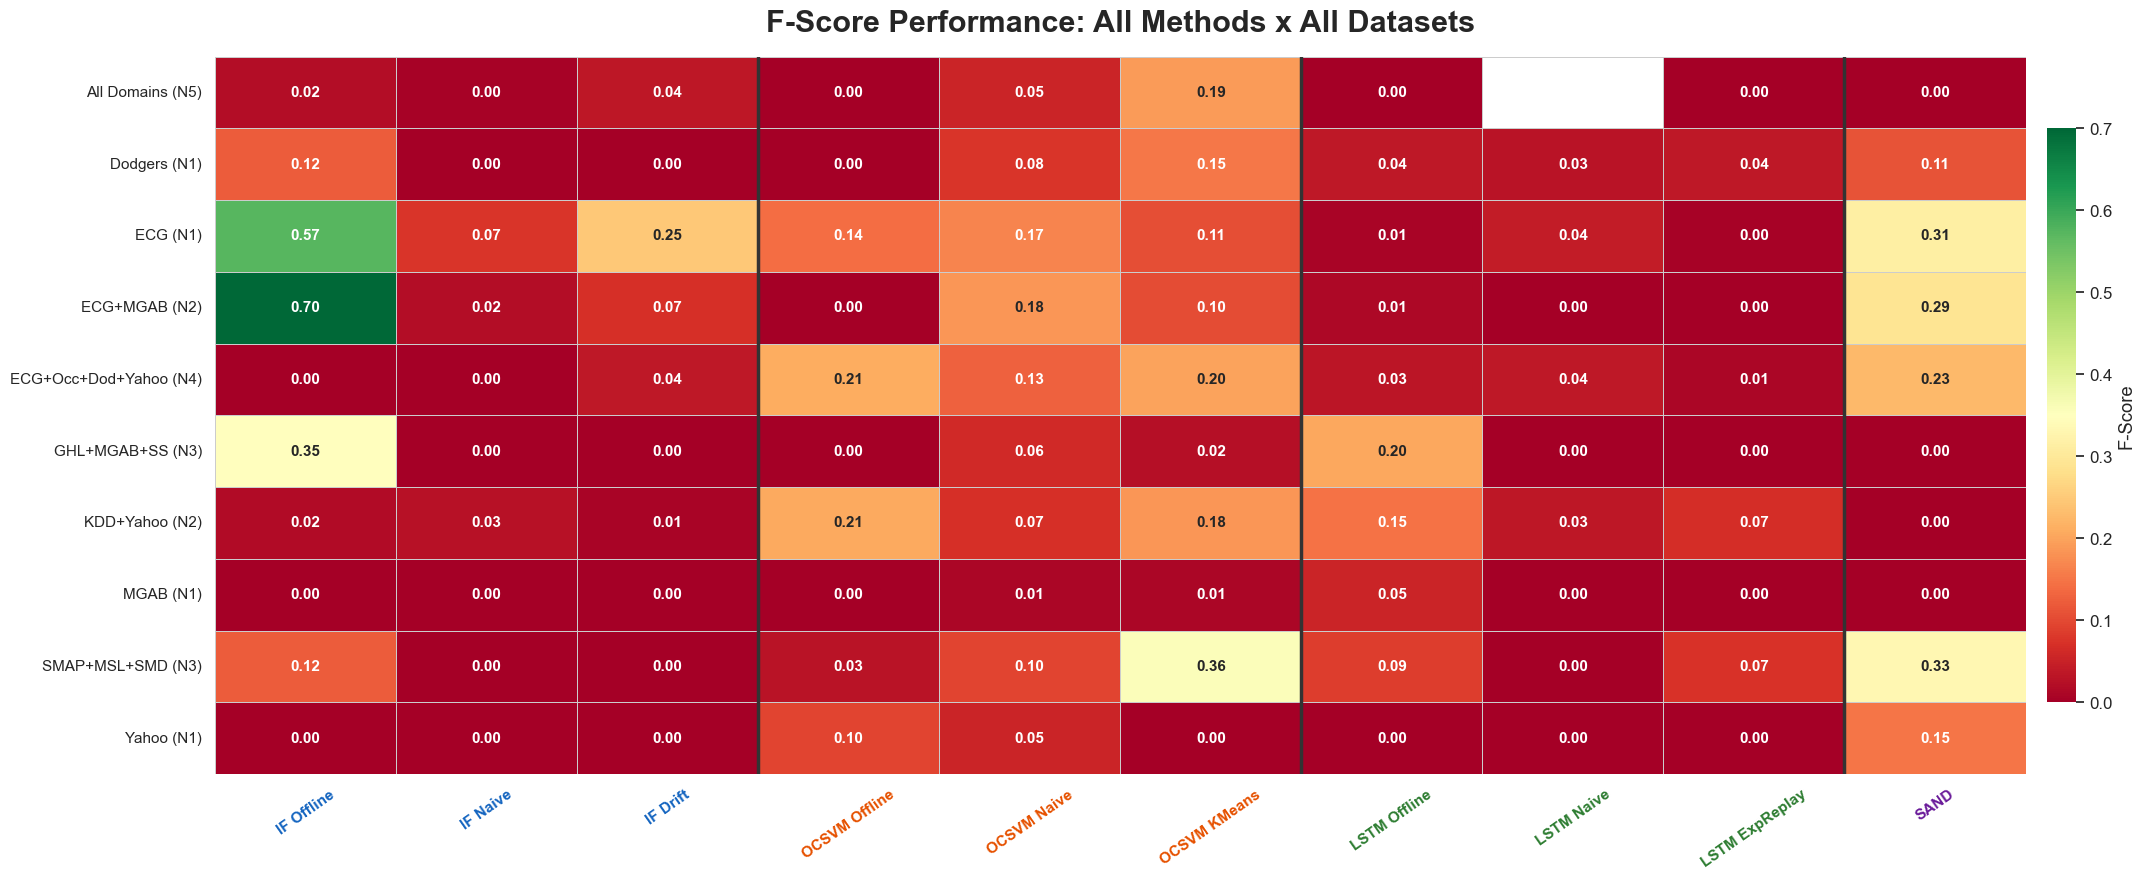

Saved: poster_grand_heatmap_auc_roc.png, poster_grand_heatmap_fscore.png


In [27]:
# --- Poster Plot 1: Grand AUC-ROC Heatmap (SAND paper style) ---
pivot_auc = all_df.pivot_table(index='dataset_label', columns='Method', values='AUC_ROC', aggfunc='mean')
pivot_auc = pivot_auc[[c for c in METHOD_ORDER if c in pivot_auc.columns]]

sns.set_theme(style='white', font_scale=1.1)
fig, ax = plt.subplots(figsize=(24, 9))

sns.heatmap(
    pivot_auc, ax=ax,
    cmap='RdYlGn', vmin=0.4, vmax=0.92,
    annot=True, fmt='.2f', annot_kws={'size': 11, 'weight': 'bold'},
    linewidths=0.6, linecolor='#cccccc',
    cbar_kws={'label': 'AUC-ROC', 'shrink': 0.8, 'pad': 0.01}
)

ax.set_title('AUC-ROC Performance: All Methods x All Datasets', fontsize=22, fontweight='bold', pad=18)
ax.set_xlabel(''); ax.set_ylabel('')
ax.tick_params(axis='x', rotation=35, labelsize=11)
ax.tick_params(axis='y', rotation=0,  labelsize=11)

for tick in ax.get_xticklabels():
    tick.set_color(TICK_COLORS.get(tick.get_text(), 'black'))
    tick.set_weight('bold')

for x_pos in [3, 6, 9]:
    ax.axvline(x=x_pos, color='#333333', linewidth=2.5)

plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_grand_heatmap_auc_roc.png', dpi=300, bbox_inches='tight')
plt.show()

# F-Score heatmap
pivot_f = all_df.pivot_table(index='dataset_label', columns='Method', values='F', aggfunc='mean')
pivot_f = pivot_f[[c for c in METHOD_ORDER if c in pivot_f.columns]]

fig2, ax2 = plt.subplots(figsize=(24, 9))
sns.heatmap(
    pivot_f, ax=ax2,
    cmap='RdYlGn', vmin=0.0, vmax=0.7,
    annot=True, fmt='.2f', annot_kws={'size': 11, 'weight': 'bold'},
    linewidths=0.6, linecolor='#cccccc',
    cbar_kws={'label': 'F-Score', 'shrink': 0.8, 'pad': 0.01}
)
ax2.set_title('F-Score Performance: All Methods x All Datasets', fontsize=22, fontweight='bold', pad=18)
ax2.set_xlabel(''); ax2.set_ylabel('')
ax2.tick_params(axis='x', rotation=35, labelsize=11)
ax2.tick_params(axis='y', rotation=0,  labelsize=11)

for tick in ax2.get_xticklabels():
    tick.set_color(TICK_COLORS.get(tick.get_text(), 'black'))
    tick.set_weight('bold')
for x_pos in [3, 6, 9]:
    ax2.axvline(x=x_pos, color='#333333', linewidth=2.5)

plt.tight_layout()
fig2.savefig(PLOT_DIR + 'poster_grand_heatmap_fscore.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: poster_grand_heatmap_auc_roc.png, poster_grand_heatmap_fscore.png")

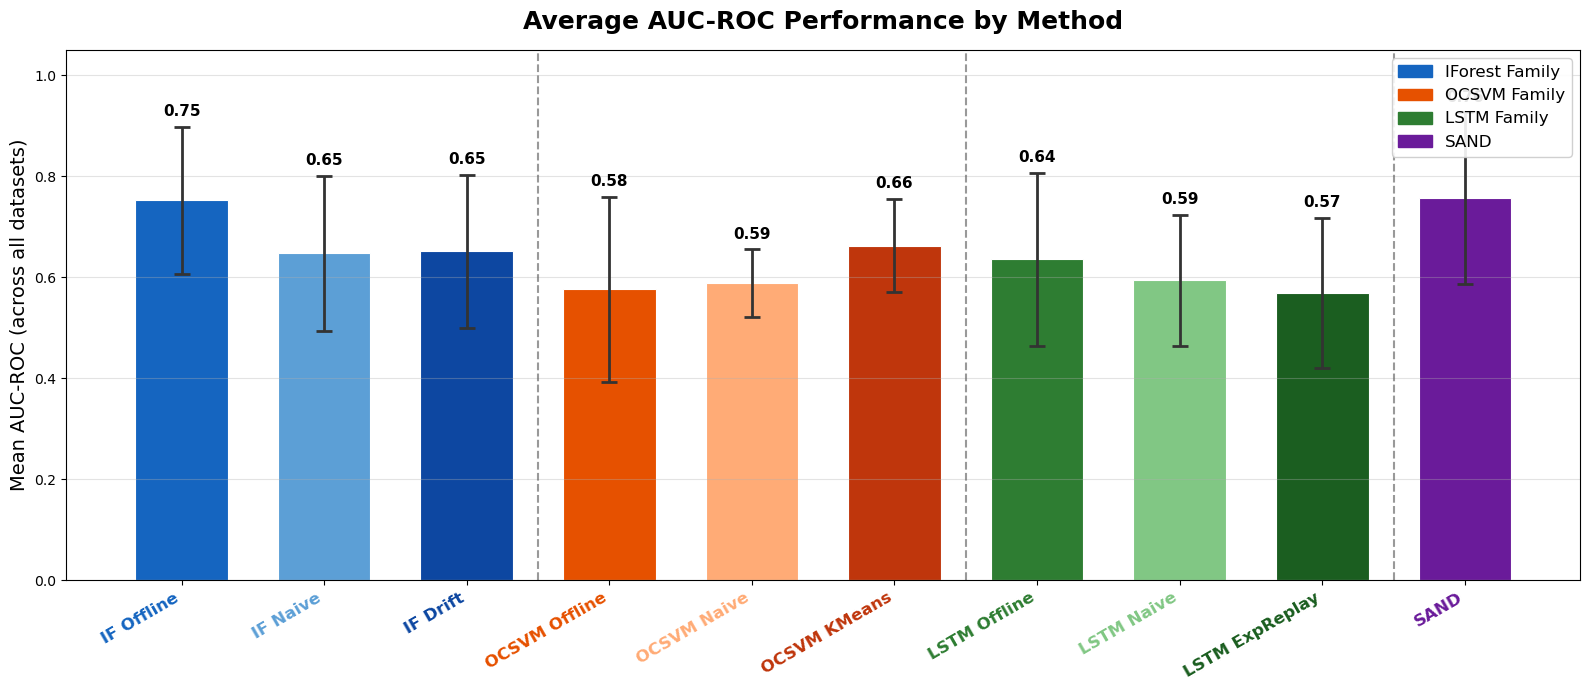

Saved: poster_avg_performance.png


In [30]:
# --- Poster Plot 2: Average AUC-ROC Bar Chart ---
avg = all_df.groupby('Method')['AUC_ROC'].agg(['mean', 'std']).reindex(METHOD_ORDER)
colors = [FAMILY_COLORS[m] for m in METHOD_ORDER]

fig, ax = plt.subplots(figsize=(16, 7))
fig.patch.set_facecolor('none')
ax.set_facecolor('none')
x = np.arange(len(METHOD_ORDER))

bars = ax.bar(x, avg['mean'], yerr=avg['std'], capsize=6,
              color=colors, edgecolor='white', linewidth=0.8, width=0.65,
              error_kw={'linewidth': 2, 'ecolor': '#333333', 'capthick': 2})

for bar, (method, row) in zip(bars, avg.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            row['mean'] + row['std'] + 0.015,
            f"{row['mean']:.2f}",
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(METHOD_ORDER, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('Mean AUC-ROC (across all datasets)', fontsize=14)
ax.set_title('Average AUC-ROC Performance by Method', fontsize=18, fontweight='bold', pad=15)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.35, linewidth=0.8)

for x_sep in [2.5, 5.5, 8.5]:
    ax.axvline(x=x_sep, color='#555555', linewidth=1.5, linestyle='--', alpha=0.6)

for tick, method in zip(ax.get_xticklabels(), METHOD_ORDER):
    tick.set_color(FAMILY_COLORS[method]); tick.set_weight('bold')

patches = [
    mpatches.Patch(color='#1565C0', label='IForest Family'),
    mpatches.Patch(color='#E65100', label='OCSVM Family'),
    mpatches.Patch(color='#2E7D32', label='LSTM Family'),
    mpatches.Patch(color='#6A1B9A', label='SAND'),
]
ax.legend(handles=patches, fontsize=12, loc='upper right', framealpha=0.9)

plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_avg_performance.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: poster_avg_performance.png")

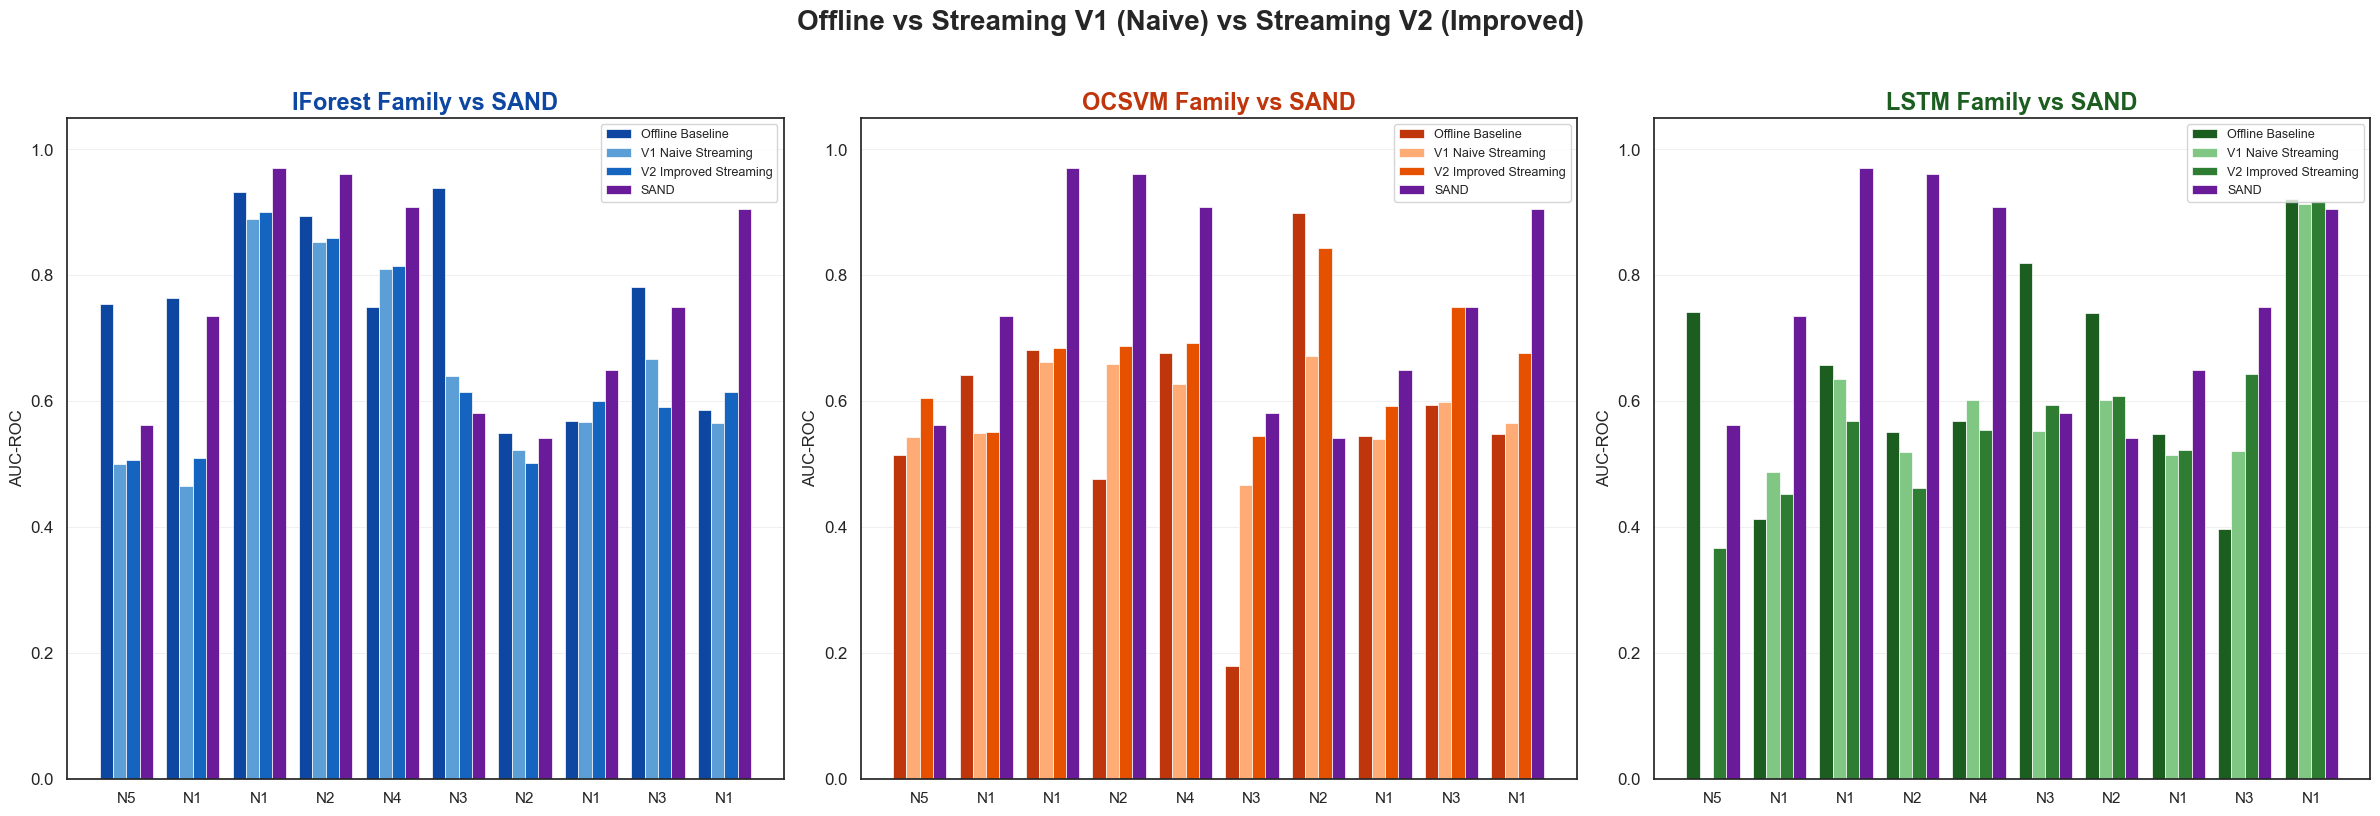

Saved: poster_streaming_improvement.png


In [44]:
import re
# --- Poster Plot 3: Offline vs V1 vs V2 per Method Family ---
SAND_COLOR = '#6A1B9A'
families = [
    ('IForest', 'IF Offline',    'IF Naive',    'IF Drift',       '#0D47A1', '#5C9FD6', '#1565C0'),
    ('OCSVM',   'OCSVM Offline', 'OCSVM Naive', 'OCSVM KMeans',   '#BF360C', '#FFAB76', '#E65100'),
    ('LSTM',    'LSTM Offline',  'LSTM Naive',  'LSTM ExpReplay', '#1B5E20', '#81C784', '#2E7D32'),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
fig.patch.set_facecolor('none')

for ax, (family, off_n, v1_n, v2_n, c_off, c_v1, c_v2) in zip(axes, families):
    sub    = all_df[all_df['Method'].isin([off_n, v1_n, v2_n, 'SAND'])].copy()
    pivot  = sub.pivot_table(index='dataset_label', columns='Method', values='AUC_ROC', aggfunc='mean')
    ds     = list(pivot.index)
    x      = np.arange(len(ds))
    w      = 0.2

    def gv(col):
        return pivot[col].values if col in pivot.columns else np.zeros(len(ds))

    ax.bar(x - 1.5*w, gv(off_n),  w, label='Offline Baseline',      color=c_off,      edgecolor='white', linewidth=0.5)
    ax.bar(x - 0.5*w, gv(v1_n),   w, label='V1 Naive Streaming',    color=c_v1,       edgecolor='white', linewidth=0.5)
    ax.bar(x + 0.5*w, gv(v2_n),   w, label='V2 Improved Streaming', color=c_v2,       edgecolor='white', linewidth=0.5)
    ax.bar(x + 1.5*w, gv('SAND'), w, label='SAND',                  color=SAND_COLOR, edgecolor='white', linewidth=0.5)

    ax.set_title(f'{family} Family vs SAND', fontsize=17, fontweight='bold', color=c_off)
    ax.set_xticks(x)
    short_labels = [re.search(r'N\d', d).group() if re.search(r'N\d', d) else d for d in ds]
    ax.set_xticklabels(short_labels, rotation=0, ha='center', fontsize=11)
    ax.set_ylabel('AUC-ROC', fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(axis='y', alpha=0.3, linewidth=0.7)
    ax.set_facecolor('none')

fig.suptitle('Offline vs Streaming V1 (Naive) vs Streaming V2 (Improved)',
             fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_streaming_improvement.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: poster_streaming_improvement.png")

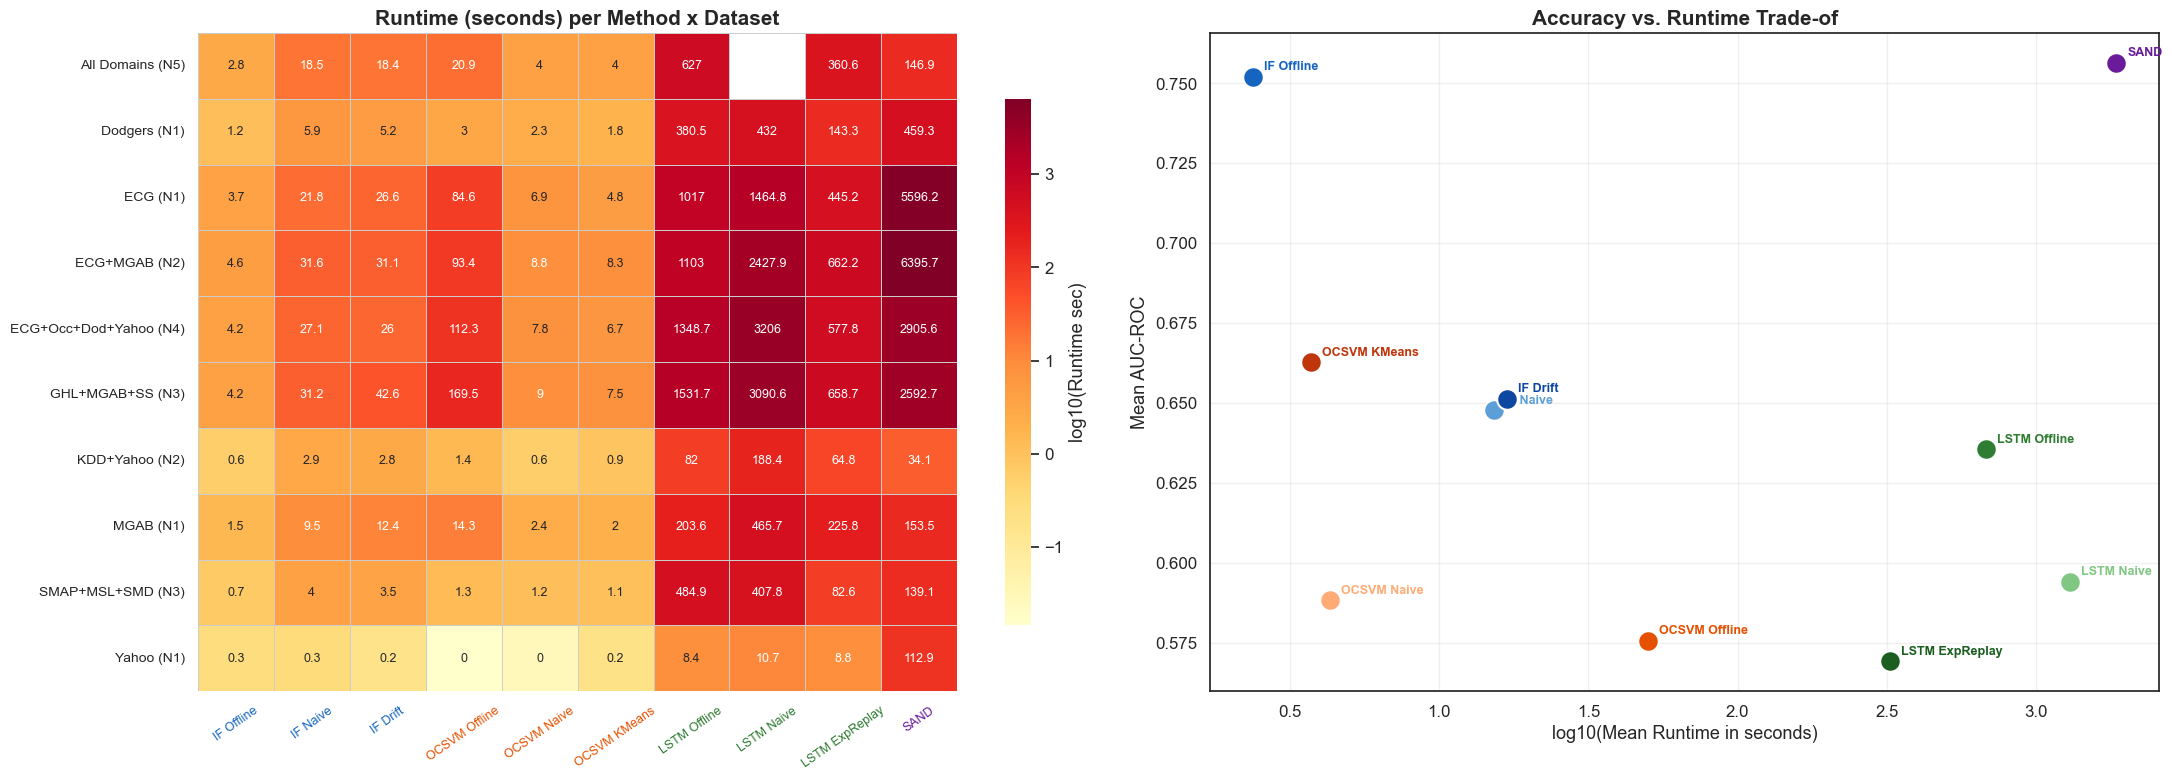

Saved: poster_runtime_analysis.png


In [30]:
# --- Poster Plot 4: Runtime Heatmap + Accuracy vs Runtime Scatter ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))

pivot_rt = all_df.pivot_table(index='dataset_label', columns='Method', values='runtime', aggfunc='mean')
pivot_rt = pivot_rt[[c for c in METHOD_ORDER if c in pivot_rt.columns]]
log_rt   = np.log10(pivot_rt.clip(lower=0.01))

sns.heatmap(log_rt, ax=ax1, cmap='YlOrRd',
            annot=pivot_rt.round(1), fmt='g', annot_kws={'size': 9},
            linewidths=0.5, linecolor='#cccccc',
            cbar_kws={'label': 'log10(Runtime sec)', 'shrink': 0.8})
ax1.set_title('Runtime (seconds) per Method x Dataset', fontsize=15, fontweight='bold')
ax1.tick_params(axis='x', rotation=35, labelsize=9)
ax1.tick_params(axis='y', rotation=0,  labelsize=10)
ax1.set_xlabel(''); ax1.set_ylabel('')
for tick in ax1.get_xticklabels():
    tick.set_color(TICK_COLORS.get(tick.get_text(), 'black'))

avg_rt  = all_df.groupby('Method')['runtime'].mean()
avg_auc = all_df.groupby('Method')['AUC_ROC'].mean()

for method in METHOD_ORDER:
    if method in avg_rt.index:
        rt  = avg_rt[method]
        auc = avg_auc[method]
        ax2.scatter(np.log10(rt + 0.001), auc, s=220,
                    color=FAMILY_COLORS[method], zorder=5,
                    edgecolors='white', linewidth=1.5)
        ax2.annotate(method, (np.log10(rt + 0.001), auc),
                     textcoords='offset points', xytext=(8, 5),
                     fontsize=9, fontweight='bold',
                     color=FAMILY_COLORS[method])

ax2.set_xlabel('log10(Mean Runtime in seconds)', fontsize=13)
ax2.set_ylabel('Mean AUC-ROC', fontsize=13)
ax2.set_title('Accuracy vs. Runtime Trade-of', fontsize=15, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_runtime_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: poster_runtime_analysis.png")

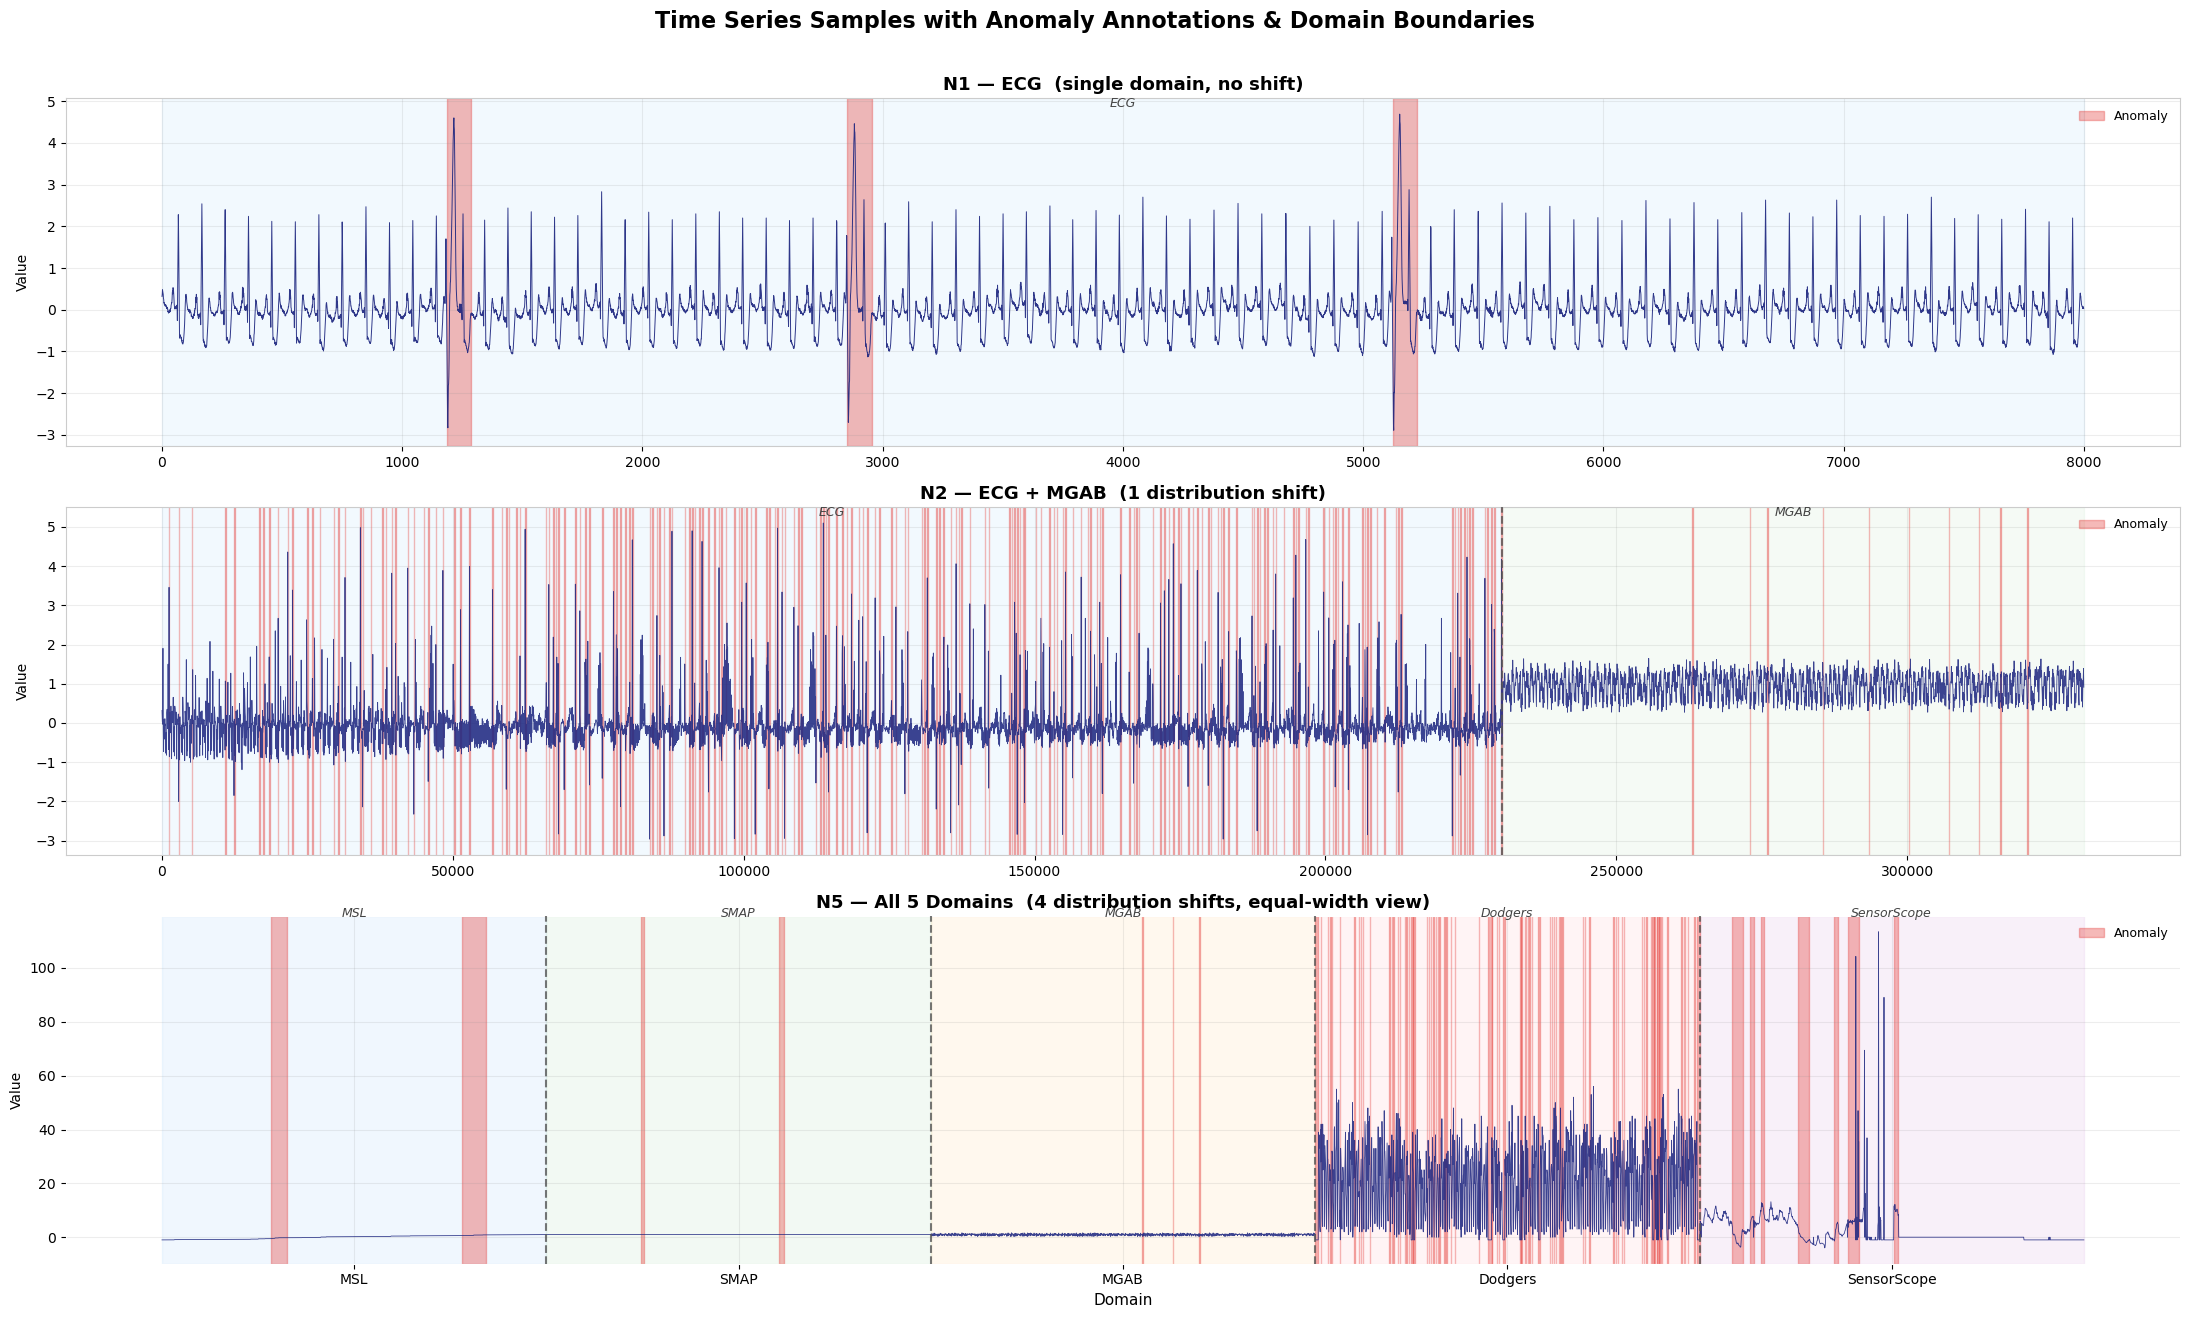

Saved: poster_ts_samples.png


In [23]:
# --- Poster Plot 5: Time Series Sample Visualization ---
# Boundaries computed from loaded dataframes
n2_bounds  = [0, len(ecg), len(ecg) + len(mgab)]
n2_names   = ['ECG', 'MGAB']
n5_bounds  = [0, len(msl), len(msl)+len(smap),
              len(msl)+len(smap)+len(mgab),
              len(msl)+len(smap)+len(mgab)+len(dodgers),
              len(msl)+len(smap)+len(mgab)+len(dodgers)+len(sensorscope)]
n5_names   = ['MSL', 'SMAP', 'MGAB', 'Dodgers', 'SensorScope']

DOM_COLORS = ['#BBDEFB', '#C8E6C9', '#FFE0B2', '#FFCDD2', '#E1BEE7']

fig, axes = plt.subplots(3, 1, figsize=(22, 13))

# ── Row 1: N1 ECG 
ax = axes[0]
df  = pd.read_csv(f'{NORMALITIES_DIR}/ecg.csv', header=None)
ts  = df.iloc[:8000, 0].values.astype(float)
lb  = df.iloc[:8000, 1].values.astype(int)
t   = np.arange(len(ts))
ax.axvspan(0, len(ts), alpha=0.18, color=DOM_COLORS[0], zorder=0)
ax.text(len(ts)/2, ts.max()*1.02, 'ECG', ha='center', va='bottom',
        fontsize=9, color='#444', style='italic')
ax.plot(t, ts, color='#1A237E', linewidth=0.7, alpha=0.9, zorder=2)
in_anom=False; a_start=0; first=True
for idx,l in enumerate(lb):
    if l==1 and not in_anom: a_start=idx; in_anom=True
    elif l==0 and in_anom:
        ax.axvspan(a_start,idx,alpha=0.35,color='#E53935',zorder=1,
                   label='Anomaly' if first else '_nolegend_'); first=False; in_anom=False
if in_anom: ax.axvspan(a_start,len(ts),alpha=0.35,color='#E53935',zorder=1)
ax.set_title('N1 — ECG  (single domain, no shift)', fontsize=13, fontweight='bold', pad=6)
ax.set_ylabel('Value', fontsize=10)
ax.grid(True, alpha=0.15, color='#888')
ax.legend(fontsize=9, loc='upper right', framealpha=0)
for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

# ── Row 2: N2 ECG+MGAB 
ax = axes[1]
df  = pd.read_csv(f'{NORMALITIES_DIR}/ecg_mgab.csv', header=None)
ts  = df.iloc[:, 0].values.astype(float)
lb  = df.iloc[:, 1].values.astype(int)
n   = len(ts)
step = max(1, n // 6000)
t   = np.arange(n)
for i,(name,col) in enumerate(zip(n2_names, DOM_COLORS)):
    x0d, x1d = n2_bounds[i], min(n2_bounds[i+1], n)
    ax.axvspan(x0d, x1d, alpha=0.18, color=col, zorder=0)
    ax.text((x0d+x1d)/2, ts[::step].max()*1.02, name, ha='center',
            va='bottom', fontsize=9, color='#444', style='italic')
for b in n2_bounds[1:-1]:
    if b < n: ax.axvline(x=b, color='#555', linewidth=1.5, linestyle='--', alpha=0.8, zorder=3)
ax.plot(t[::step], ts[::step], color='#1A237E', linewidth=0.6, alpha=0.85, zorder=2)
in_anom=False; a_start=0; first=True
for idx,l in enumerate(lb):
    if l==1 and not in_anom: a_start=idx; in_anom=True
    elif l==0 and in_anom:
        ax.axvspan(a_start,idx,alpha=0.35,color='#E53935',zorder=1,
                   label='Anomaly' if first else '_nolegend_'); first=False; in_anom=False
if in_anom: ax.axvspan(a_start,n,alpha=0.35,color='#E53935',zorder=1)
ax.set_title('N2 — ECG + MGAB  (1 distribution shift)', fontsize=13, fontweight='bold', pad=6)
ax.set_ylabel('Value', fontsize=10)
ax.grid(True, alpha=0.15, color='#888')
ax.legend(fontsize=9, loc='upper right', framealpha=0)
for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

# ── Row 3: N5 — equal-width domains 
ax = axes[2]
df  = pd.read_csv(f'{NORMALITIES_DIR}/msl_smap_mgab_dodgers_sensorscope.csv', header=None)
full_ts = df.iloc[:, 0].values.astype(float)
full_lb = df.iloc[:, 1].values.astype(int)

PTS_PER_DOM = 1200   # each domain rendered as this many points
n_domains   = len(n5_names)
total_pts   = PTS_PER_DOM * n_domains
x_plot      = np.linspace(0, total_pts, total_pts)

ts_norm, lb_norm = [], []
for i in range(n_domains):
    seg_ts = full_ts[n5_bounds[i]:n5_bounds[i+1]]
    seg_lb = full_lb[n5_bounds[i]:n5_bounds[i+1]]
    idx    = np.linspace(0, len(seg_ts)-1, PTS_PER_DOM).astype(int)
    ts_norm.append(seg_ts[idx])
    lb_norm.append(seg_lb[idx])
ts_plot = np.concatenate(ts_norm)
lb_plot = np.concatenate(lb_norm)

for i,(name,col) in enumerate(zip(n5_names, DOM_COLORS)):
    x0d = i * PTS_PER_DOM
    x1d = (i+1) * PTS_PER_DOM
    ax.axvspan(x0d, x1d, alpha=0.22, color=col, zorder=0)
    ax.text((x0d+x1d)/2, ts_plot.max()*1.04, name, ha='center',
            va='bottom', fontsize=9, color='#444', style='italic')

for i in range(1, n_domains):
    ax.axvline(x=i*PTS_PER_DOM, color='#555', linewidth=1.5, linestyle='--', alpha=0.8, zorder=3)

ax.plot(x_plot, ts_plot, color='#1A237E', linewidth=0.6, alpha=0.85, zorder=2)

in_anom=False; a_start=0; first=True
for idx,l in enumerate(lb_plot):
    if l==1 and not in_anom: a_start=idx; in_anom=True
    elif l==0 and in_anom:
        ax.axvspan(a_start,idx,alpha=0.35,color='#E53935',zorder=1,
                   label='Anomaly' if first else '_nolegend_'); first=False; in_anom=False
if in_anom: ax.axvspan(a_start,total_pts,alpha=0.35,color='#E53935',zorder=1)

# x-axis ticks at domain midpoints showing domain name
ax.set_xticks([(i+0.5)*PTS_PER_DOM for i in range(n_domains)])
ax.set_xticklabels(n5_names, fontsize=10)
ax.set_title('N5 — All 5 Domains  (4 distribution shifts, equal-width view)',
             fontsize=13, fontweight='bold', pad=6)
ax.set_ylabel('Value', fontsize=10)
ax.grid(True, alpha=0.15, color='#888')
ax.legend(fontsize=9, loc='upper right', framealpha=0)
for spine in ax.spines.values(): spine.set_edgecolor("#ffffff")

axes[-1].set_xlabel('Domain', fontsize=11)
fig.suptitle('Time Series Samples with Anomaly Annotations & Domain Boundaries',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_ts_samples.png', dpi=150, bbox_inches='tight', transparent=False)
plt.show()
print("Saved: poster_ts_samples.png")

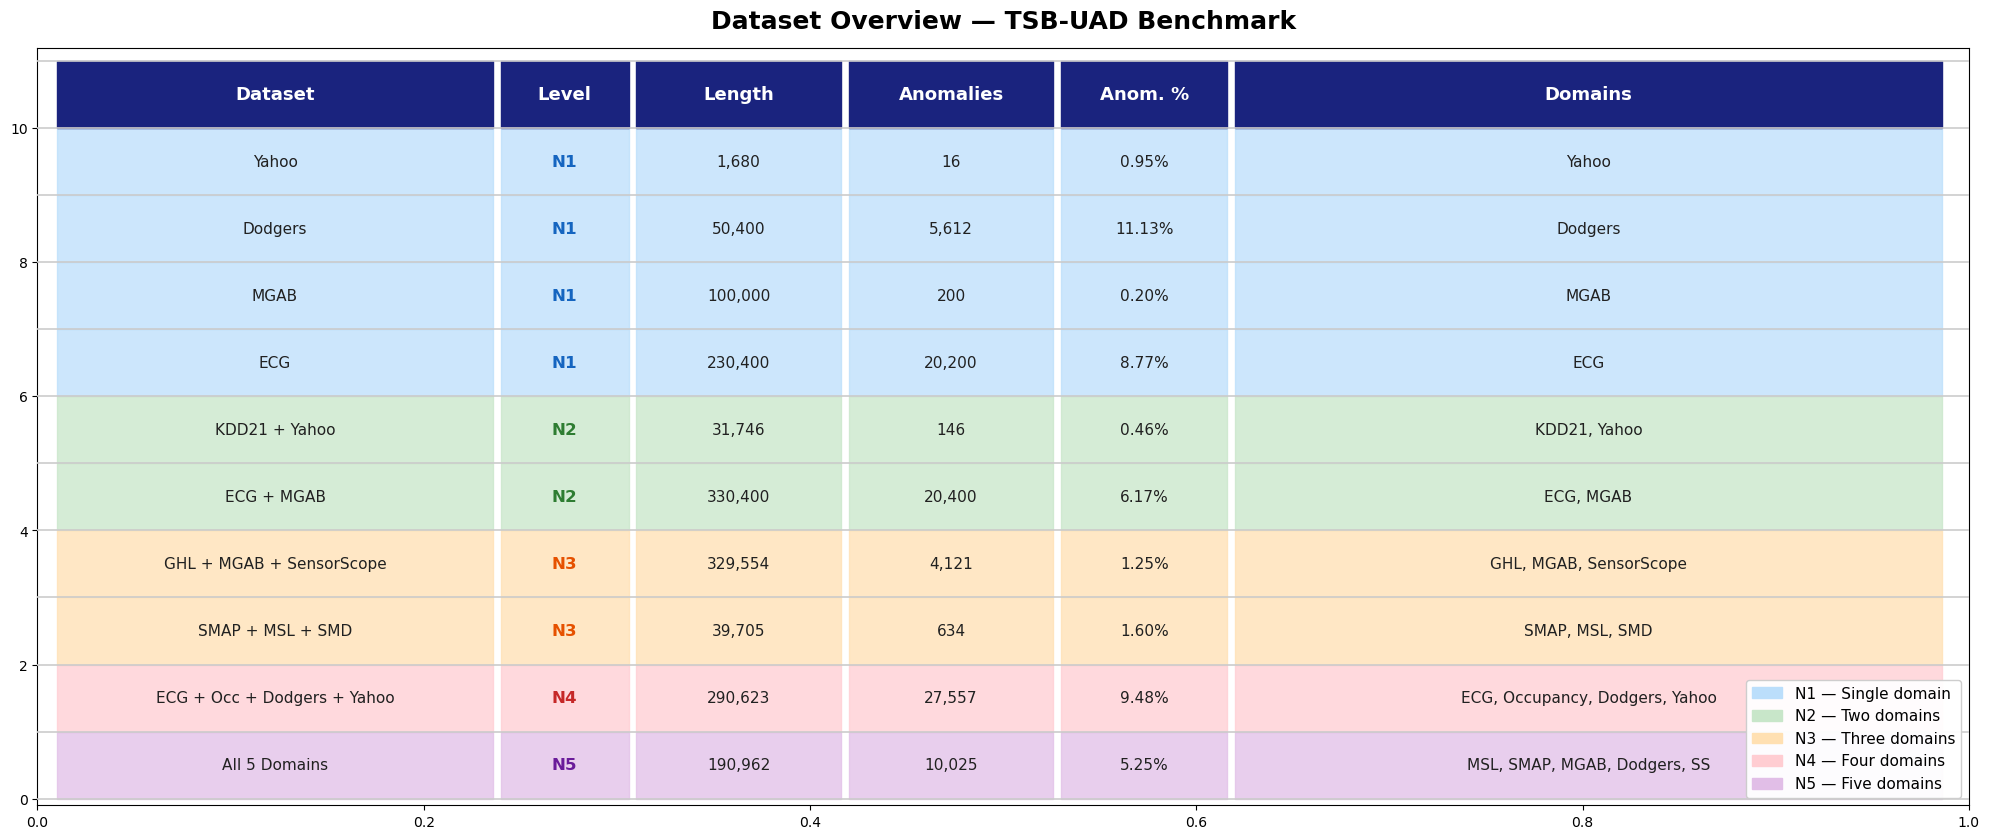

Saved: poster_dataset_table.png


In [23]:
# --- Poster Plot 6: Dataset Summary Table ---

LEVEL_COLORS = {
    'N1': '#BBDEFB',
    'N2': '#C8E6C9',
    'N3': '#FFE0B2',
    'N4': '#FFCDD2',
    'N5': '#E1BEE7',
}
LEVEL_DARK = {
    'N1': '#1565C0',
    'N2': '#2E7D32',
    'N3': '#E65100',
    'N4': '#C62828',
    'N5': '#6A1B9A',
}

DATASET_META = {
    'yahoo':                 ('N1', 'Yahoo'),
    'dodgers':               ('N1', 'Dodgers'),
    'mgab':                  ('N1', 'MGAB'),
    'ecg':                   ('N1', 'ECG'),
    'kdd21_yahoo':           ('N2', 'KDD21, Yahoo'),
    'ecg_mgab':              ('N2', 'ECG, MGAB'),
    'ghl_mgab_sen':          ('N3', 'GHL, MGAB, SensorScope'),
    'smap_msl_smd':          ('N3', 'SMAP, MSL, SMD'),
    'ecg_occ_dod_yahoo':     ('N4', 'ECG, Occupancy, Dodgers, Yahoo'),
    'msl_smap_mgab_dod_sen': ('N5', 'MSL, SMAP, MGAB, Dodgers, SS'),
}

NAME_DISPLAY = {
    'yahoo':                 'Yahoo',
    'dodgers':               'Dodgers',
    'mgab':                  'MGAB',
    'ecg':                   'ECG',
    'kdd21_yahoo':           'KDD21 + Yahoo',
    'ecg_mgab':              'ECG + MGAB',
    'ghl_mgab_sen':          'GHL + MGAB + SensorScope',
    'smap_msl_smd':          'SMAP + MSL + SMD',
    'ecg_occ_dod_yahoo':     'ECG + Occ + Dodgers + Yahoo',
    'msl_smap_mgab_dod_sen': 'All 5 Domains',
}

rows = []
row_levels = []
for name,_, df in datasets:
    ts     = df.iloc[:, 0].values
    lb     = df.iloc[:, 1].values.astype(int)
    length = len(ts)
    n_anom = int(lb.sum())
    pct    = f"{100 * n_anom / length:.2f}%"
    level, domains = DATASET_META.get(name, ('?', name))
    display = NAME_DISPLAY.get(name, name)
    rows.append([display, level, f"{length:,}", f"{n_anom:,}", pct, domains])
    row_levels.append(level)

COL_LABELS = ['Dataset', 'Level', 'Length', 'Anomalies', 'Anom. %', 'Domains']
COL_WIDTHS = [0.23, 0.07, 0.11, 0.11, 0.09, 0.37]

n_rows = len(rows)
fig, ax = plt.subplots(figsize=(20, 0.72 * (n_rows + 1.8)))
fig.patch.set_facecolor('none')
ax.set_facecolor('none')
ax.set_xlim(0, 1)
ax.set_ylim(-0.1, n_rows + 1.2)
ax.axis('on')

HEADER_BG = '#1A237E'
x0 = 0.01

# Header row
x = x0
for col, w in zip(COL_LABELS, COL_WIDTHS):
    ax.add_patch(plt.Rectangle((x, n_rows), w - 0.004, 1.0,
                                color=HEADER_BG, zorder=2, clip_on=False))
    ax.text(x + (w - 0.004) / 2, n_rows + 0.5, col,
            ha='center', va='center', fontsize=13, fontweight='bold',
            color='white', zorder=3)
    x += w

# Data rows
for ri, (row_data, level) in enumerate(zip(rows, row_levels)):
    y  = n_rows - 1 - ri
    bg = LEVEL_COLORS.get(level, '#e9e5ff')
    x  = x0
    for ci, (val, w) in enumerate(zip(row_data, COL_WIDTHS)):
        ax.add_patch(plt.Rectangle((x, y), w - 0.004, 1.0,
                                    color=bg, zorder=1, alpha=0.75, clip_on=False))
        if ci == 1:
            ax.text(x + (w - 0.004) / 2, y + 0.5, val,
                    ha='center', va='center', fontsize=12, fontweight='bold',
                    color=LEVEL_DARK.get(level, 'black'), zorder=3)
        else:
            ax.text(x + (w - 0.004) / 2, y + 0.5, val,
                    ha='center', va='center', fontsize=11, color='#212121', zorder=3)
        x += w

# Horizontal dividers
for ri in range(n_rows + 2):
    ax.axhline(y=ri, color='#cccccc', linewidth=1.2, zorder=4)

ax.set_title('Dataset Overview — TSB-UAD Benchmark',
             fontsize=18, fontweight='bold', pad=14)

legend_patches = [
    mpatches.Patch(color=LEVEL_COLORS['N1'], label='N1 — Single domain'),
    mpatches.Patch(color=LEVEL_COLORS['N2'], label='N2 — Two domains'),
    mpatches.Patch(color=LEVEL_COLORS['N3'], label='N3 — Three domains'),
    mpatches.Patch(color=LEVEL_COLORS['N4'], label='N4 — Four domains'),
    mpatches.Patch(color=LEVEL_COLORS['N5'], label='N5 — Five domains'),
]
ax.legend(handles=legend_patches, fontsize=11, framealpha=0.95,
          bbox_to_anchor=(1.0, 0.0), loc='lower right')

plt.tight_layout()
fig.savefig(PLOT_DIR + 'poster_dataset_table.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
print("Saved: poster_dataset_table.png")

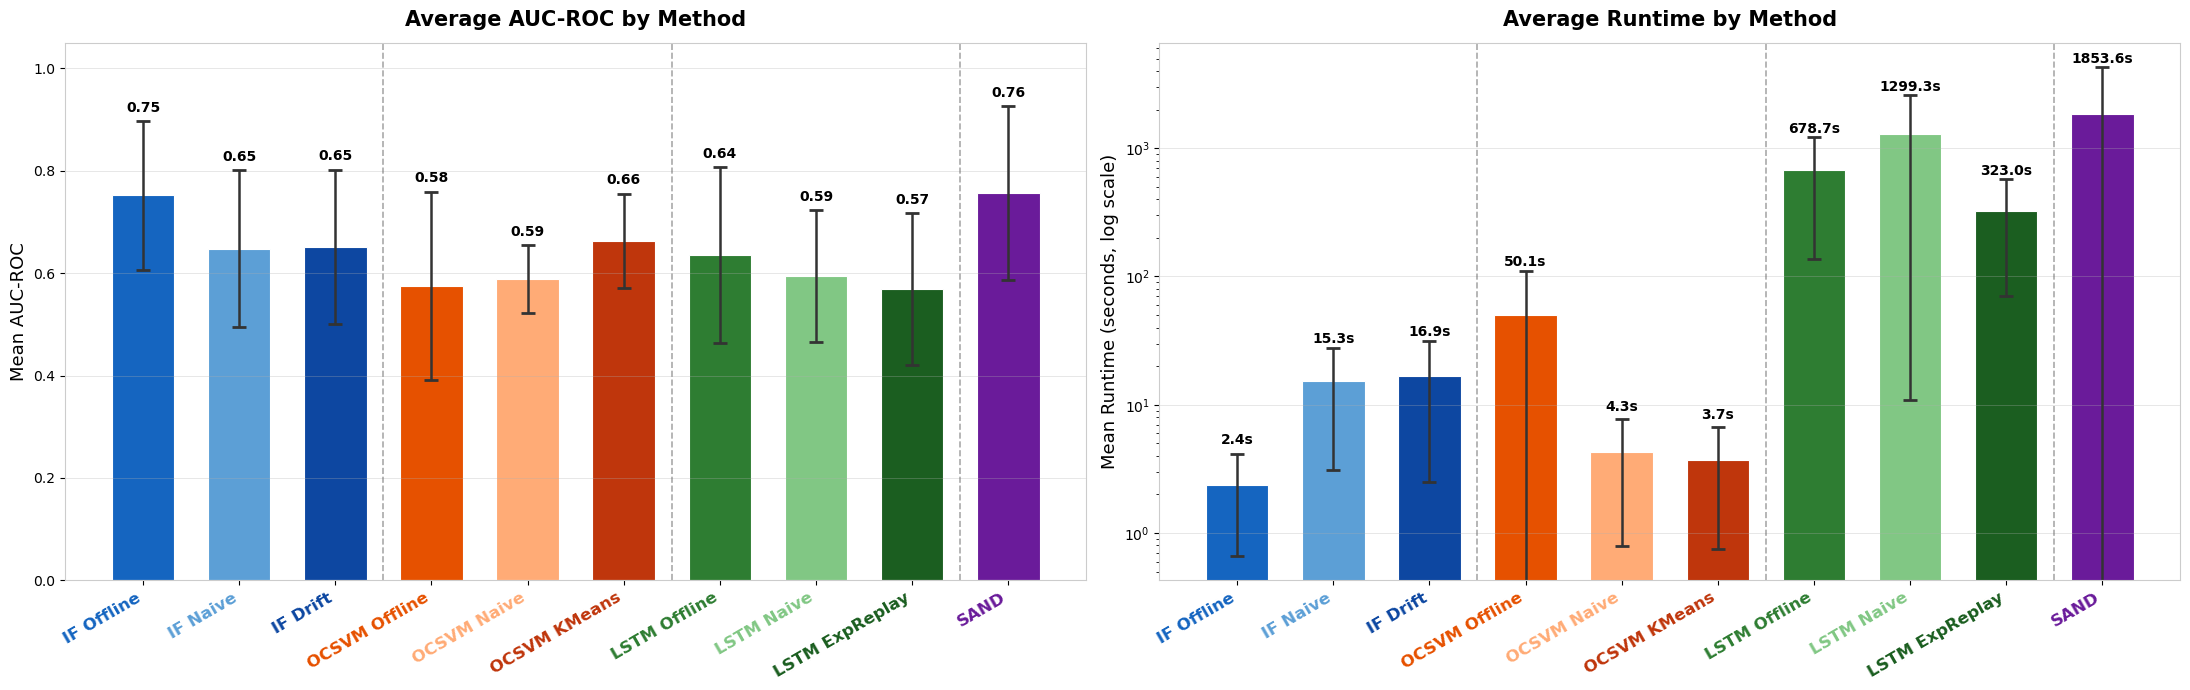

Saved: poster_avg_perf_runtime.png


In [ ]:
# --- Avg AUC-ROC + Avg Runtime side-by-side ---
avg_auc = all_df.groupby("Method")["AUC_ROC"].agg(["mean","std"]).reindex(METHOD_ORDER)
avg_rt  = all_df.groupby("Method")["runtime"].agg(["mean","std"]).reindex(METHOD_ORDER)
colors  = [FAMILY_COLORS[m] for m in METHOD_ORDER]
x       = np.arange(len(METHOD_ORDER))
w       = 0.65

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 7), sharey=False)
fig.patch.set_facecolor("none")

for ax in (ax1, ax2):
    ax.set_facecolor("none")
    ax.set_xticks(x)
    ax.set_xticklabels(METHOD_ORDER, rotation=30, ha="right", fontsize=12)
    for tick, method in zip(ax.get_xticklabels(), METHOD_ORDER):
        tick.set_color(FAMILY_COLORS[method]); tick.set_weight("bold")
    for xsep in [2.5, 5.5, 8.5]:
        ax.axvline(x=xsep, color="#555555", linewidth=1.2, linestyle="--", alpha=0.5)
    ax.grid(axis="y", alpha=0.3, linewidth=0.7)
    for spine in ax.spines.values():
        spine.set_edgecolor("#cccccc")

# Left: AUC-ROC
bars1 = ax1.bar(x, avg_auc["mean"], yerr=avg_auc["std"], capsize=5,
                color=colors, edgecolor="white", linewidth=0.8, width=w,
                error_kw={"linewidth":1.8, "ecolor":"#333", "capthick":2})
for bar, (_, row) in zip(bars1, avg_auc.iterrows()):
    ax1.text(bar.get_x()+bar.get_width()/2, row["mean"]+row["std"]+0.012,
             f"{row['mean']:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 1.05)
ax1.set_ylabel("Mean AUC-ROC", fontsize=13)
ax1.set_title("Average AUC-ROC by Method", fontsize=15, fontweight="bold", pad=12)

# Right: Runtime (log scale)
bars2 = ax2.bar(x, avg_rt["mean"], yerr=avg_rt["std"], capsize=5,
                color=colors, edgecolor="white", linewidth=0.8, width=w,
                error_kw={"linewidth":1.8, "ecolor":"#333", "capthick":2})
for bar, (_, row) in zip(bars2, avg_rt.iterrows()):
    ax2.text(bar.get_x()+bar.get_width()/2, row["mean"]+row["std"]*1.05+0.5,
             f"{row['mean']:.1f}s", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax2.set_yscale("log")
ax2.set_ylabel("Mean Runtime (seconds, log scale)", fontsize=13)
ax2.set_title("Average Runtime by Method", fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()
fig.savefig(PLOTS_DIR + "/poster_avg_perf_runtime.png", dpi=150, bbox_inches="tight", transparent=True)
plt.show()
print("Saved: poster_avg_perf_runtime.png")